In [1]:
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn
import os
import numpy as np
import random
import scipy
import sys
import itertools
from numba import njit
from scipy.stats import bootstrap

sys.path.append(os.path.join(os.path.dirname(
    os.path.abspath(''))))
import common.plots as plots
sys.path.append(os.path.join(os.path.dirname(
    os.path.abspath('')),  "..", ".."))
import statistics_python.src.statistics_observables as stat

In [2]:
df1 = pd.read_csv('/home/ilya/soft/lattice/observables/result/merged/polyakov_loop/polyakov_loops.csv')
df1['owner'] = 'Ilya'
df1['lambda'] = 0.00075
df1['stout_steps'] = 2
df1['calc_type'] = 'calc'
df1['rho'] = 0.15
df1['ma'] = 0.0075
df1 = df1[df1['Ns'] == 32]
df1 = df1[~df1['Nt'].isin([17, 19])]
df2 = pd.read_csv('/home/ilya/soft/lattice/observables/result/vladimir_data/merged/polyakov_loop/polyakov_loops.csv')
df2['owner'] = 'Vladimir'
df = pd.concat([df1, df2], ignore_index=True)
df = df[df['mu'].isin([0, 0.03, 0.05, 0.07, 0.1, 0.12, 0.15, 0.2, 0.25, 0.3])]
df = df[df['HYP'] == 10]
df['PL'] = df['PL'] * (1.017 ** df['Nt'])
fm_to_GeV = 1/0.197327
a = 0.048 * fm_to_GeV / 1000
df['T'] = 1 / (df['Nt'] * a)
df = df[(df['rho'] == 0.15) & (df['ma'] == 0.0075) & (df['calc_type'] == 'calc')]
df = df[(df['conf'] >= 200) & (df['chain'] == 's0') | (df['chain'] != 's0')]
print(df)

         HYP        PL  Nt  Ns    mu chain  conf     owner   lambda  \
1660      10  0.245868  20  32  0.15    s0   200      Ilya  0.00075   
1671      10  0.270677  20  32  0.15    s0   201      Ilya  0.00075   
1682      10  0.238832  20  32  0.15    s0   202      Ilya  0.00075   
1693      10  0.219178  20  32  0.15    s0   203      Ilya  0.00075   
1704      10  0.205491  20  32  0.15    s0   204      Ilya  0.00075   
...      ...       ...  ..  ..   ...   ...   ...       ...      ...   
8114168   10  0.873657   6  32  0.00    s2   996  Vladimir  0.00075   
8114179   10  0.896314   6  32  0.00    s2   997  Vladimir  0.00075   
8114190   10  0.903728   6  32  0.00    s2   998  Vladimir  0.00075   
8114201   10  0.908448   6  32  0.00    s2   999  Vladimir  0.00075   
8114212   10  0.902561   6  32  0.00    s2  1000  Vladimir  0.00075   

         stout_steps calc_type   rho      ma           T  
1660               2      calc  0.15  0.0075  205.548958  
1671               2      cal

In [3]:
def enumerate(df):
    chains = np.sort(df['chain'].unique())
    enumeration = []
    addition = 0
    for chain in chains:
        tmp = df[df['chain'] == chain]['conf'].to_list()
        enumeration_tmp = np.sort(tmp) + addition
        enumeration.extend(enumeration_tmp)
        addition += np.sort(tmp)[-1] + 1
    df = df.sort_values(by=['chain', 'conf'])
    df['enumeration'] = enumeration
    return df

In [4]:
df1 = df.groupby(['HYP', 'Nt', 'Ns', 'mu', 'owner', 'lambda', 'stout_steps', 'calc_type', 'rho', 'ma', 'T']).apply(enumerate, include_groups=False).reset_index(level=['HYP', 'Nt', 'Ns', 'mu', 'owner', 'lambda', 'stout_steps', 'calc_type', 'rho', 'ma', 'T'])
print(df1[(df1['Nt'] == 24) & (df1['mu'] == 0.2)].to_string())

         HYP  Nt  Ns   mu     owner   lambda  stout_steps calc_type   rho      ma           T        PL chain  conf  enumeration
403391    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.235650    s0   200          200
403402    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.211916    s0   201          201
403413    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.256036    s0   202          202
403424    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.244317    s0   203          203
403435    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.244894    s0   204          204
403446    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.242466    s0   205          205
403457    10  24  32  0.2      Ilya  0.00075            2      calc  0.15  0.0075  171.290799  0.

Nt = 4, mu = 0.0


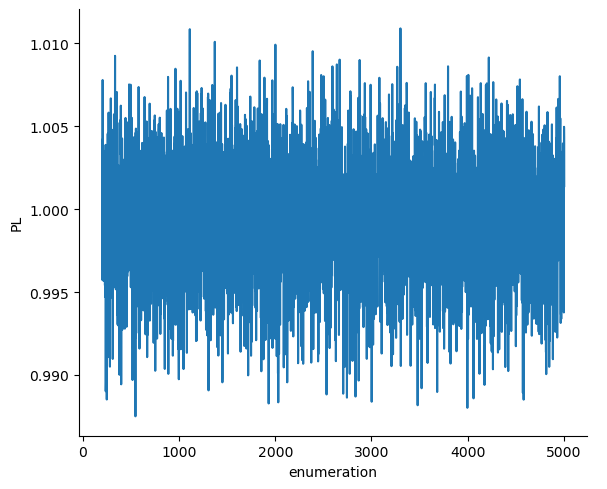

Nt = 6, mu = 0.0


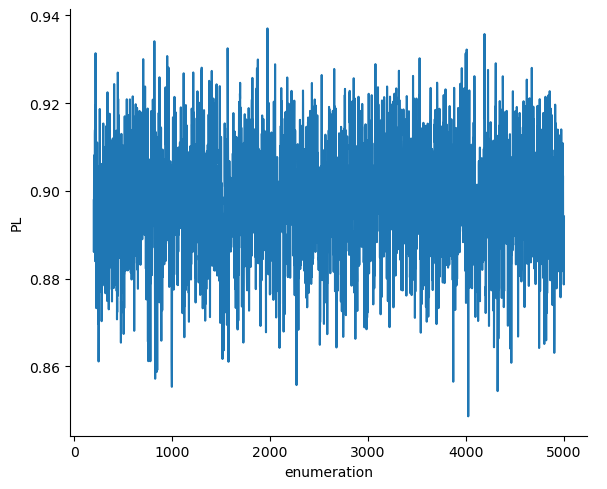

Nt = 8, mu = 0.0


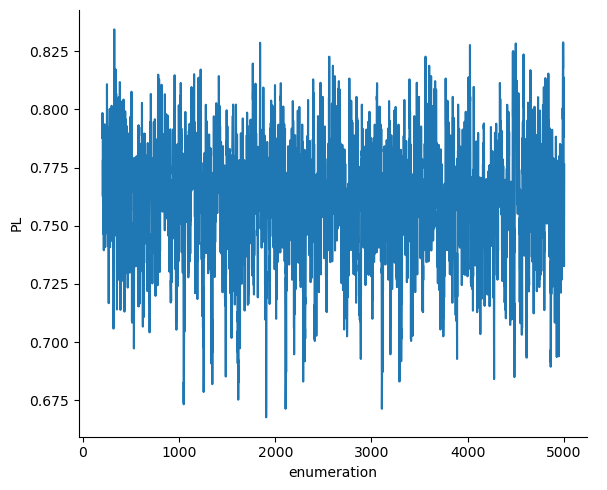

Nt = 8, mu = 0.15


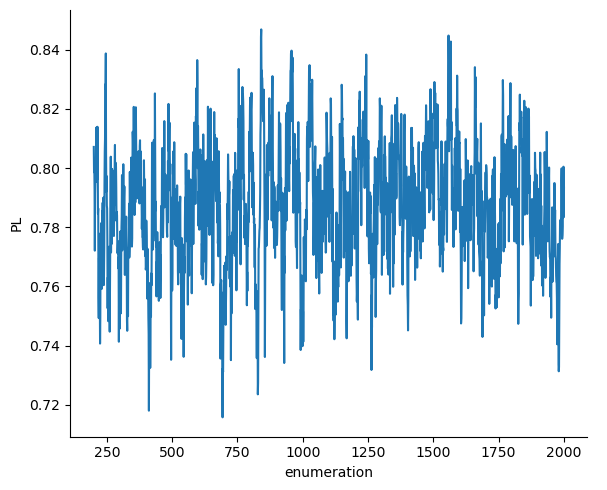

Nt = 10, mu = 0.0


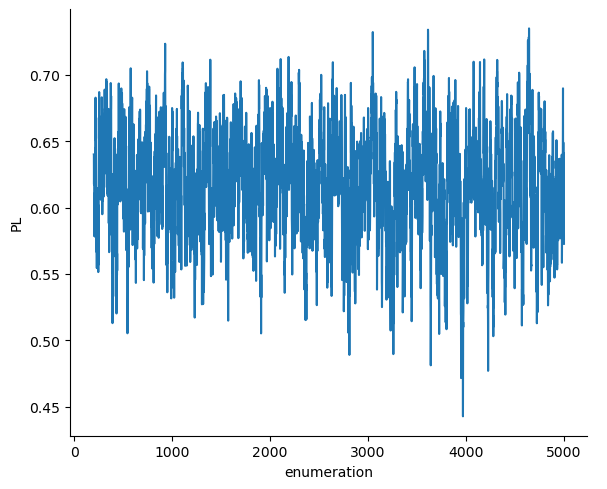

Nt = 10, mu = 0.15


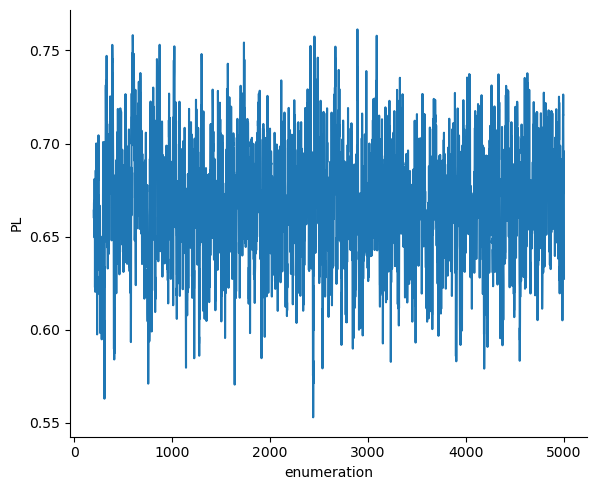

Nt = 10, mu = 0.03


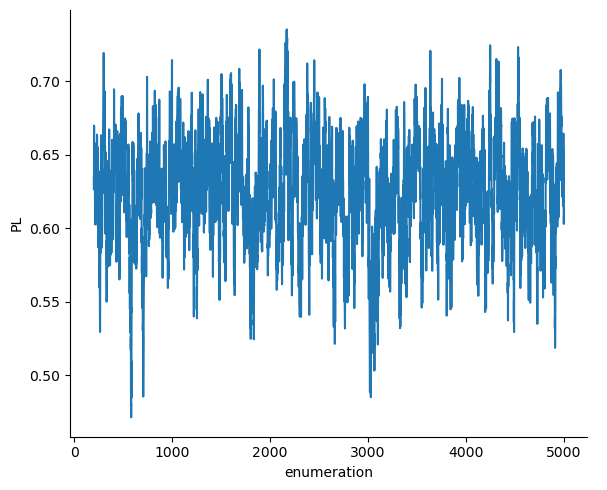

Nt = 10, mu = 0.05


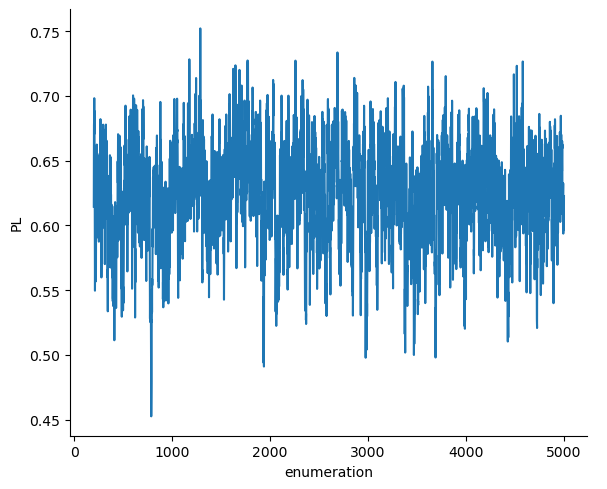

Nt = 10, mu = 0.07


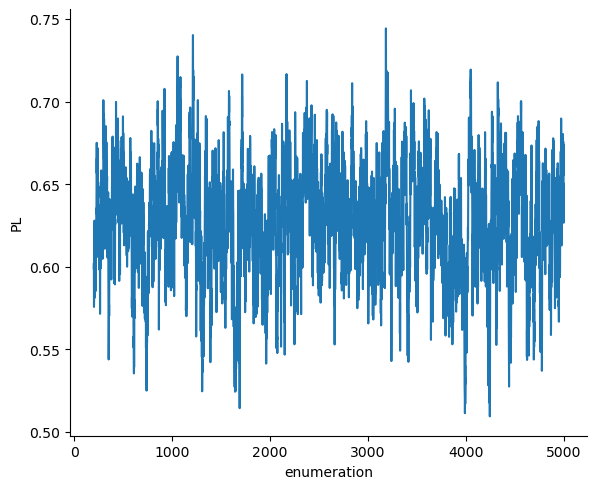

Nt = 10, mu = 0.1


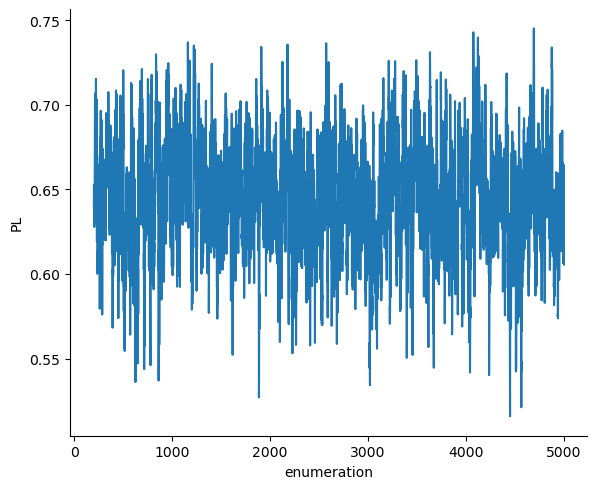

Nt = 10, mu = 0.2


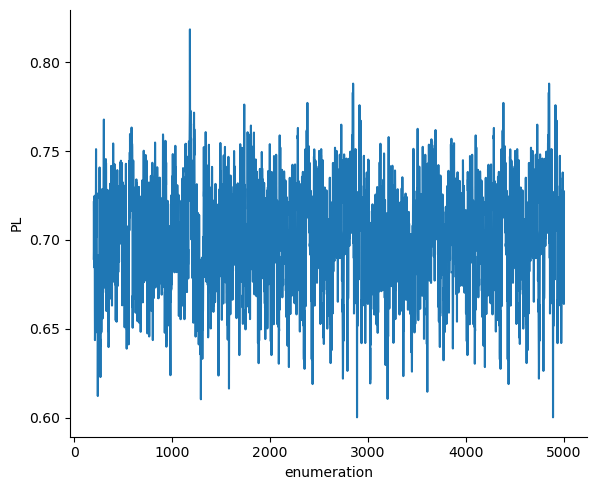

Nt = 10, mu = 0.25


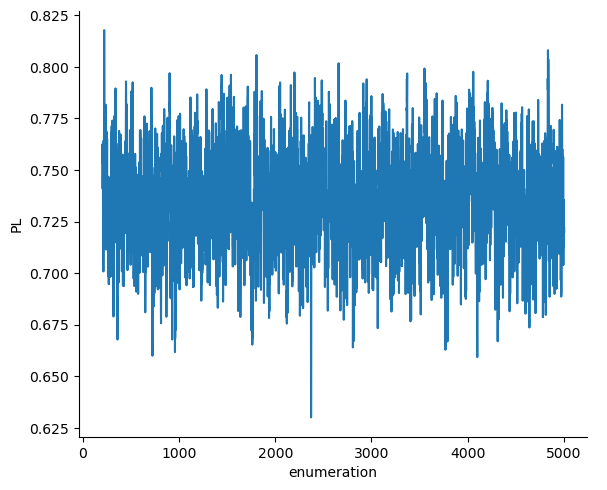

Nt = 10, mu = 0.3


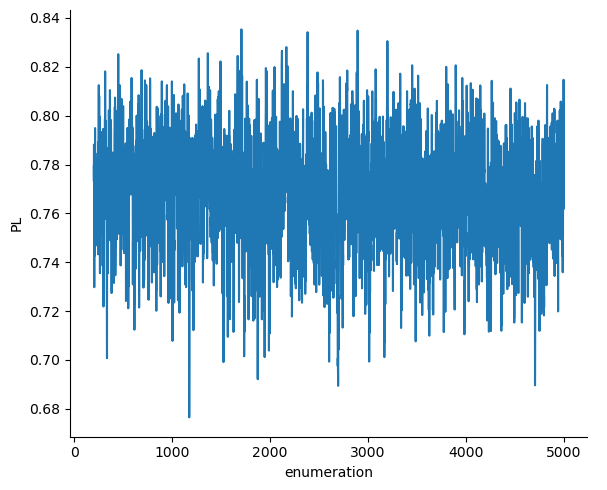

Nt = 12, mu = 0.0


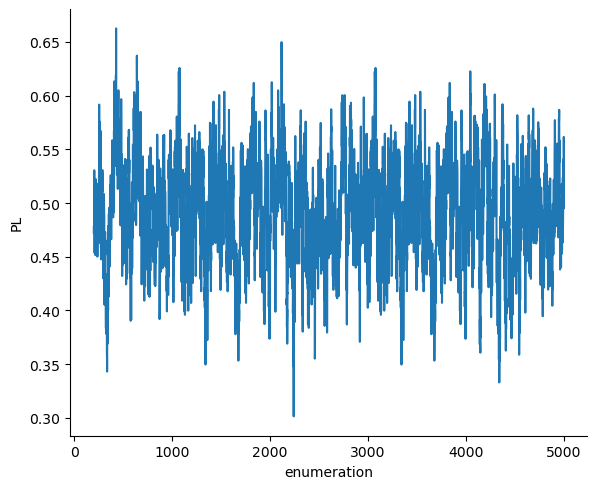

Nt = 12, mu = 0.15


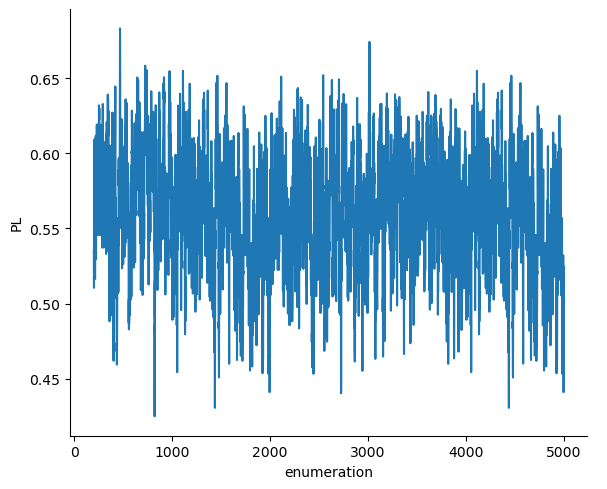

Nt = 12, mu = 0.03


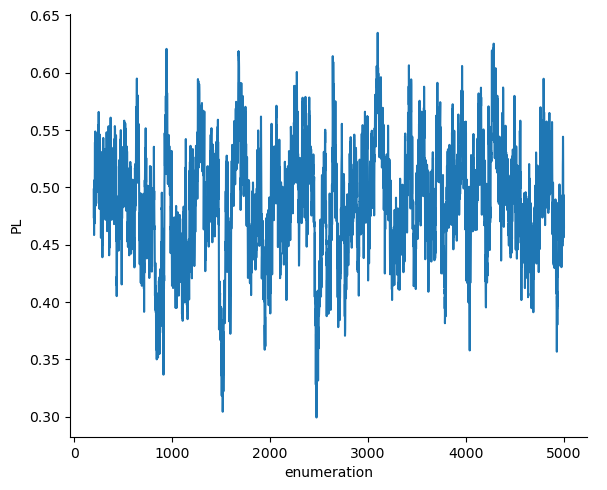

Nt = 12, mu = 0.05


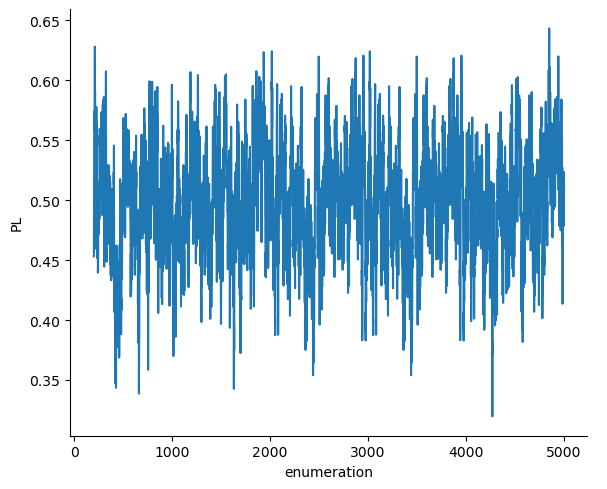

Nt = 12, mu = 0.07


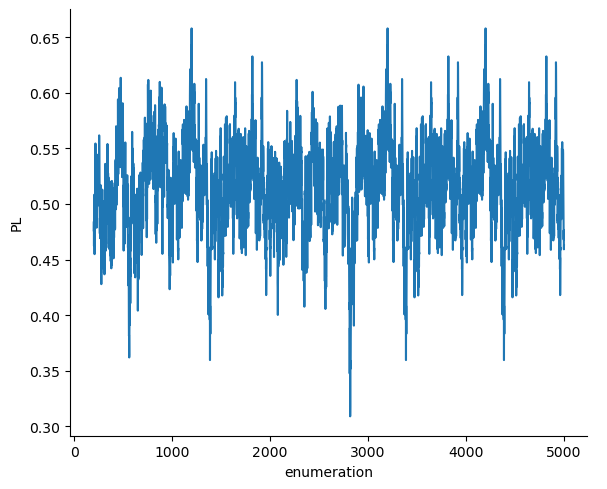

Nt = 12, mu = 0.1


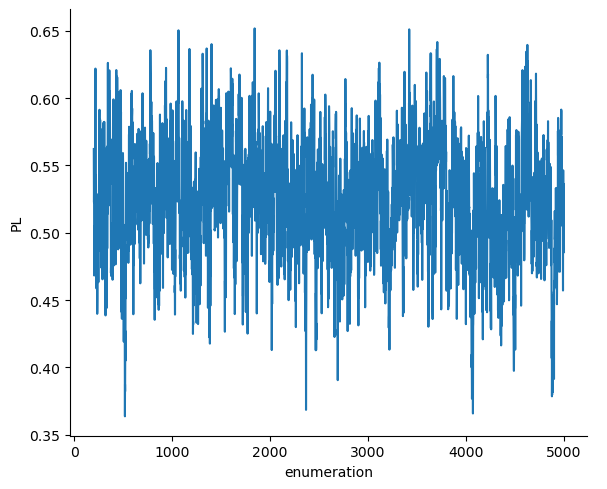

Nt = 12, mu = 0.2


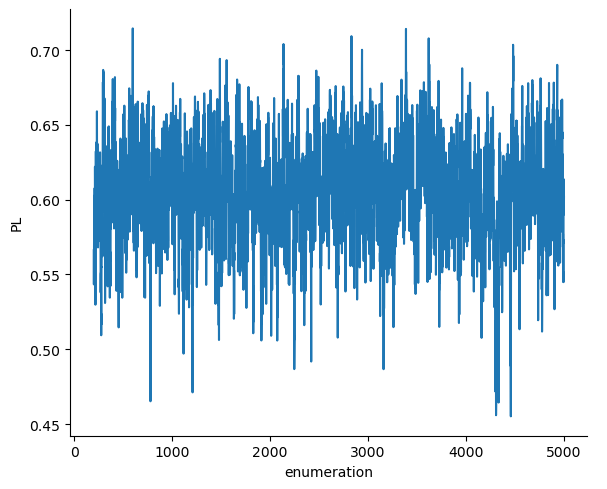

Nt = 12, mu = 0.25


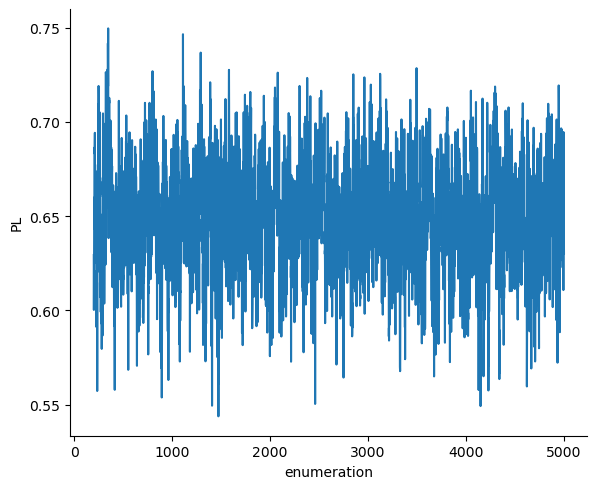

Nt = 12, mu = 0.3


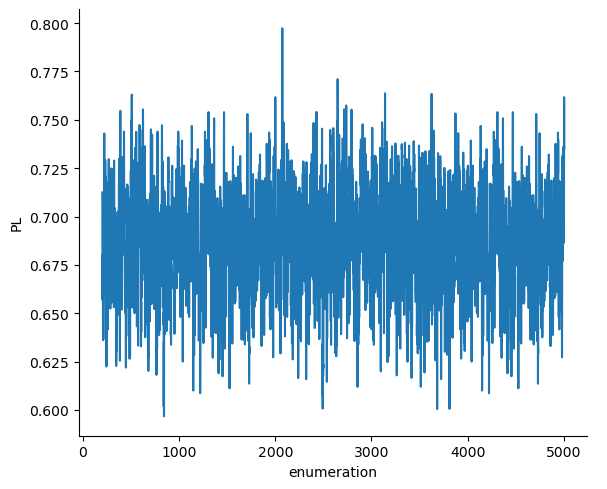

Nt = 14, mu = 0.0


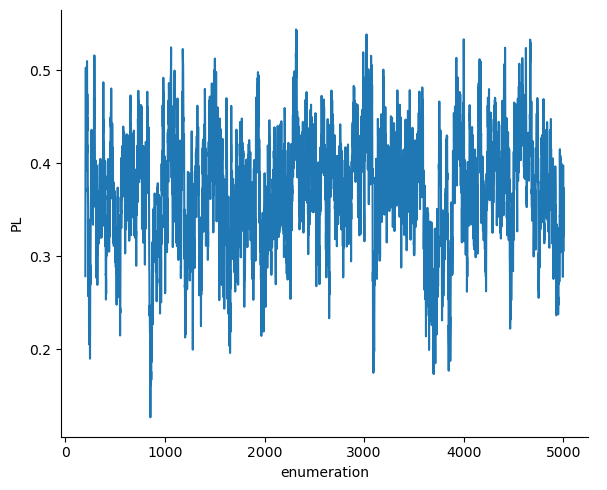

Nt = 14, mu = 0.15


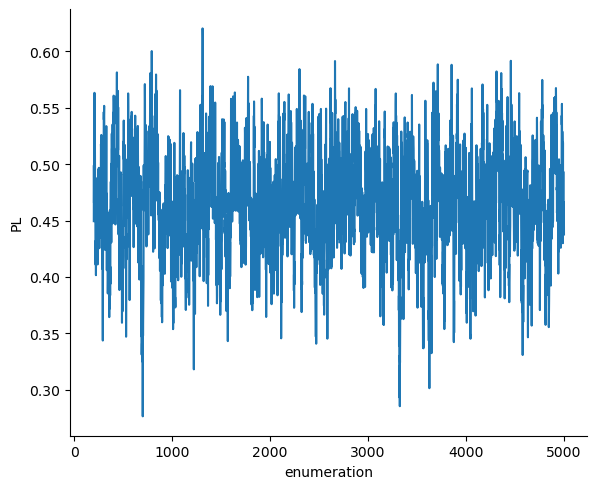

Nt = 14, mu = 0.03


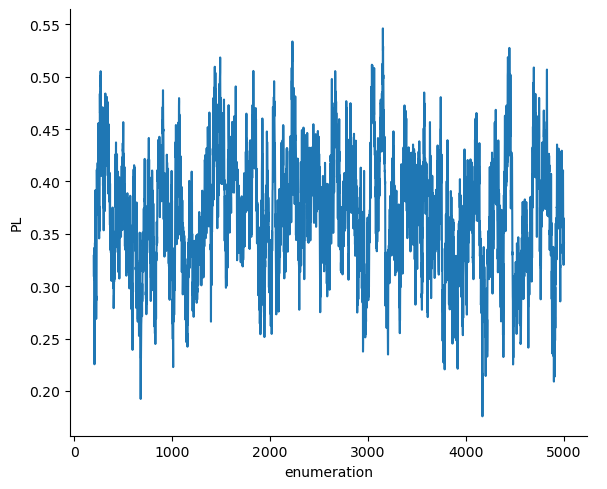

Nt = 14, mu = 0.05


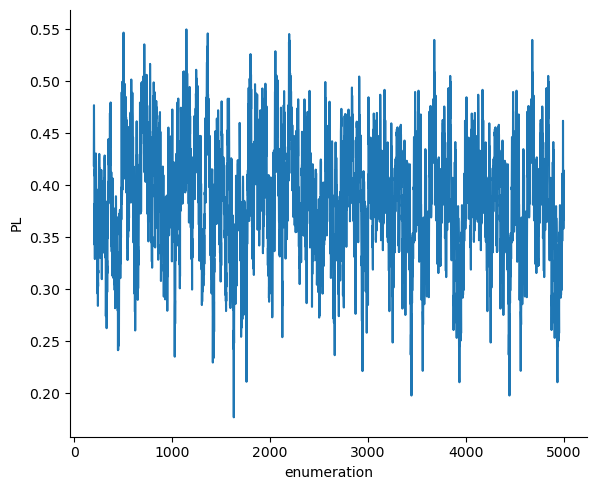

Nt = 14, mu = 0.07


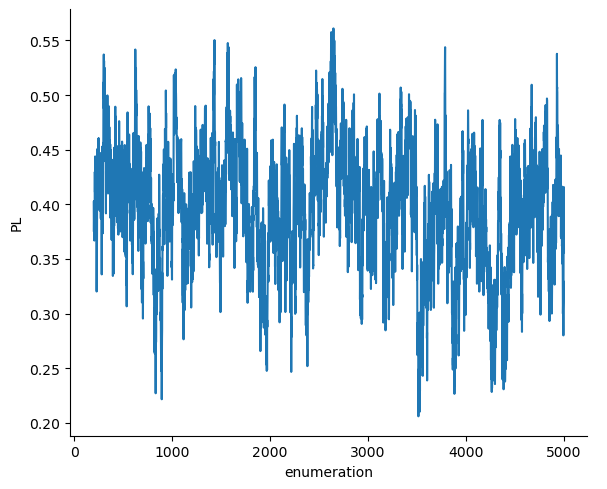

Nt = 14, mu = 0.1


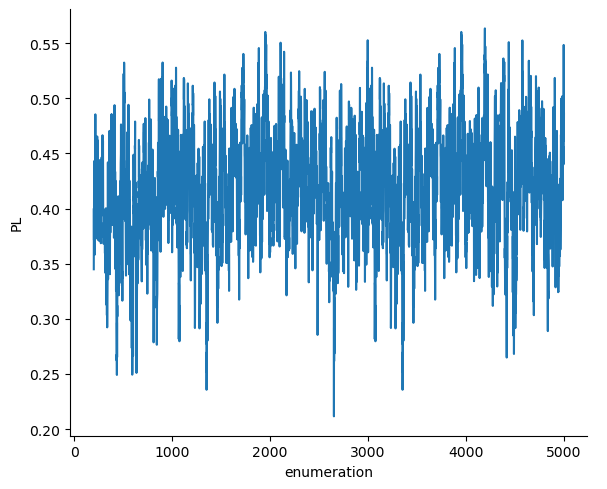

Nt = 14, mu = 0.2


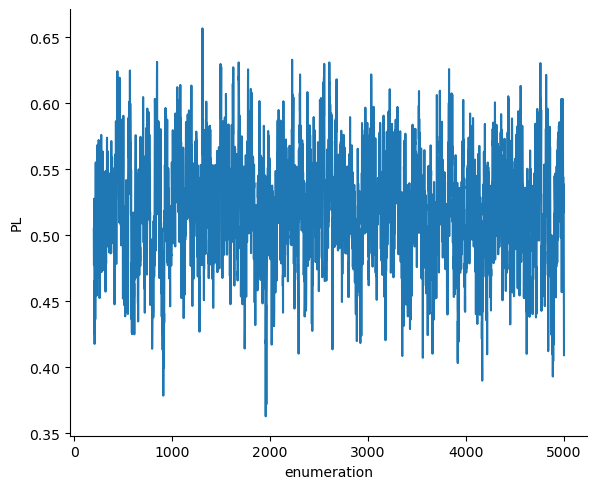

Nt = 14, mu = 0.25


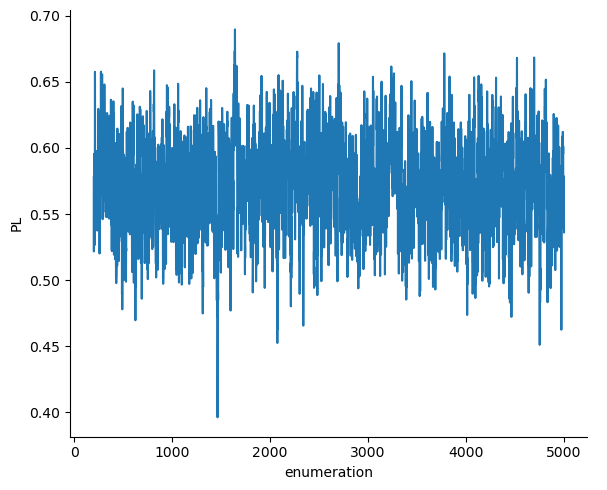

Nt = 14, mu = 0.3


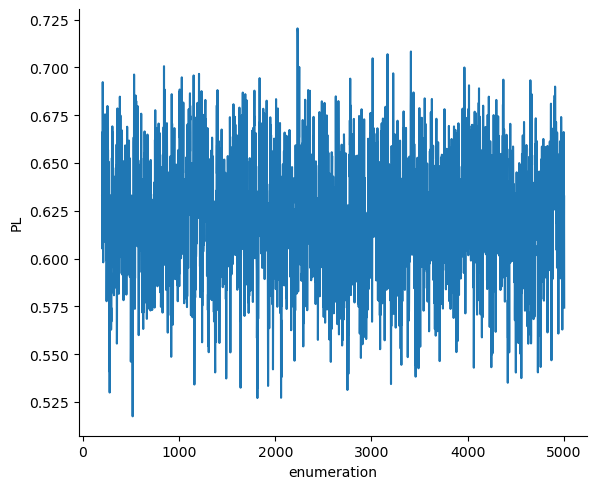

Nt = 14, mu = 0.12


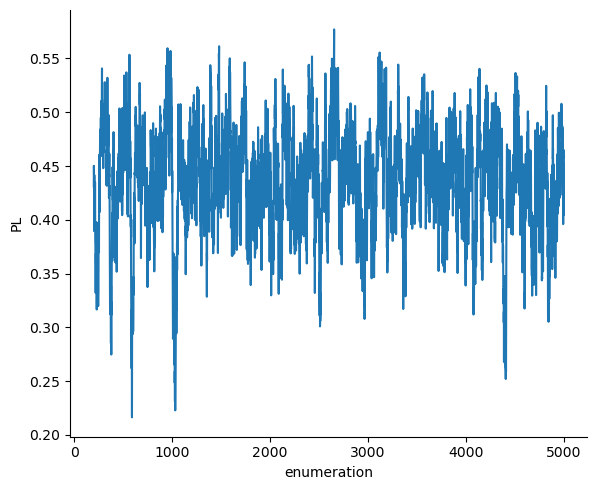

Nt = 16, mu = 0.0


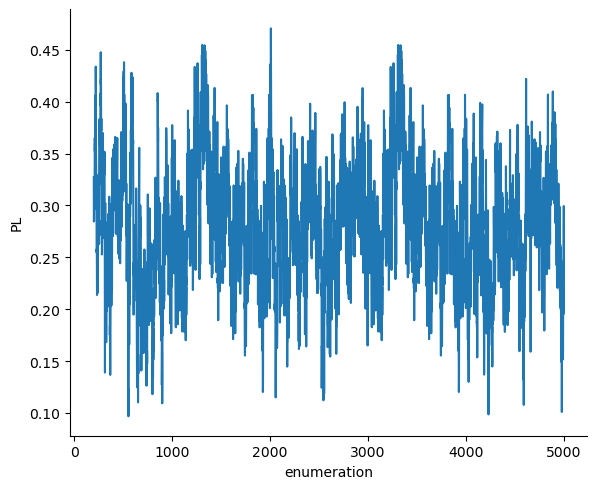

Nt = 16, mu = 0.15


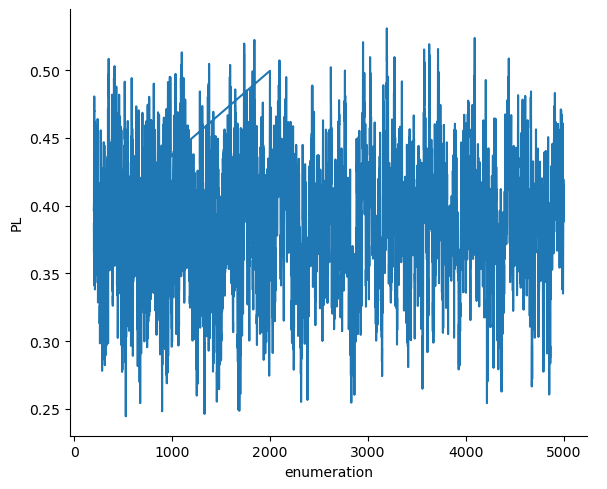

Nt = 16, mu = 0.03


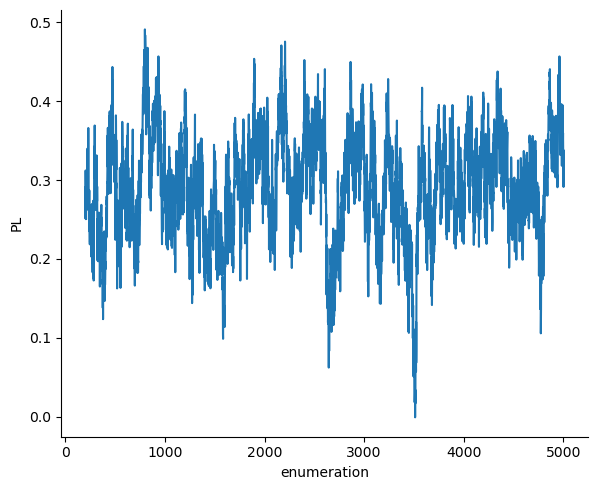

Nt = 16, mu = 0.05


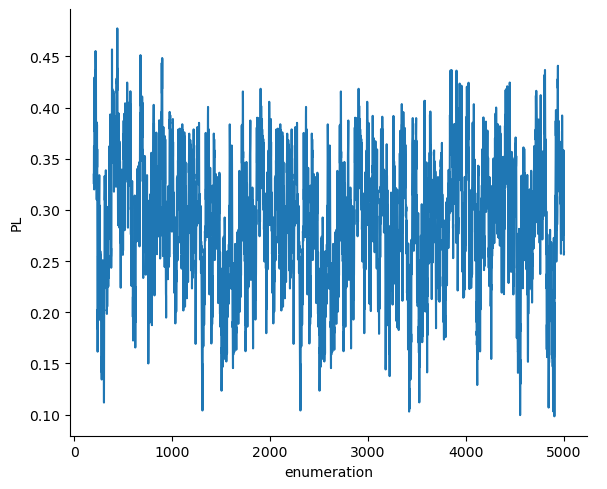

Nt = 16, mu = 0.07


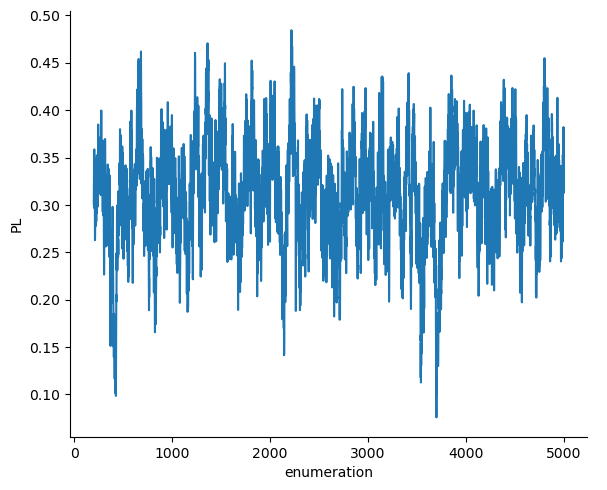

Nt = 16, mu = 0.1


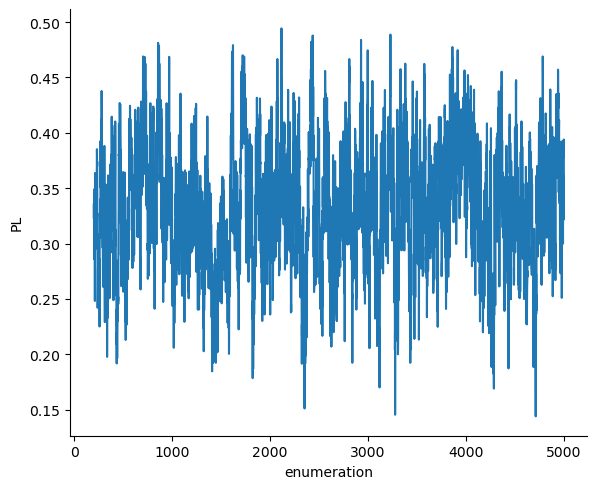

Nt = 16, mu = 0.2


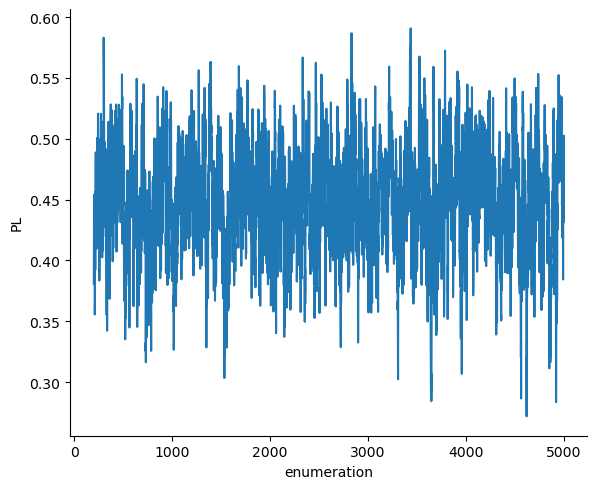

Nt = 16, mu = 0.25


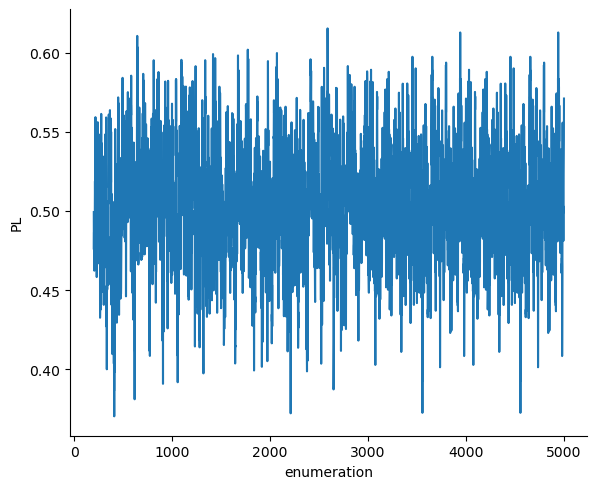

Nt = 16, mu = 0.3


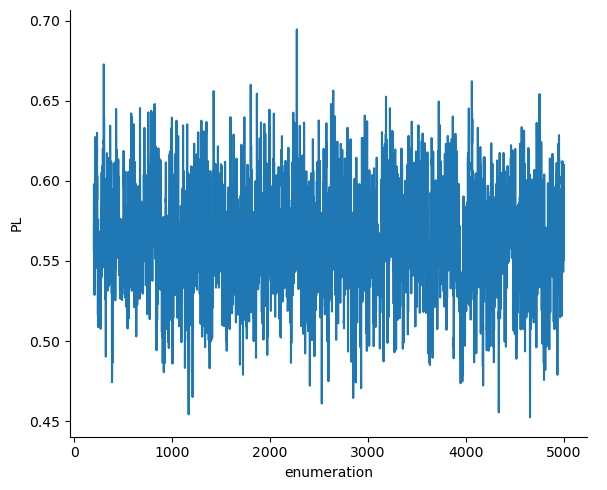

Nt = 16, mu = 0.12


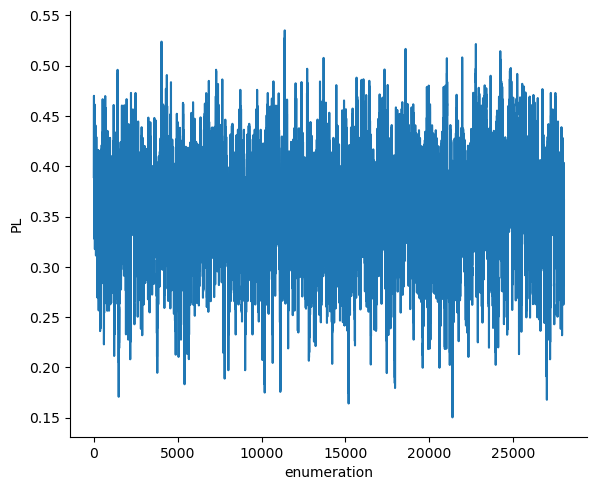

Nt = 18, mu = 0.0


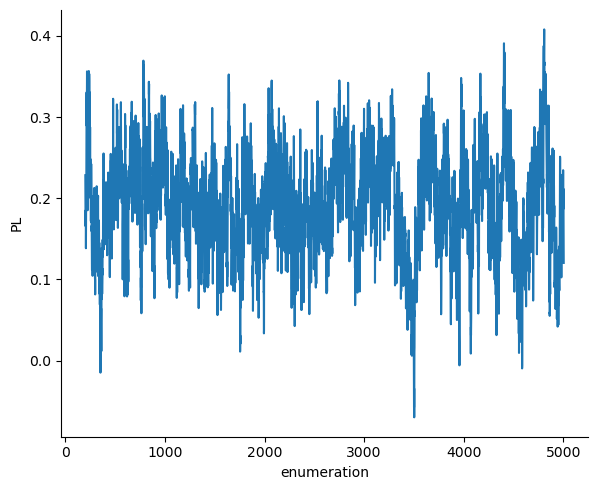

Nt = 18, mu = 0.15


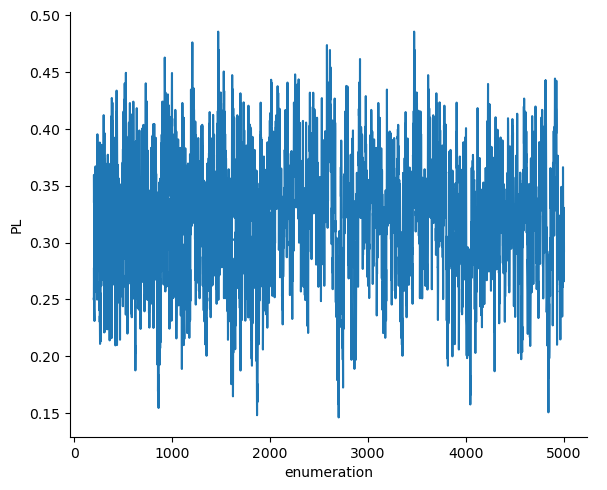

Nt = 18, mu = 0.03


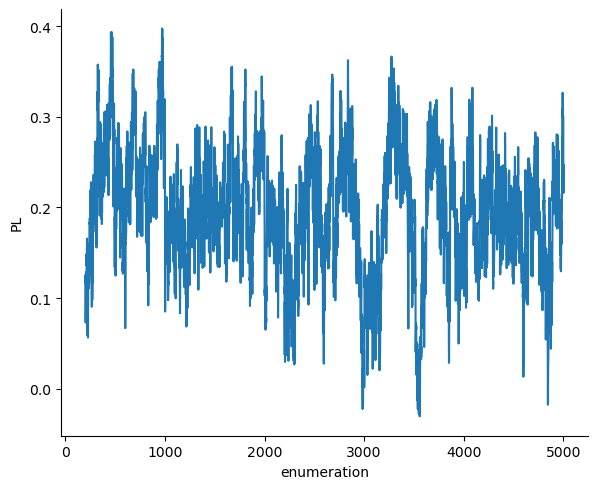

Nt = 18, mu = 0.05


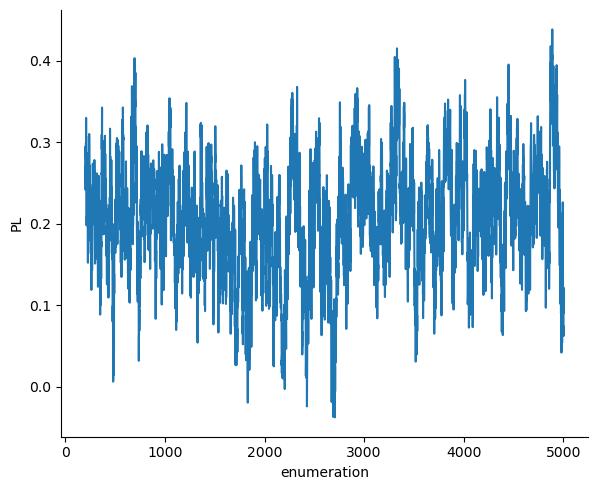

Nt = 18, mu = 0.07


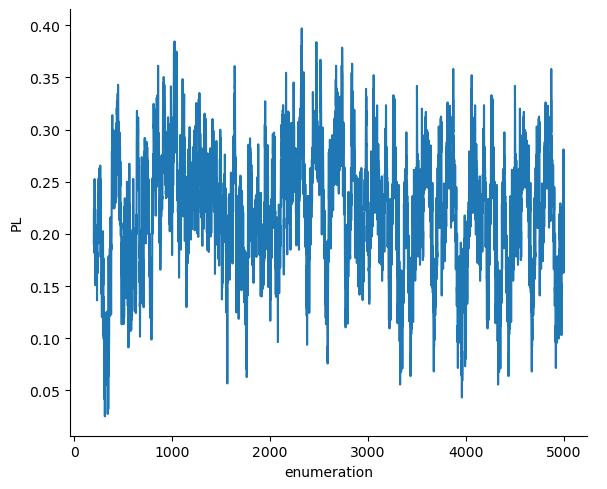

Nt = 18, mu = 0.1


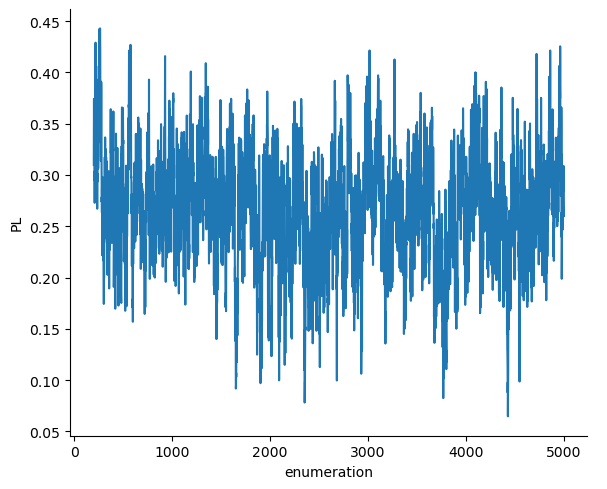

Nt = 18, mu = 0.2


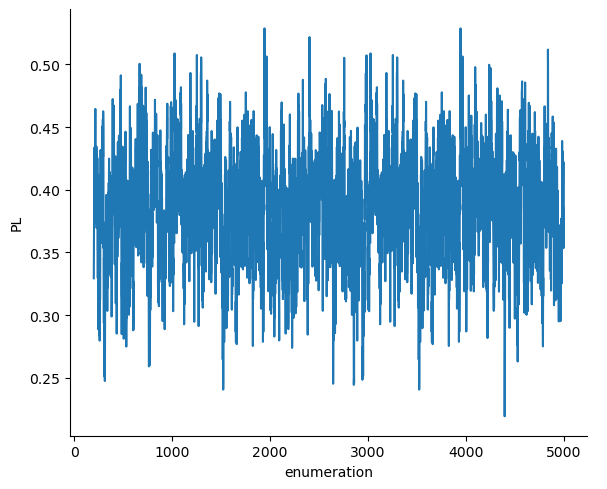

Nt = 18, mu = 0.25


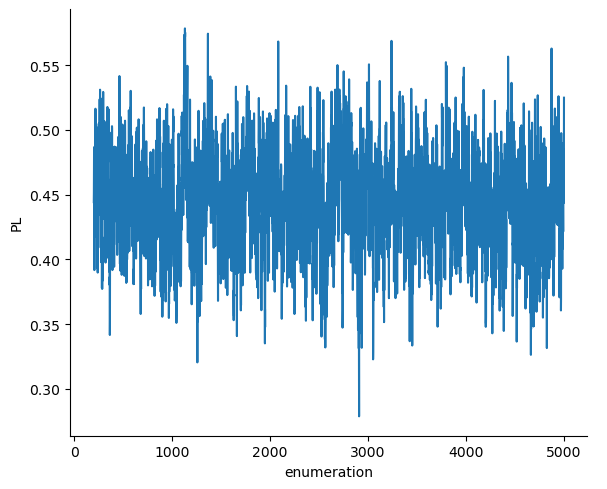

Nt = 18, mu = 0.3


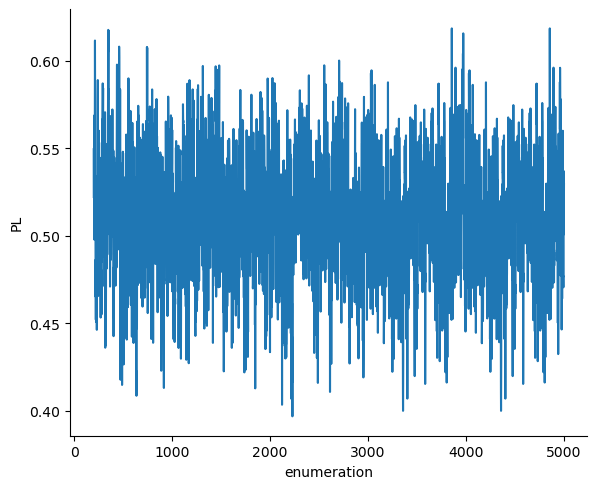

Nt = 18, mu = 0.12


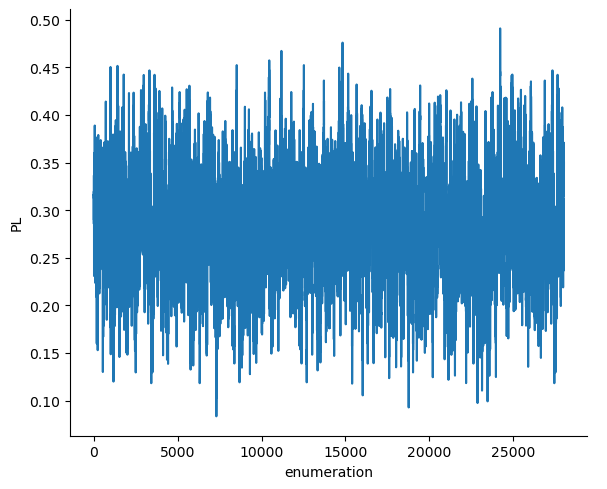

Nt = 20, mu = 0.0


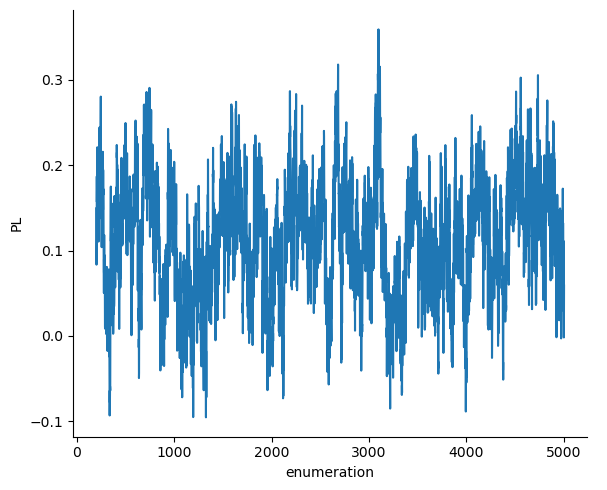

Nt = 20, mu = 0.15


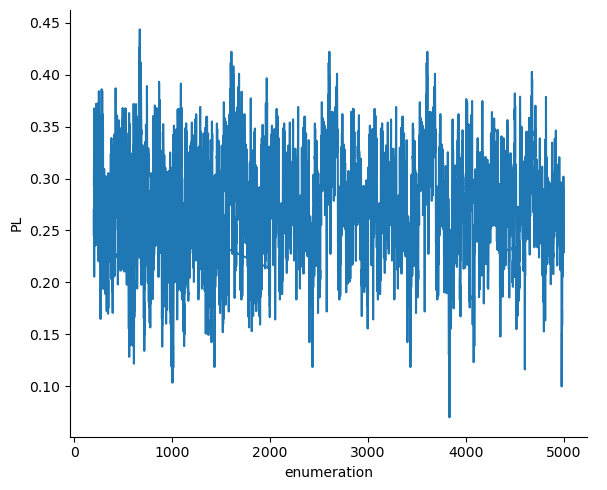

Nt = 20, mu = 0.03


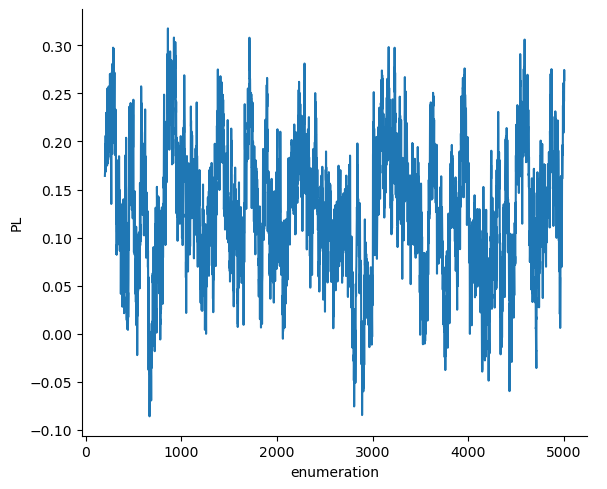

Nt = 20, mu = 0.05


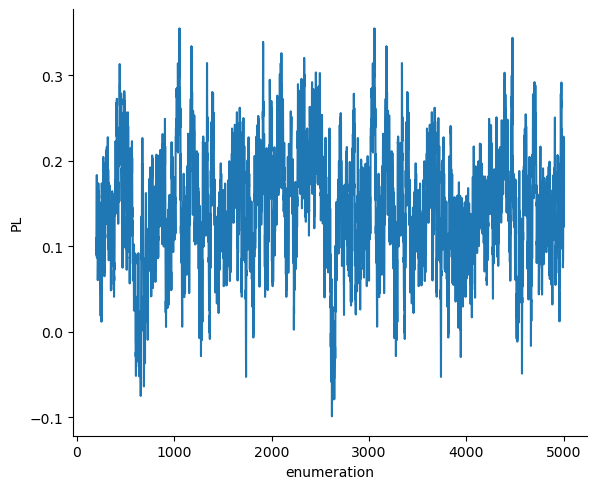

Nt = 20, mu = 0.07


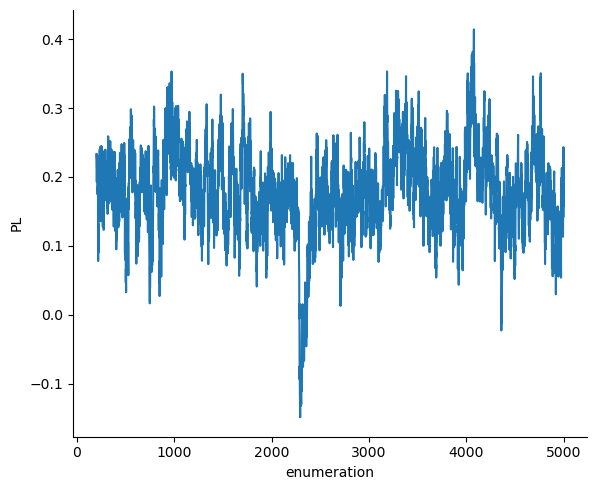

Nt = 20, mu = 0.1


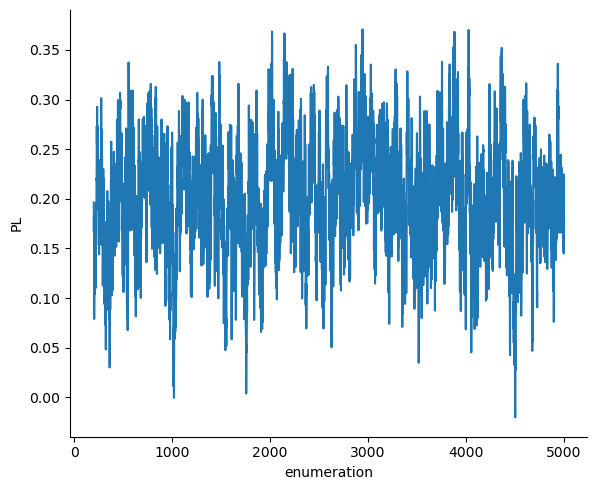

Nt = 20, mu = 0.2


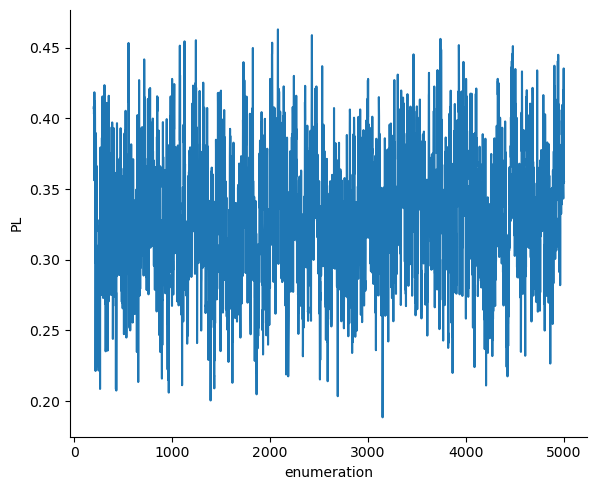

Nt = 20, mu = 0.25


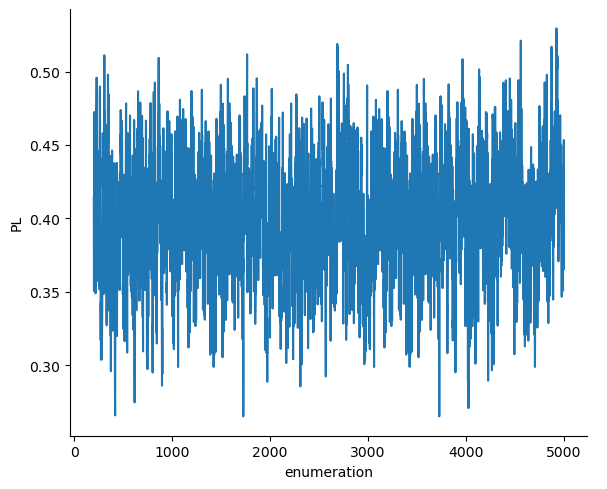

Nt = 20, mu = 0.3


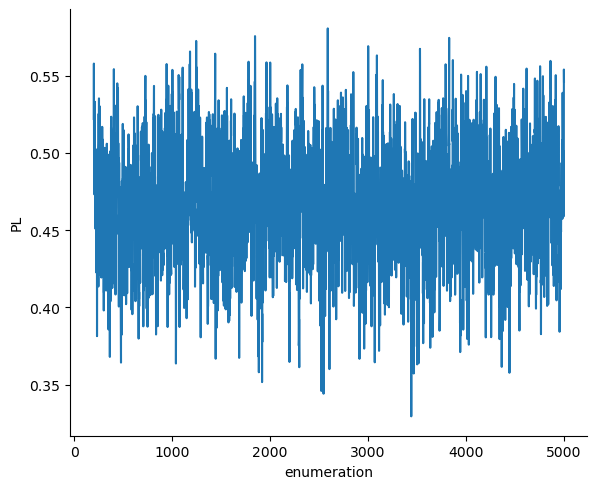

Nt = 20, mu = 0.12


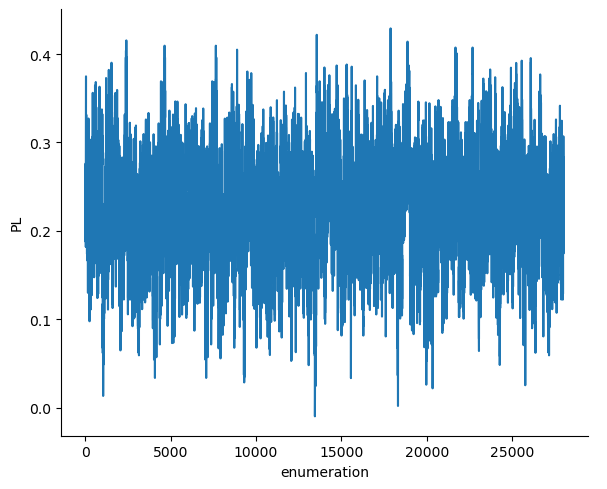

Nt = 22, mu = 0.0


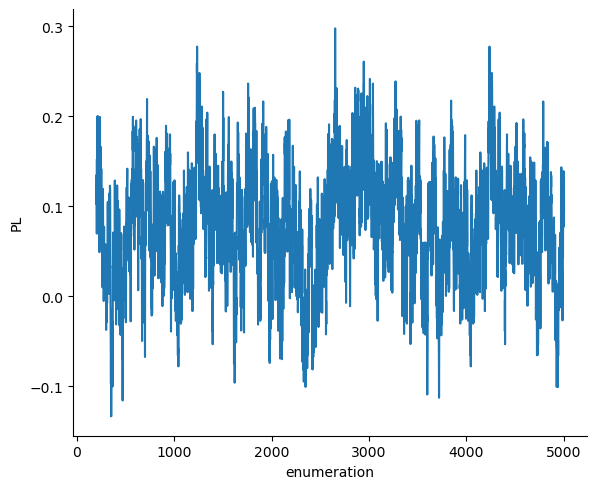

Nt = 22, mu = 0.15


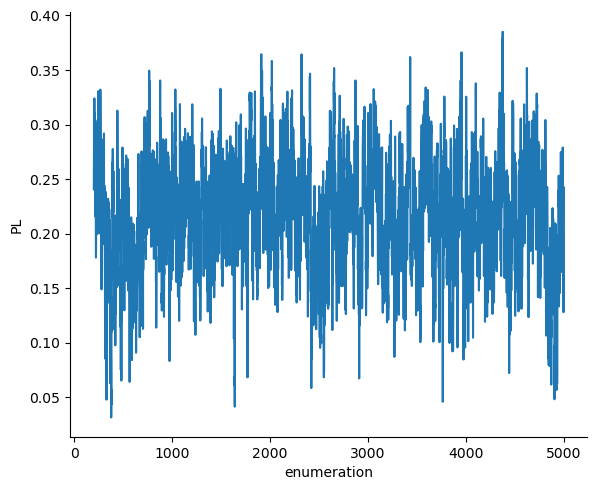

Nt = 22, mu = 0.03


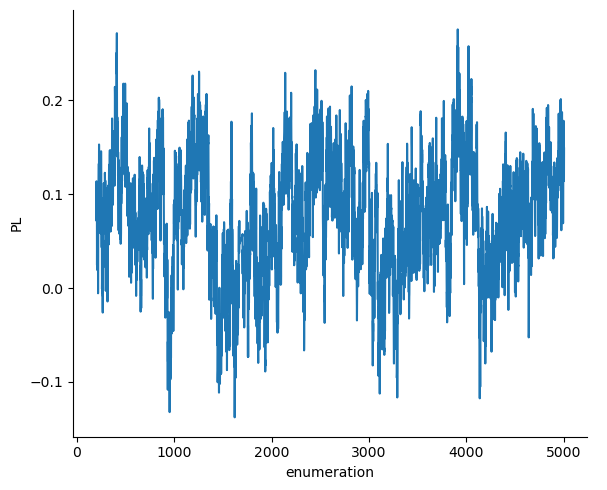

Nt = 22, mu = 0.05


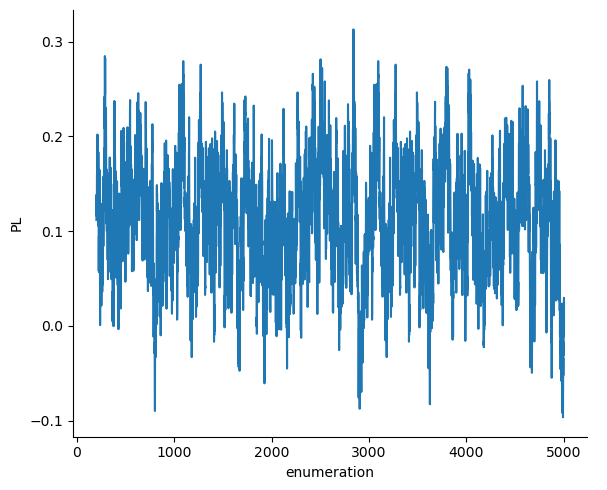

Nt = 22, mu = 0.07


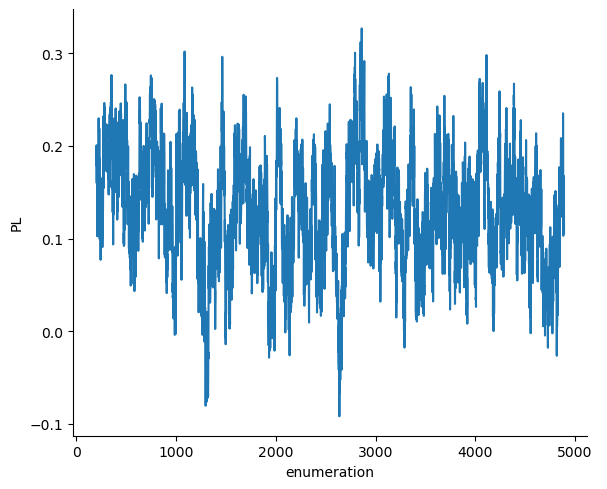

Nt = 22, mu = 0.1


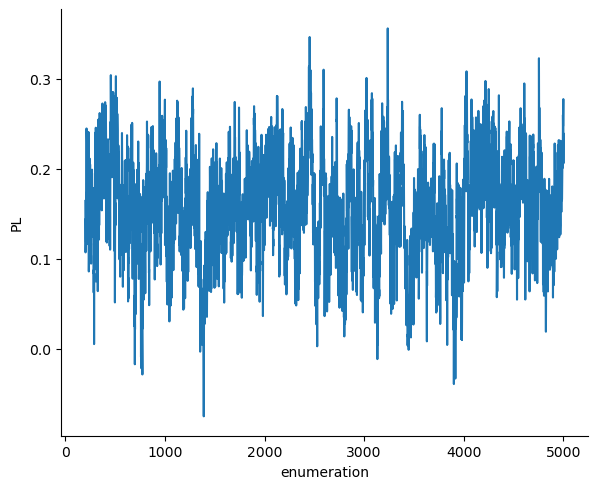

Nt = 22, mu = 0.2


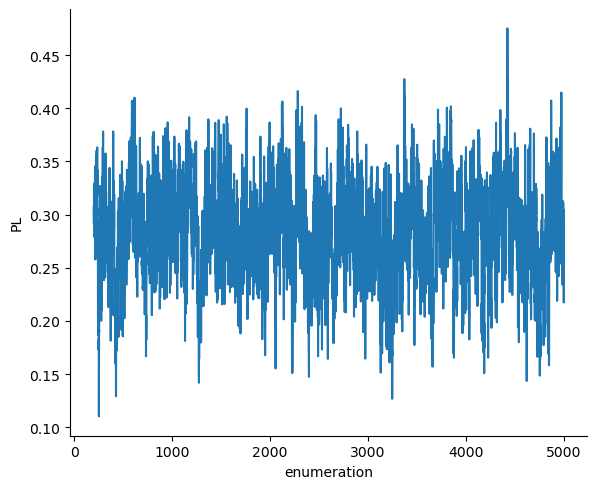

Nt = 22, mu = 0.25


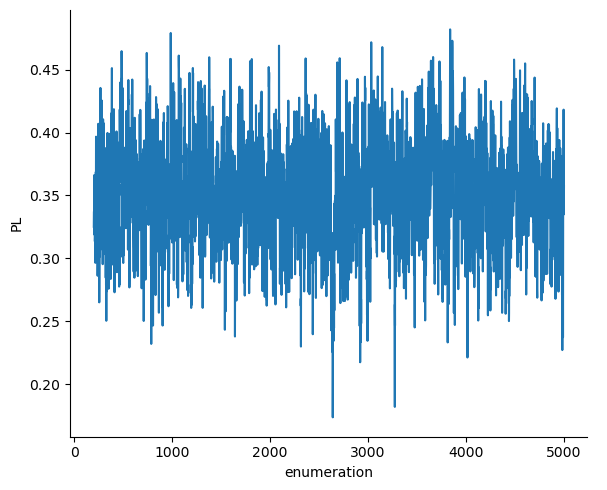

Nt = 22, mu = 0.3


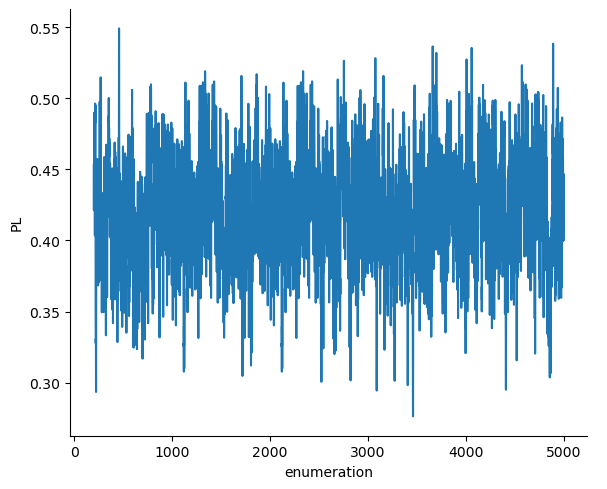

Nt = 22, mu = 0.12


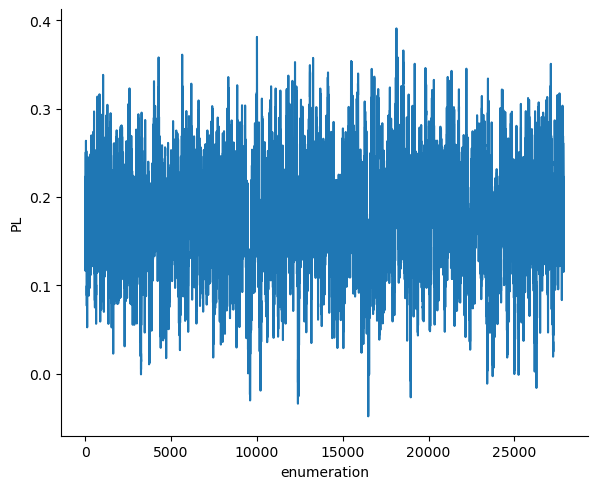

Nt = 24, mu = 0.0


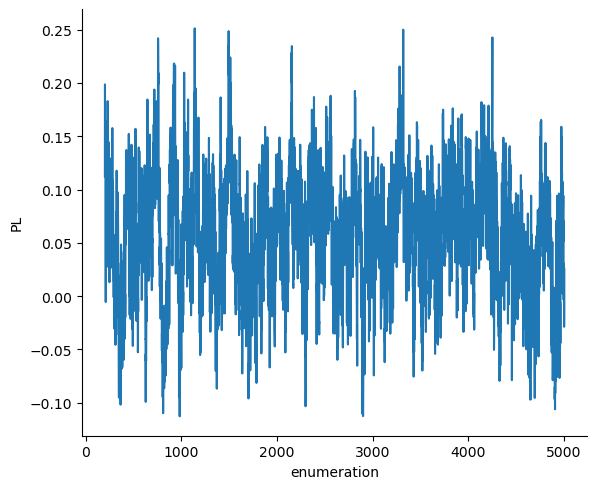

Nt = 24, mu = 0.15


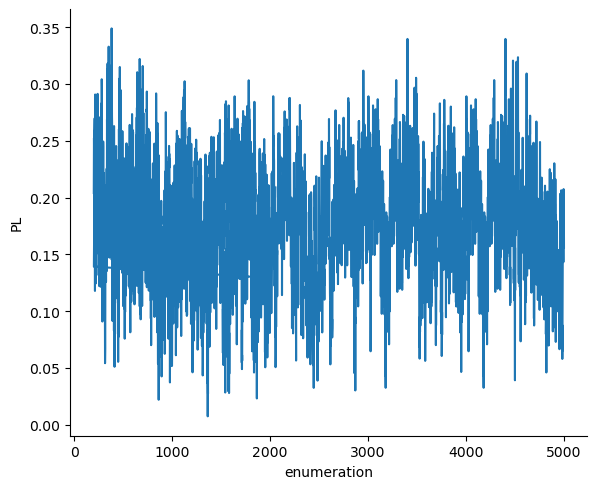

Nt = 24, mu = 0.05


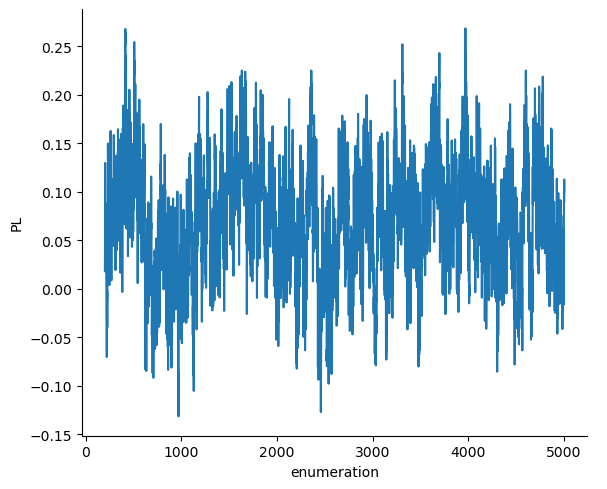

Nt = 24, mu = 0.1


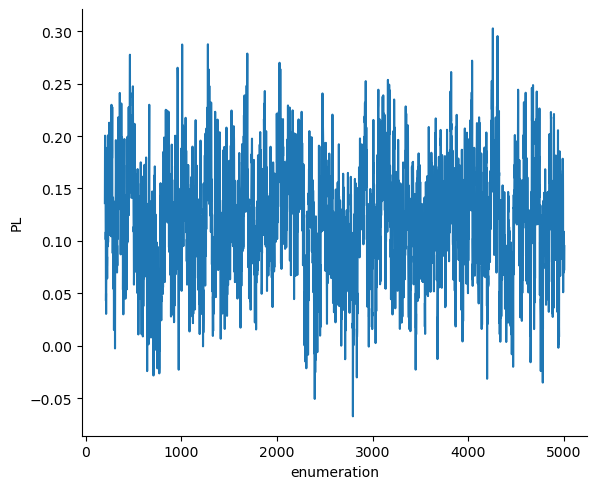

Nt = 24, mu = 0.2


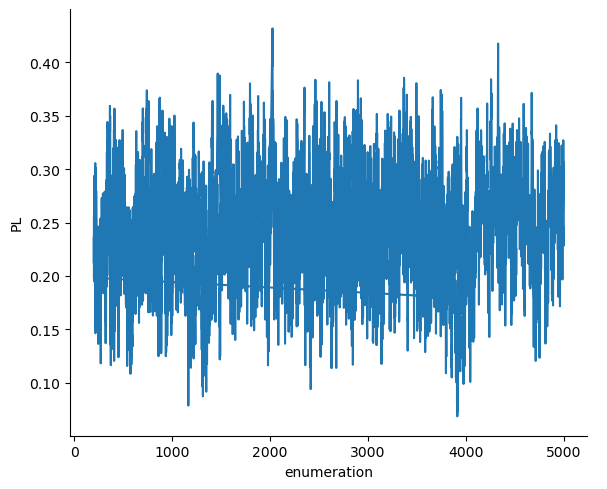

Nt = 24, mu = 0.25


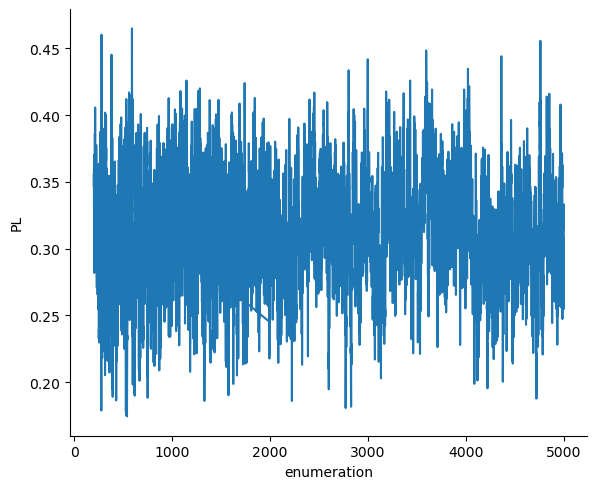

Nt = 24, mu = 0.3


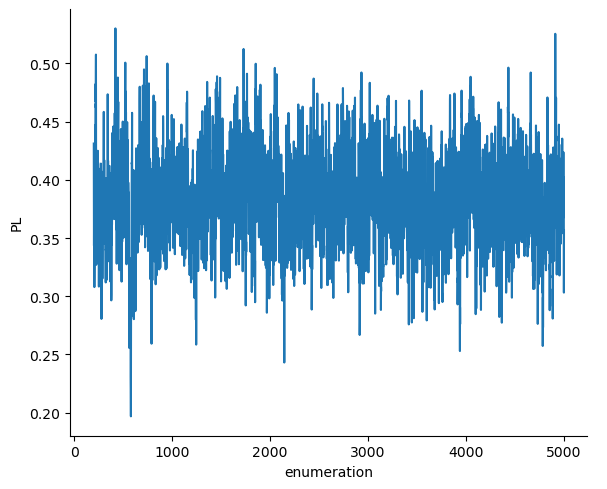

Nt = 26, mu = 0.0


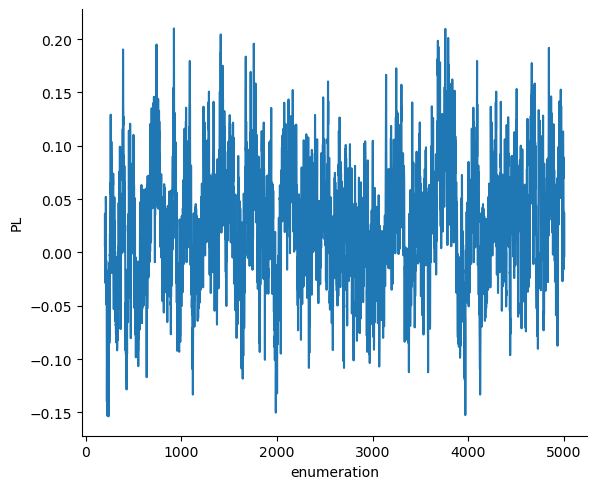

Nt = 28, mu = 0.15


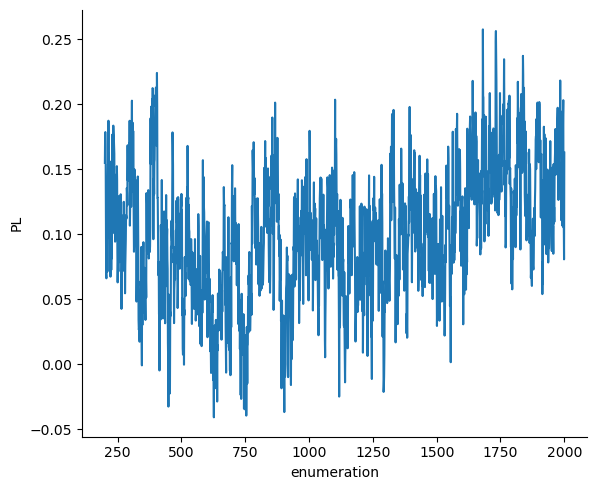

Nt = 28, mu = 0.2


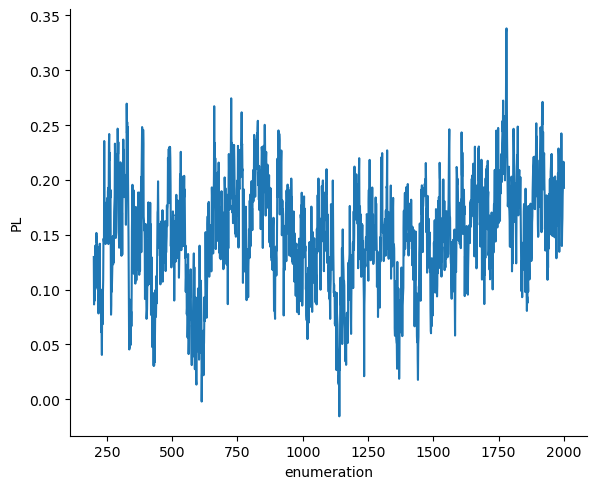

Nt = 28, mu = 0.25


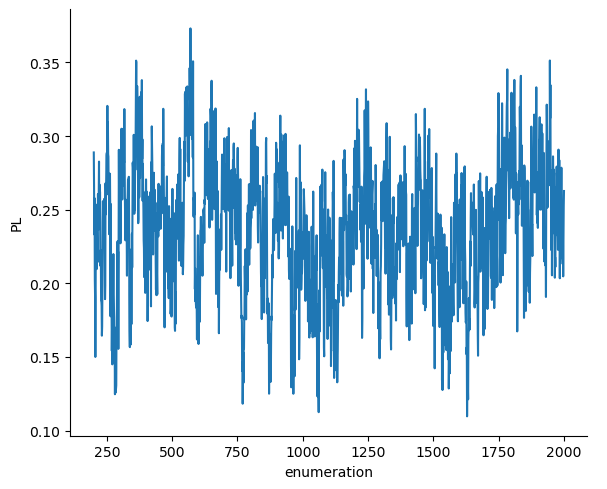

Nt = 32, mu = 0.0


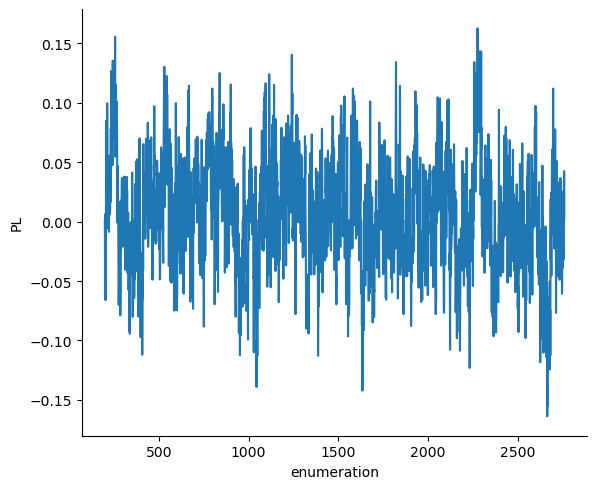

Nt = 32, mu = 0.15


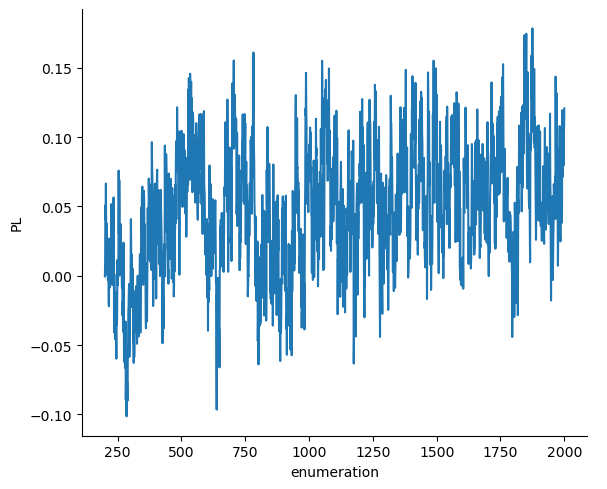

Nt = 32, mu = 0.2


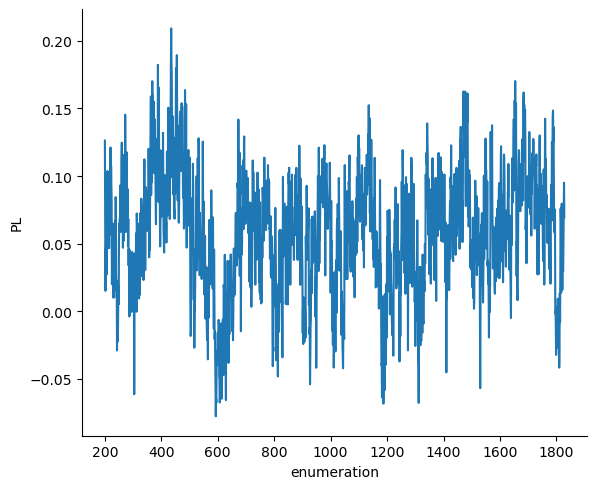

Nt = 32, mu = 0.25


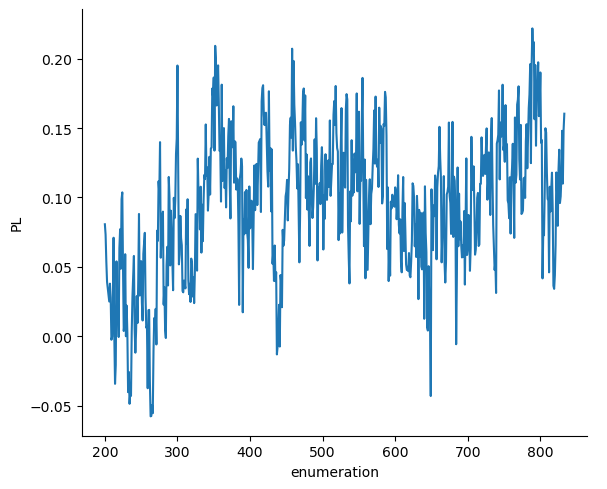

Nt = 32, mu = 0.3


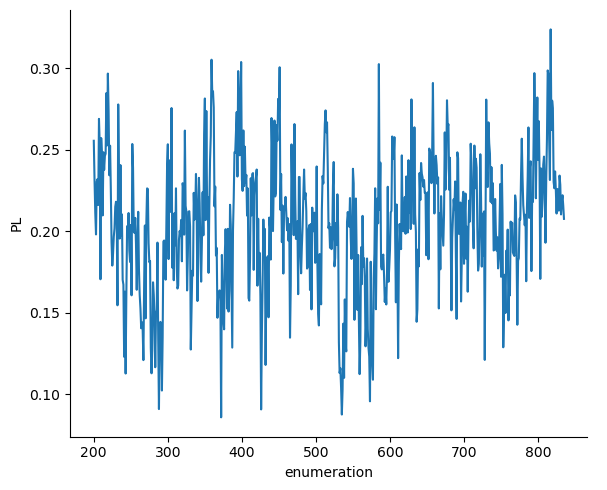

Nt = 36, mu = 0.15


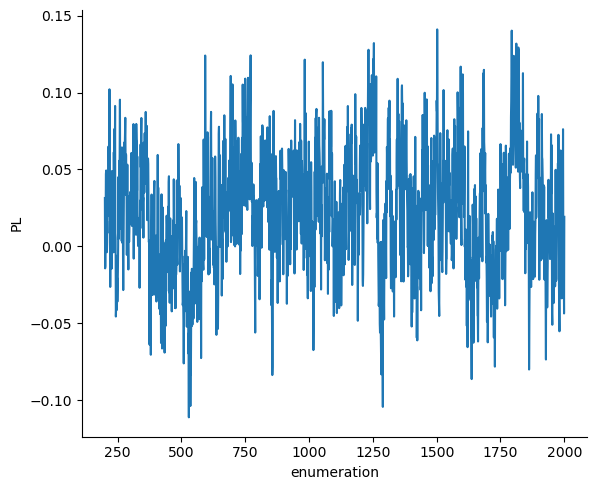

Nt = 36, mu = 0.2


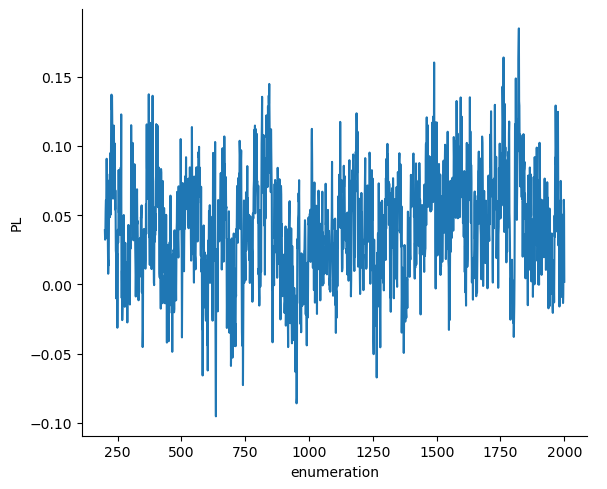

Nt = 36, mu = 0.25


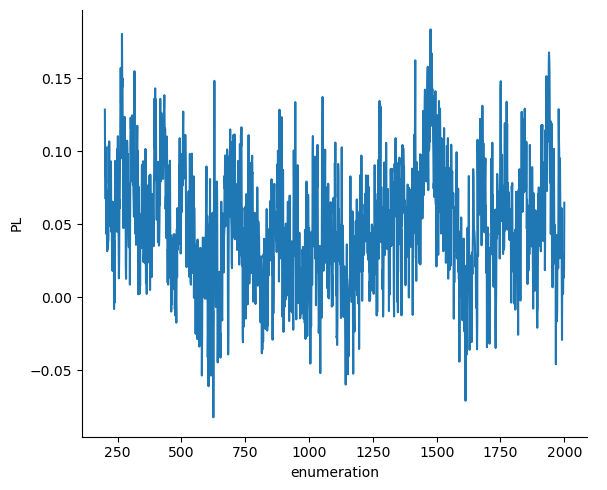

Nt = 40, mu = 0.15


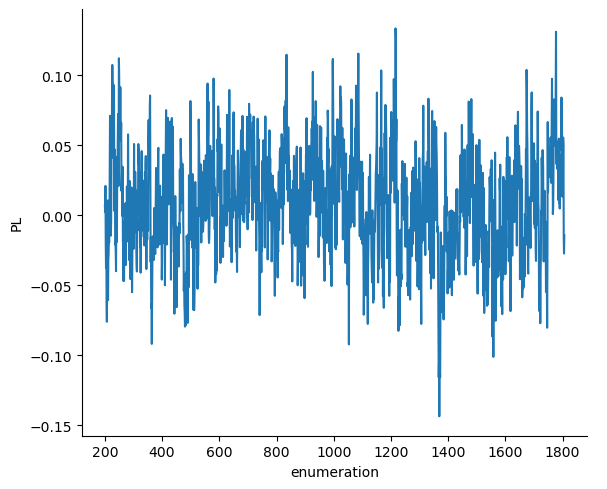

Nt = 40, mu = 0.2


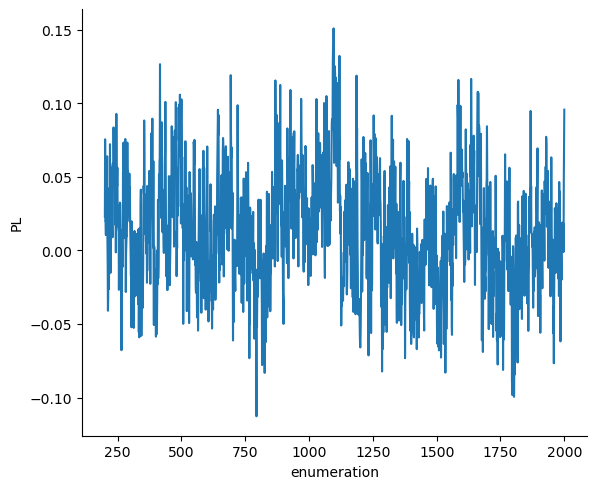

Nt = 40, mu = 0.25


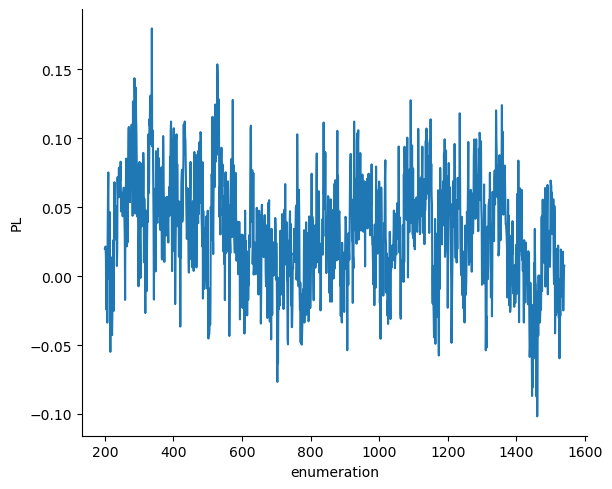

Nt = 64, mu = 0.1


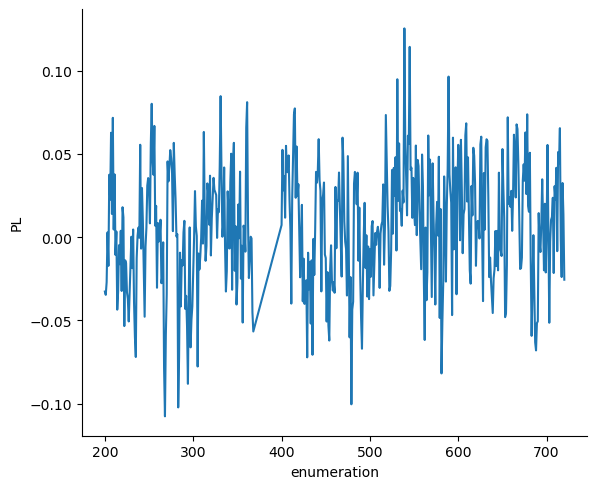

Nt = 64, mu = 0.3


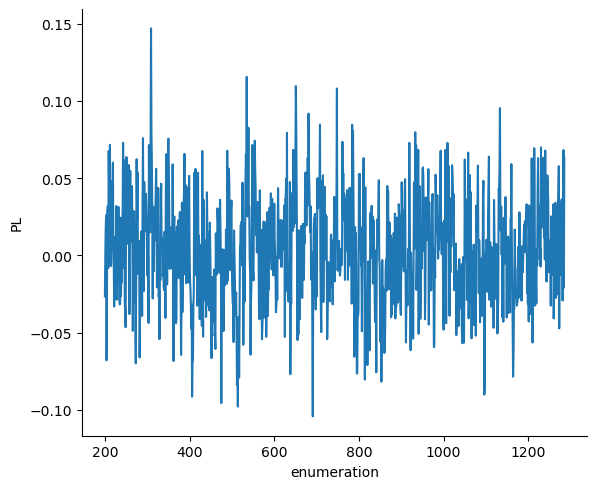

In [5]:
for Nt in df1['Nt'].unique():
    for mu in df1['mu'].unique():
        if df1[(df1['Nt'] == Nt) & (df1['mu'] == mu)].empty:
            continue
        print(f'Nt = {Nt}, mu = {mu}')
        fg = seaborn.FacetGrid(data=df1[(df1['Nt'] == Nt) & (df1['mu'] == mu)], height=5, aspect=1.2)
        fg.map(plt.plot, 'enumeration', 'PL').add_legend()
        plt.show()

In [ ]:
# bootstrap for entropy
def entropy_sample(df, n_samples):
    T_arr = np.sort(df['T'].unique())
    if len(T_arr) > 1:
        means = np.zeros((len(T_arr), n_samples))
        for i in range(len(T_arr)):
            for j in range(n_samples):
                means[i][j] = np.mean(random.choices(df[df['T'] == T_arr[i]]['PL'].to_numpy(), k=df[df['T'] == T_arr[i]].shape[0]))
        T_middle = []
        entropy = []
        sample_num = []
        for i in range(len(T_arr) - 1):
            T_tmp = (T_arr[i] + T_arr[i + 1]) / 2
            for j in range(n_samples):
                sample_num.append(j)
                T_middle.append(T_tmp)
                entropy.append((T_arr[i + 1] * np.log(means[i + 1][j]) - T_arr[i] * np.log(means[i][j])) / (T_arr[i + 1] - T_arr[i]))
        return pd.DataFrame({'sample': sample_num, 'T': T_middle, 'entropy': entropy})
    else:
        return pd.DataFrame()

def entropy_sample_binning(df, n_samples, bin_size):
    T_arr = np.sort(df['T'].unique())
    if len(T_arr) > 1:
        data_binned = []
        for i in range(len(T_arr)):
            bin_borders = get_bin_borders(df[df['T'] == T_arr[i]].shape[0], bin_size)
            data_tmp = np.zeros(len(bin_borders) - 1)
            data_T = df[df['T'] == T_arr[i]]['PL'].to_numpy()
            for j in range(len(data_tmp)):
                data_tmp[j] = np.mean(data_T[bin_borders[j]:bin_borders[j + 1]])
            data_binned.append(data_tmp)
        means = np.zeros((len(T_arr), n_samples))
        for i in range(len(T_arr)):
            for j in range(n_samples):
                means[i][j] = np.mean(random.choices(data_binned[i], k=data_binned[i].shape[0]))
        T_middle = []
        entropy = []
        sample_num = []
        for i in range(len(T_arr) - 1):
            T_tmp = (T_arr[i] + T_arr[i + 1]) / 2
            for j in range(n_samples):
                sample_num.append(j)
                T_middle.append(T_tmp)
                entropy.append((T_arr[i + 1] * np.log(means[i + 1][j]) - T_arr[i] * np.log(means[i][j])) / (T_arr[i + 1] - T_arr[i]))
        return pd.DataFrame({'sample': sample_num, 'T': T_middle, 'entropy': entropy})
    else:
        return pd.DataFrame()

def get_bin_borders(data_size, bin_size):
    nbins = data_size // bin_size
    bin_sizes = [bin_size for _ in range(nbins)]
    residual_size = data_size - nbins * bin_size
    idx = 0
    while residual_size > 0:
        bin_sizes[idx] += 1
        residual_size -= 1
        idx = (idx + 1) % nbins
    return np.array([0] + list(itertools.accumulate(bin_sizes)))

# bootstrap for susceptibility
def susceptibility_sample(df, n_samples):
    means = []
    sample_num = []
    data = df['PL'].to_numpy()
    n = df['PL'].shape[0]
    for i in range(n_samples):
        sample = random.choices(data, k=n)
        mean = np.mean(sample)
        sq_mean = 0
        for j in range(len(sample)):
            sq_mean += sample[j] ** 2
        means.append((sq_mean / len(sample) - mean ** 2))
        sample_num.append(i)
    return pd.DataFrame({'sample': sample_num, 'susceptibility': means})

# bootstrap for transition
def polyakov_loops_sample(df, n_samples):
    means = []
    sample_num = []
    data = df['PL'].to_numpy()
    n = df['PL'].shape[0]
    for i in range(n_samples):
        sample = random.choices(data, k=n)
        means.append(np.mean(sample))
        sample_num.append(i)
    return pd.DataFrame({'sample': sample_num, 'PL': means})

In [24]:
@njit
def potential_numba(x):
    n = x.shape[1]
    y = np.zeros(n)
    for i in range(n):
        fraction = x[0][i] / x[1][i]
        if (fraction >= 0):
            y[i] = math.log(fraction)
        else:
            y[i] = 0
    return y

@njit
def trivial_numba(x):
    return x[0]

def entropy_sample_numba_binning(df, n_samples, bin_size):
    T_arr = np.sort(df['T'].unique())
    T_middle = []
    sample_num = []
    entropy = []
    bin_borders = get_bin_borders(df[df['T'] == T_arr[0]].shape[0], bin_size)
    x1 = data.loc[data['time_size'] == time_size, 'wilson_loop'].to_numpy()
    x2 = data.loc[data['time_size'] == time_size + 1, 'wilson_loop'].to_numpy()
    x = np.vstack((x1, x2))
    field, err = stat.jackknife_var_numba(x, potential_numba)
    for i in range(n_samples):
        samples = []
        for j in range(len(T_arr)):
            samples.append(random.choices(df[df['T'] == T_arr[j]]['PL'].to_numpy(), k=df[df['T'] == T_arr[j]].shape[0]))
        means = []
        for j in range(len(T_arr)):
            means.append(np.mean(samples[j]))
        for j in range(len(T_arr) - 1):
            T_middle.append((T_arr[j] + T_arr[j + 1]) / 2)
            entropy.append((T_arr[j + 1] * np.log(means[j + 1]) - T_arr[j] * np.log(means[j])) / (T_arr[j + 1] - T_arr[j]))
            sample_num.append(i)
    return pd.DataFrame({'sample': sample_num, 'T': T_middle, 'entropy': entropy})

def PL_sample_numba_binning(df, n_samples, bin_size):
    bin_borders = get_bin_borders(df.shape[0], bin_size)
    x = df['PL'].to_numpy()
    x = np.array([x])
    polyakov_loop, err = stat.bootstrap_numba_binning(x, trivial_numba, n_samples, bin_borders)
    return pd.DataFrame({'PL': [polyakov_loop], 'PL_err': [err]})

In [27]:
df_binning = []
for bin_size in [1, 2, 5, 10, 20, 50, 100, 200]:
    df_PL = df.groupby(['T', 'mu']).apply(PL_sample_numba_binning, 5000, bin_size, include_groups=False).reset_index(level=['T', 'mu'])
    df_binning.append(df_PL)
    df_binning[-1]['bin_size'] = bin_size
df_binning = pd.concat(df_binning, ignore_index=True)
print(df_binning.to_string())

               T    mu        PL    PL_err  bin_size
0      64.234049  0.10  0.005767  0.001651         1
1      64.234049  0.30  0.003100  0.001039         1
2     102.774479  0.15  0.008046  0.000944         1
3     102.774479  0.20  0.012912  0.000901         1
4     102.774479  0.25  0.032548  0.001052         1
5     114.193866  0.15  0.022146  0.000918         1
6     114.193866  0.20  0.041344  0.000906         1
7     114.193866  0.25  0.048636  0.000951         1
8     128.468099  0.00  0.006787  0.000911         1
9     128.468099  0.15  0.047998  0.001072         1
10    128.468099  0.20  0.058330  0.001093         1
11    128.468099  0.25  0.094383  0.002033         1
12    128.468099  0.30  0.204193  0.001653         1
13    146.820685  0.15  0.100102  0.001195         1
14    146.820685  0.20  0.150541  0.001134         1
15    146.820685  0.25  0.237589  0.001006         1
16    158.114583  0.00  0.027194  0.000806         1
17    171.290799  0.00  0.057361  0.000820    

T = 64.23404947916667, mu = 0.1


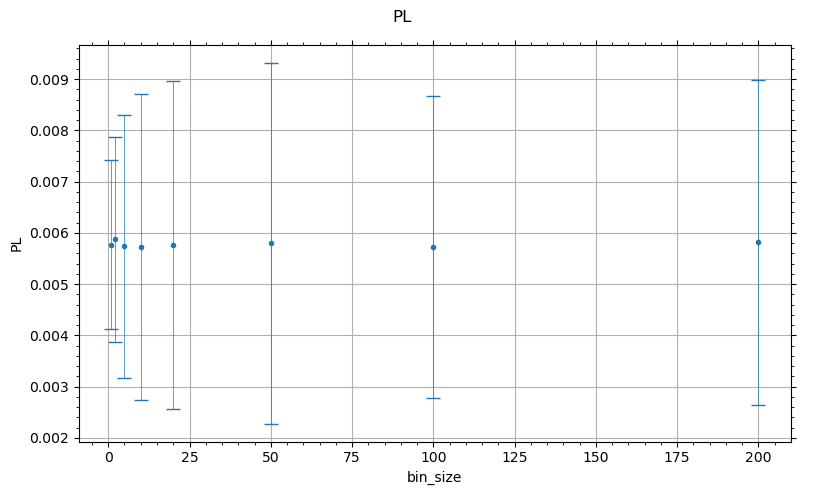

T = 64.23404947916667, mu = 0.3


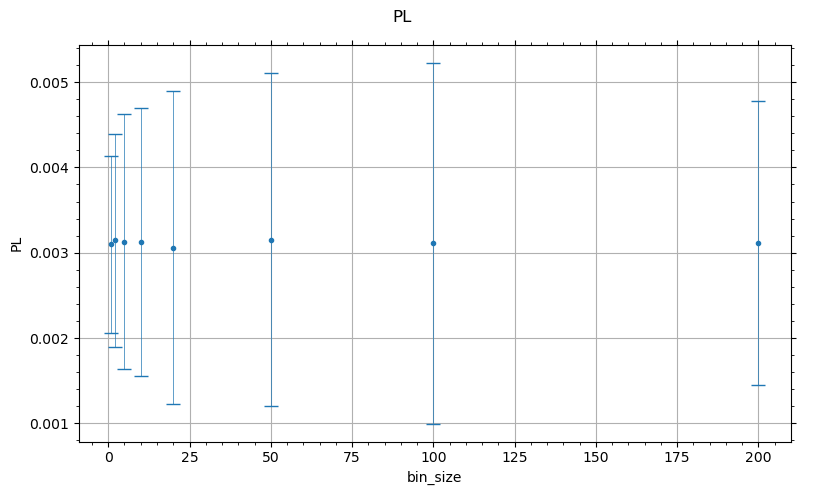

T = 102.77447916666667, mu = 0.15


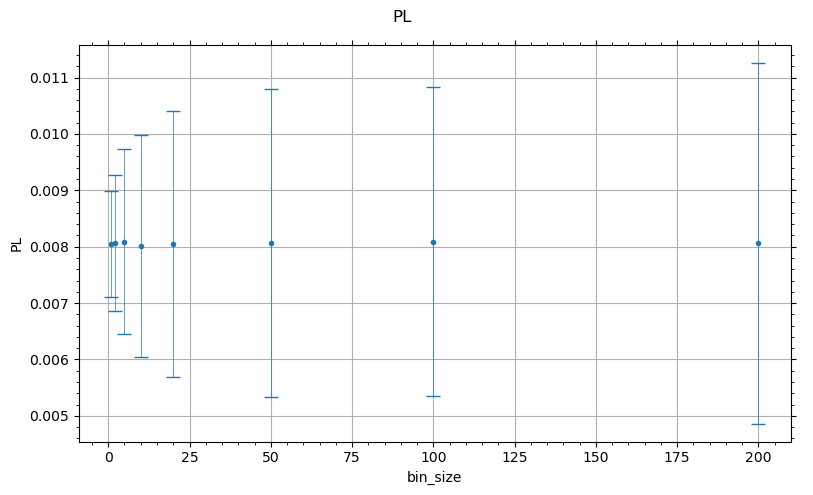

T = 102.77447916666667, mu = 0.2


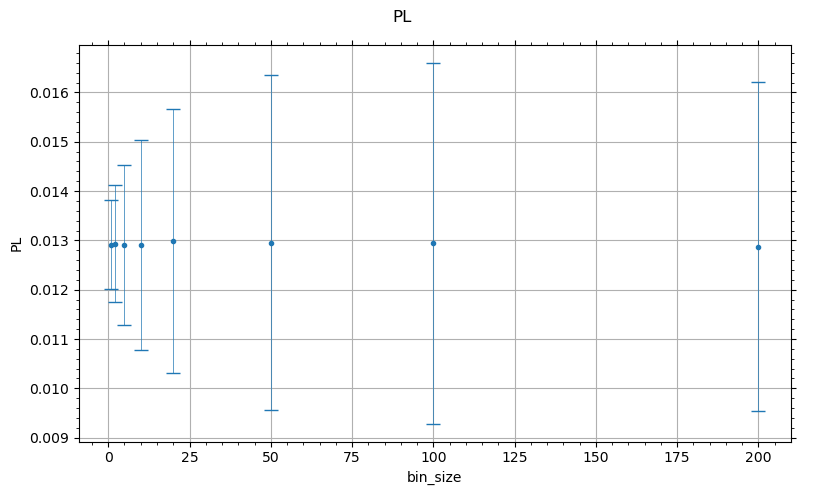

T = 102.77447916666667, mu = 0.25


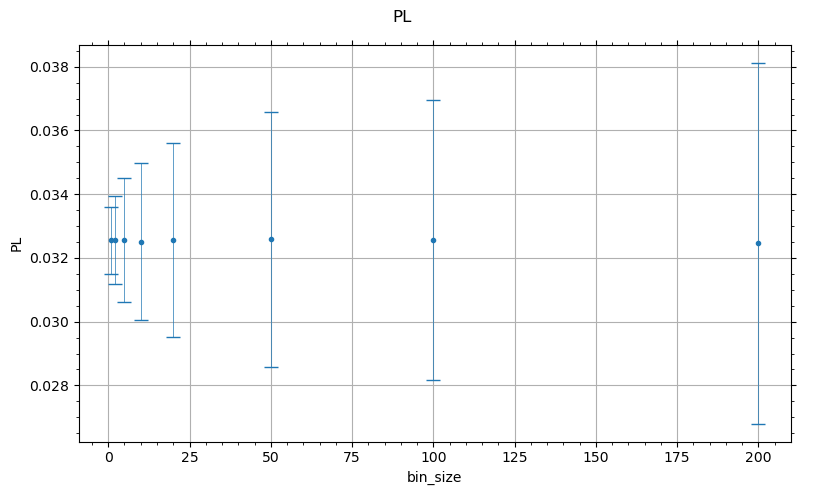

T = 114.19386574074073, mu = 0.15


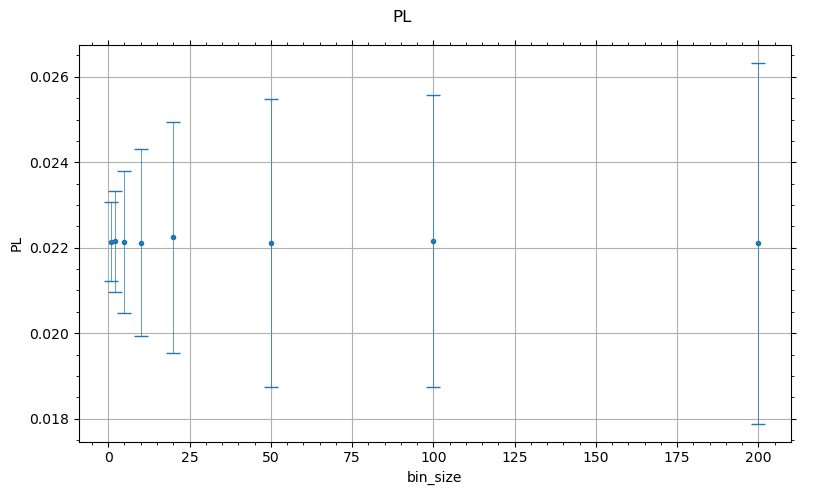

T = 114.19386574074073, mu = 0.2


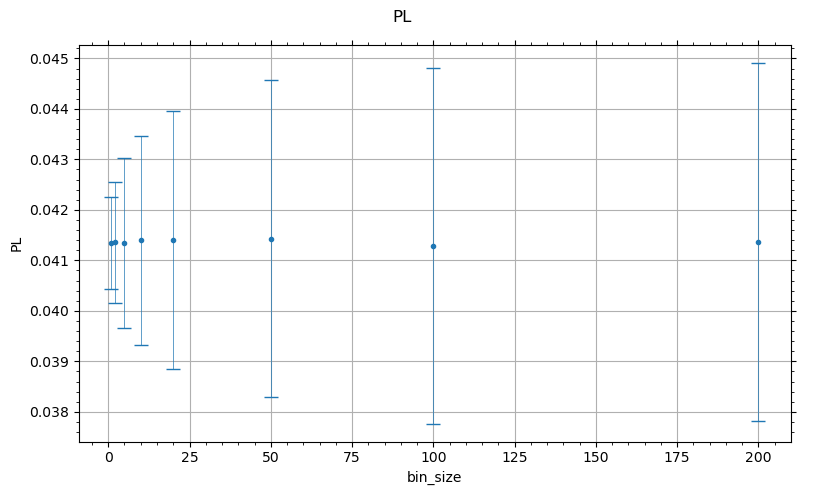

T = 114.19386574074073, mu = 0.25


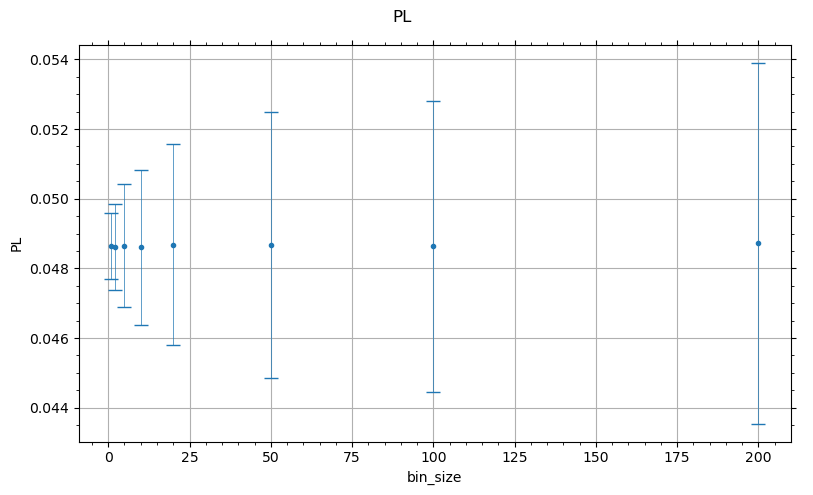

T = 128.46809895833334, mu = 0.3


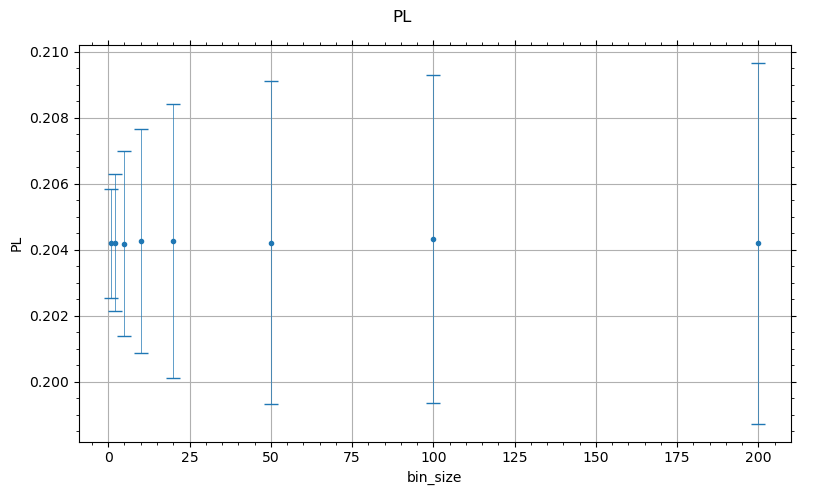

T = 128.46809895833334, mu = 0.15


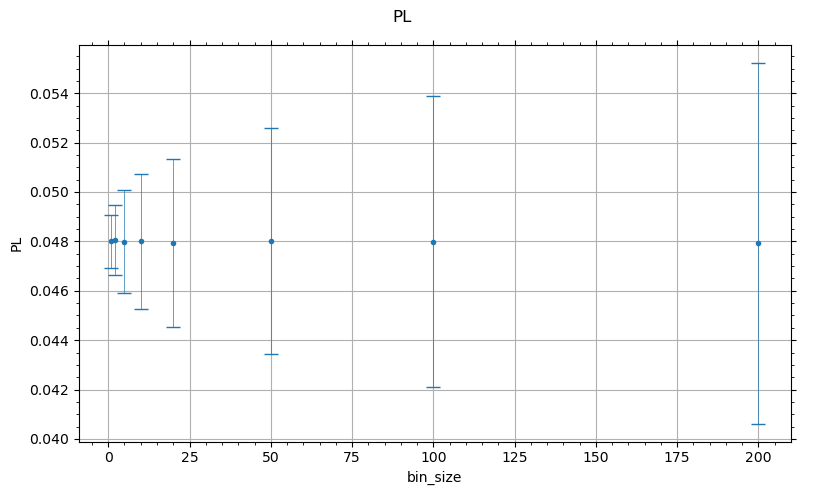

T = 128.46809895833334, mu = 0.2


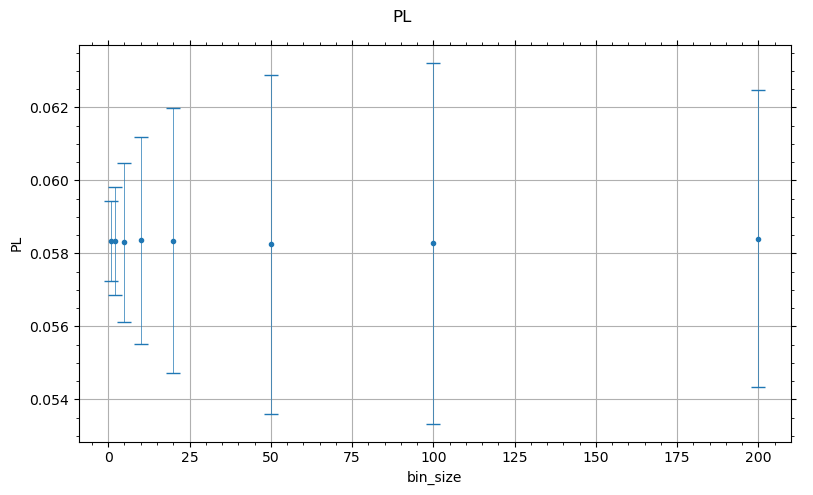

T = 128.46809895833334, mu = 0.25


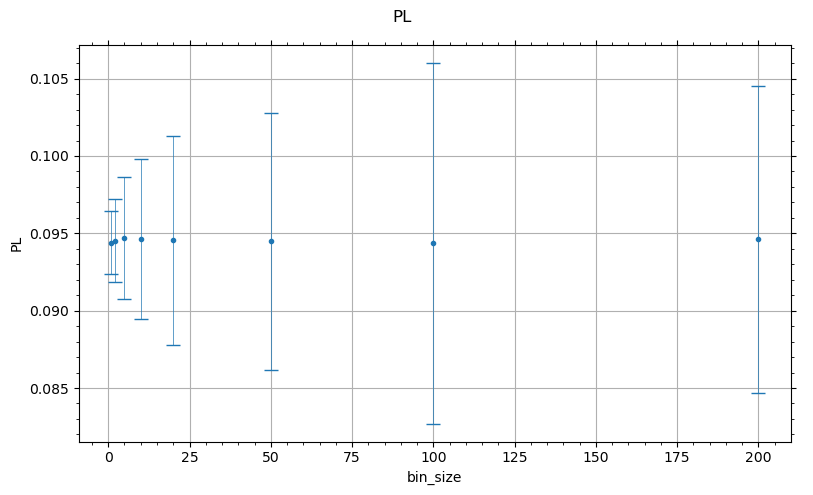

T = 128.46809895833334, mu = 0.0


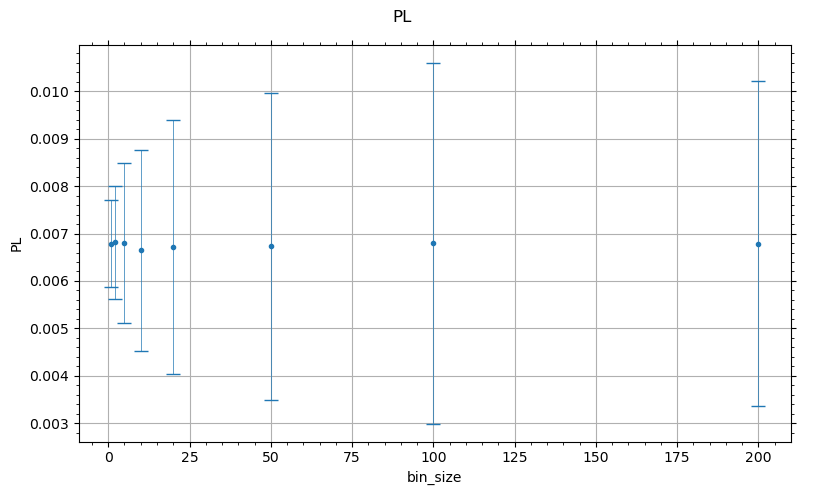

T = 146.82068452380952, mu = 0.15


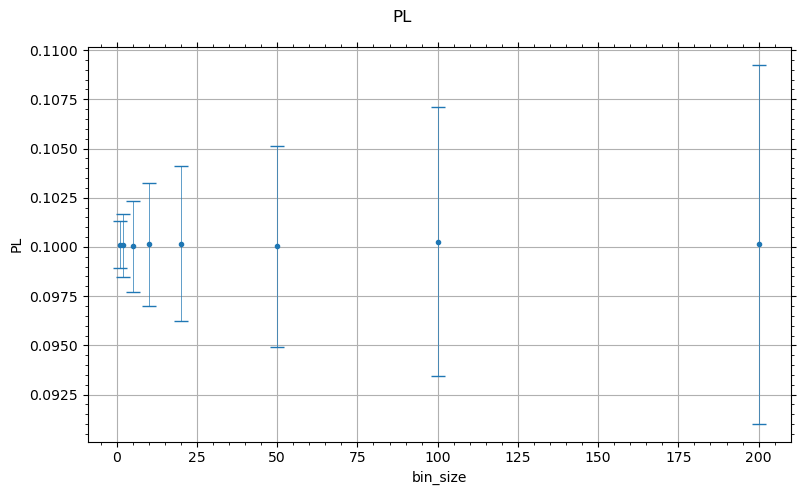

T = 146.82068452380952, mu = 0.2


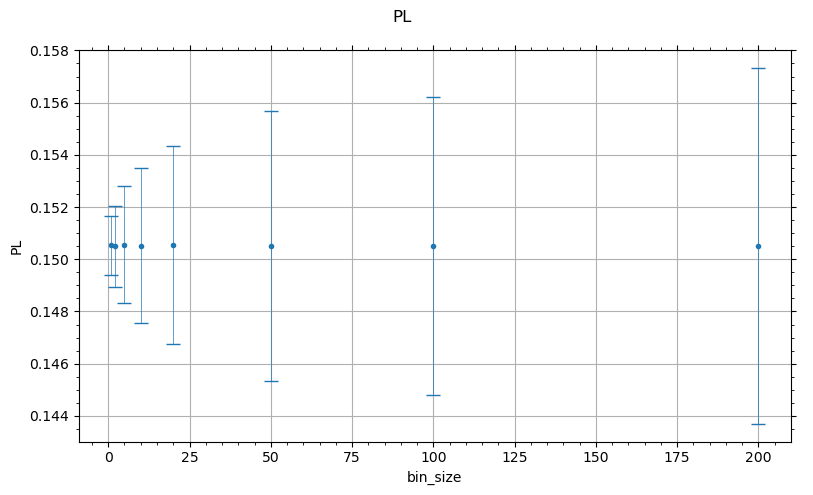

T = 146.82068452380952, mu = 0.25


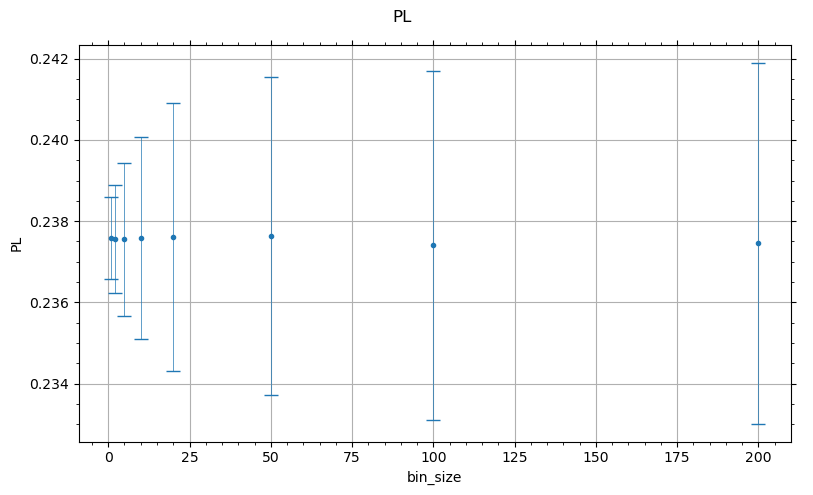

T = 158.11458333333334, mu = 0.0


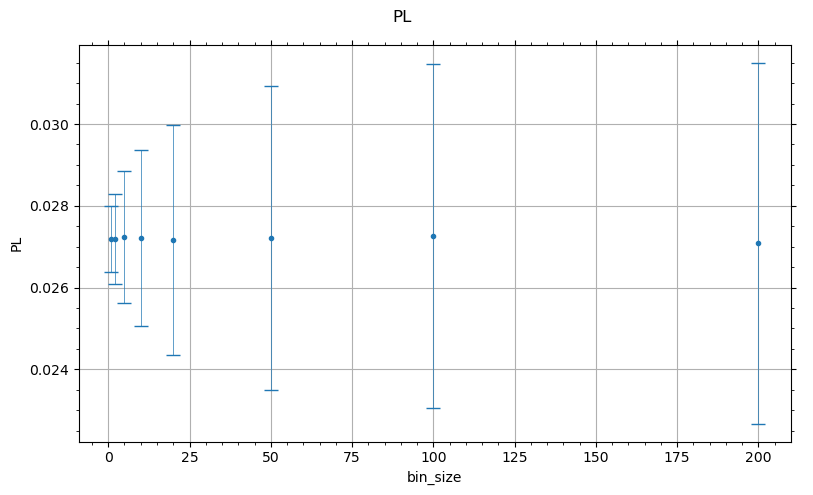

T = 171.29079861111111, mu = 0.1


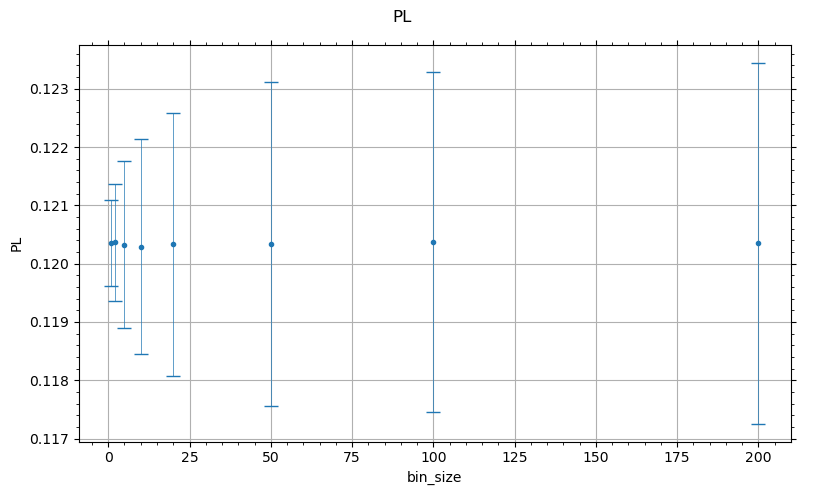

T = 171.29079861111111, mu = 0.3


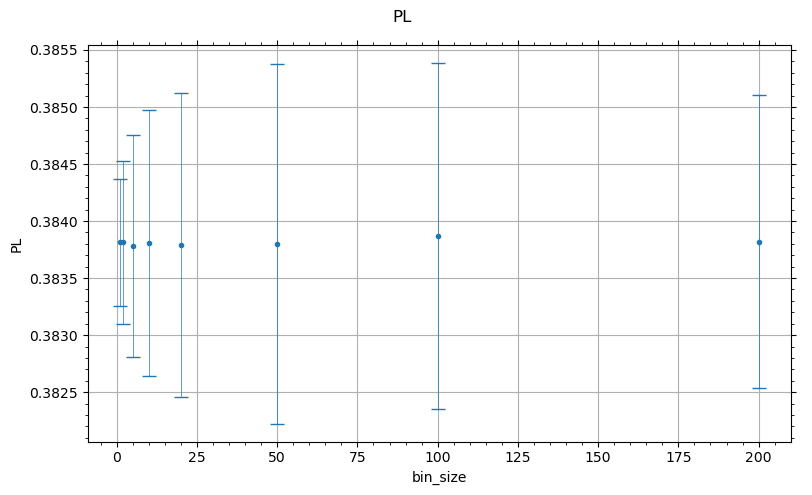

T = 171.29079861111111, mu = 0.15


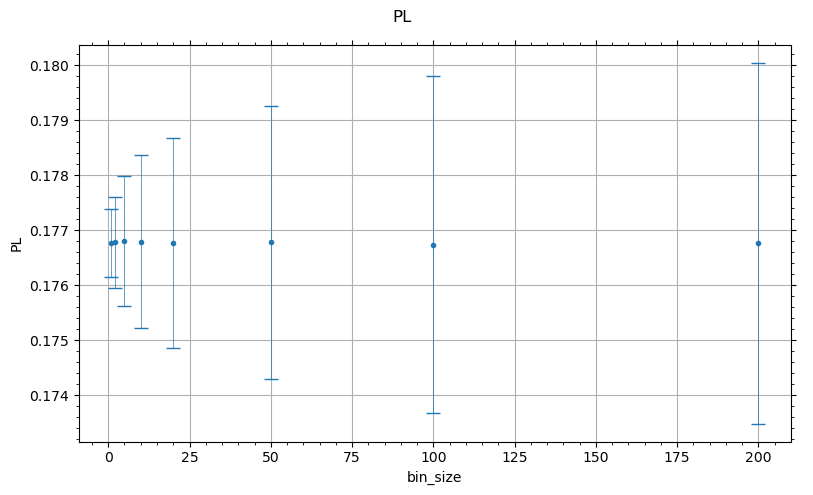

T = 171.29079861111111, mu = 0.2


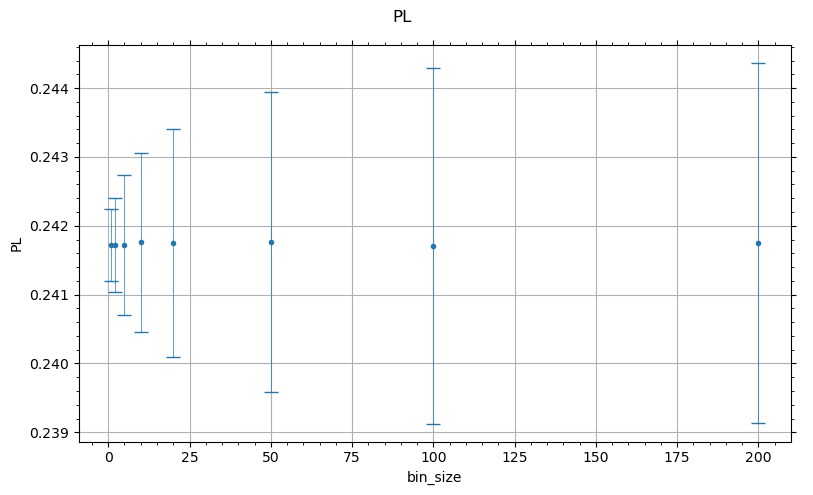

T = 171.29079861111111, mu = 0.25


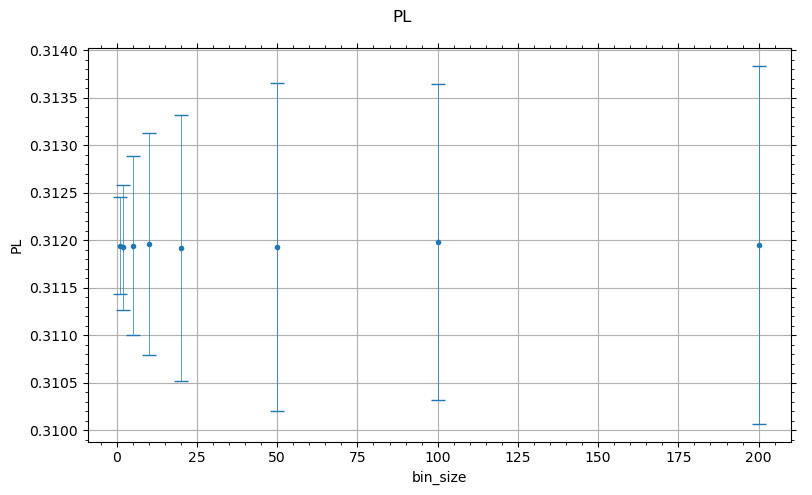

T = 171.29079861111111, mu = 0.0


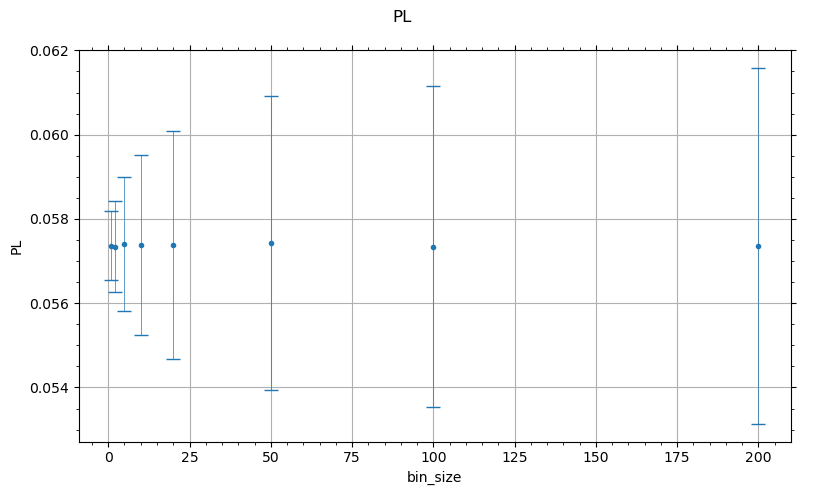

T = 171.29079861111111, mu = 0.05


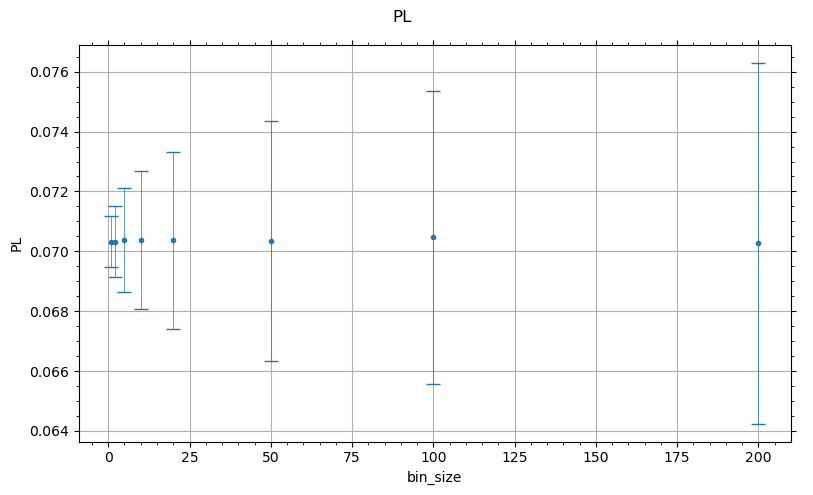

T = 186.8626893939394, mu = 0.1


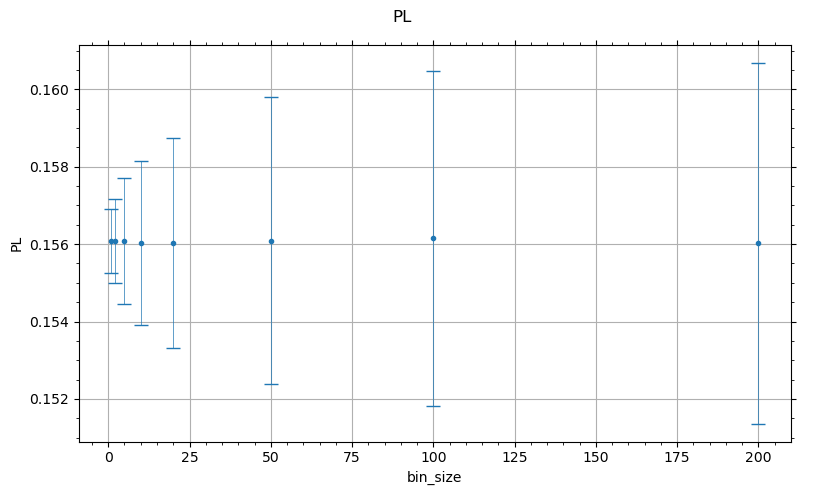

T = 186.8626893939394, mu = 0.3


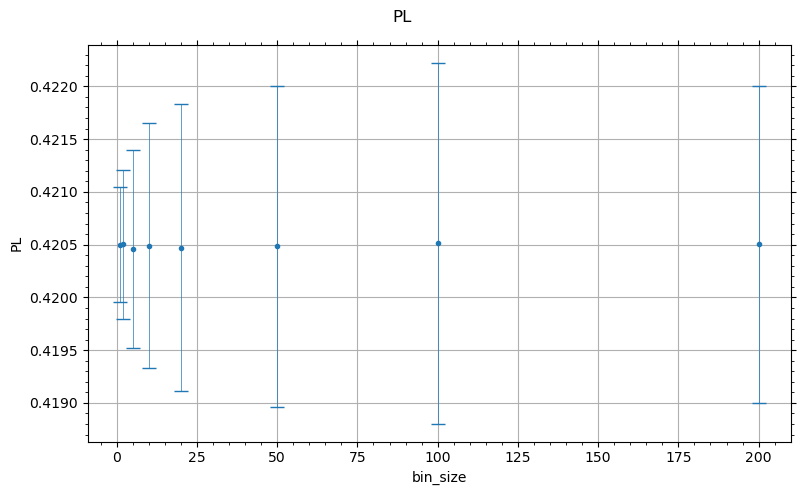

T = 186.8626893939394, mu = 0.15


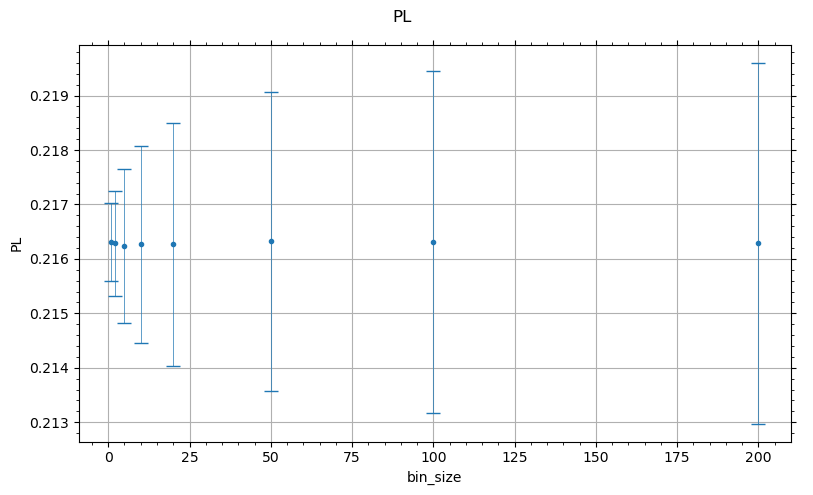

T = 186.8626893939394, mu = 0.2


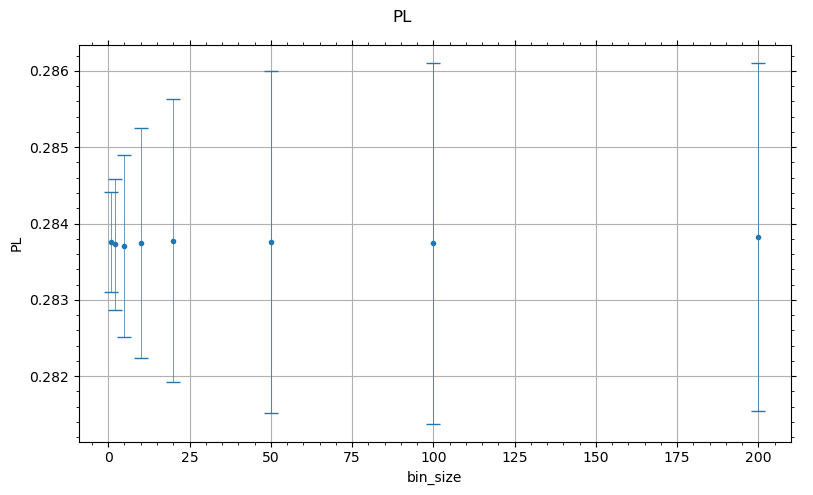

T = 186.8626893939394, mu = 0.25


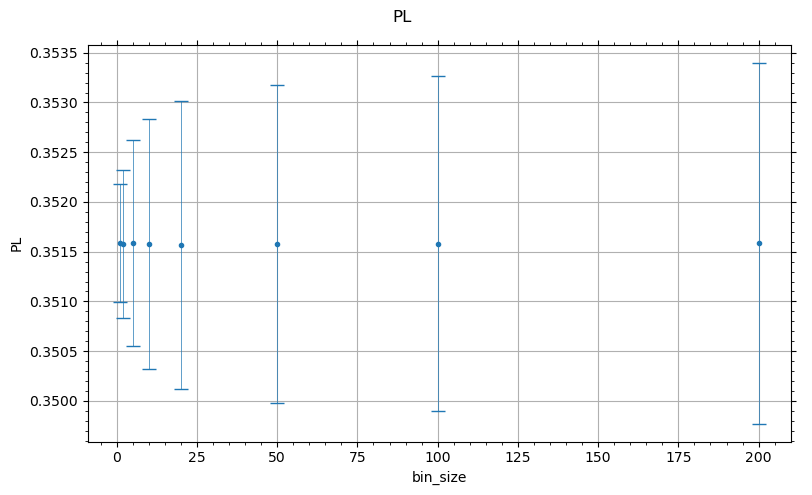

T = 186.8626893939394, mu = 0.0


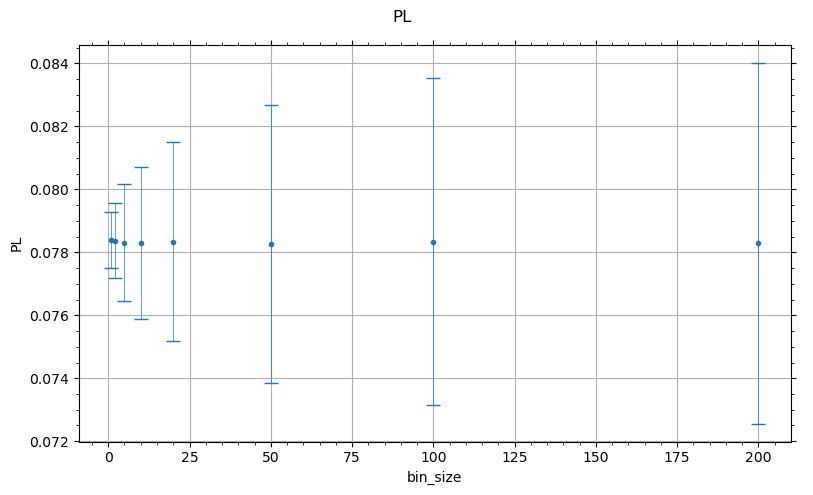

T = 186.8626893939394, mu = 0.05


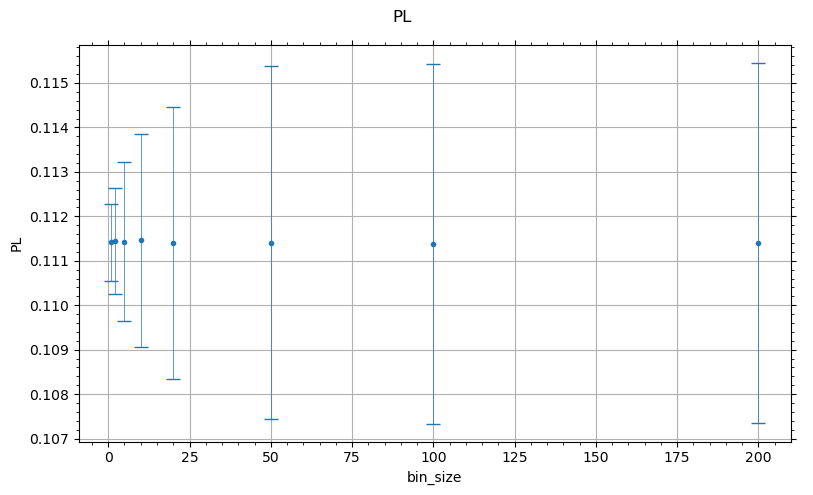

T = 186.8626893939394, mu = 0.03


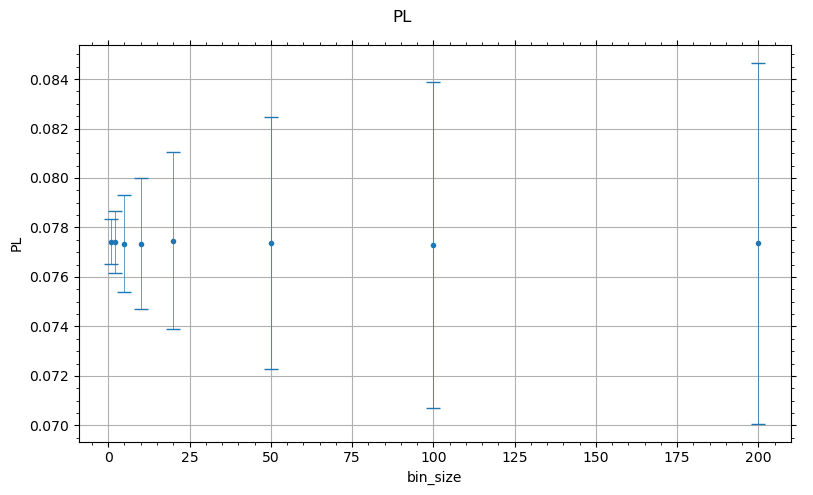

T = 186.8626893939394, mu = 0.07


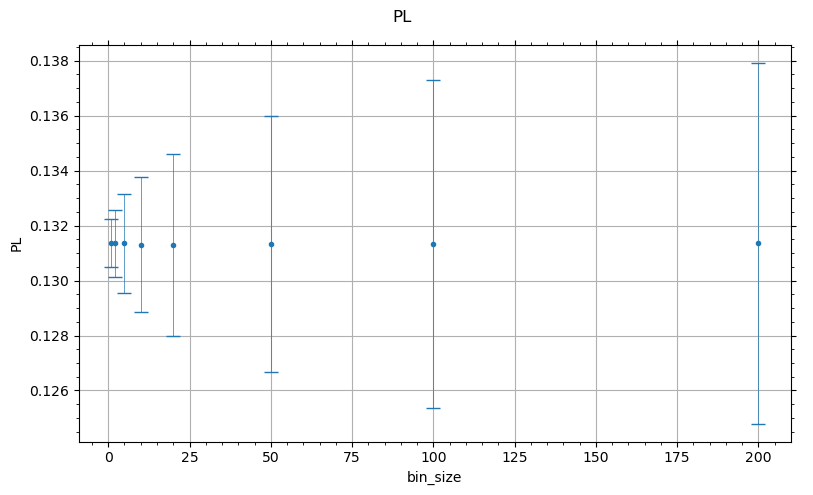

T = 186.8626893939394, mu = 0.12


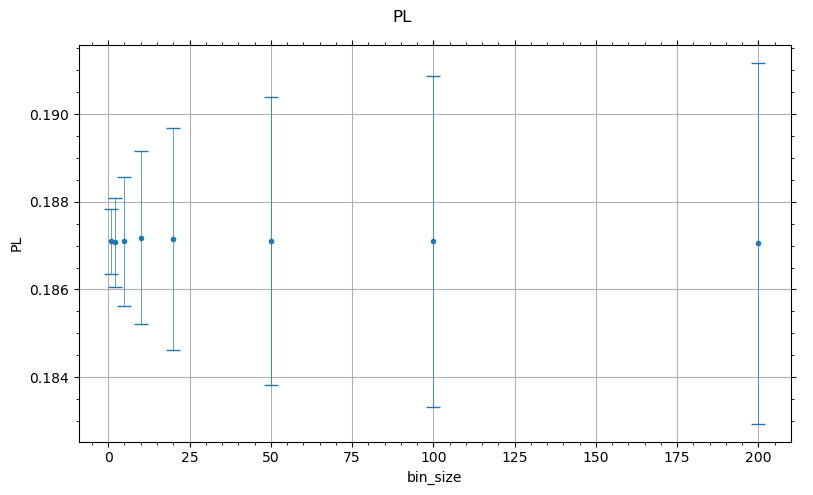

T = 205.54895833333333, mu = 0.1


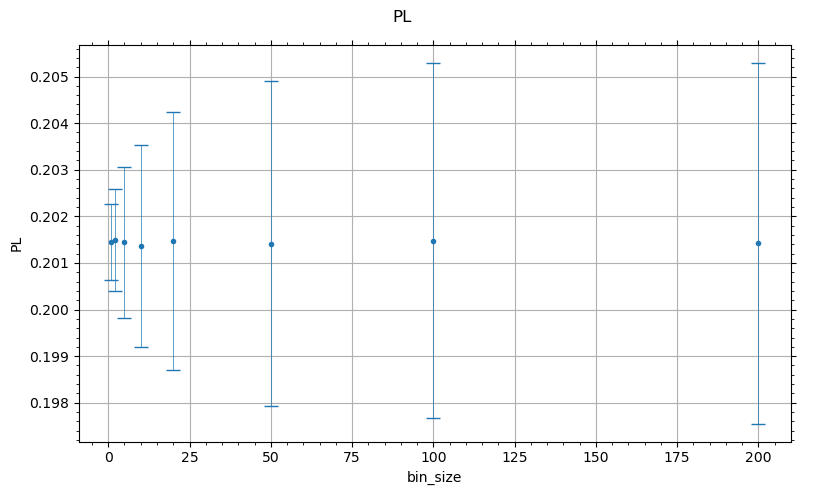

T = 205.54895833333333, mu = 0.3


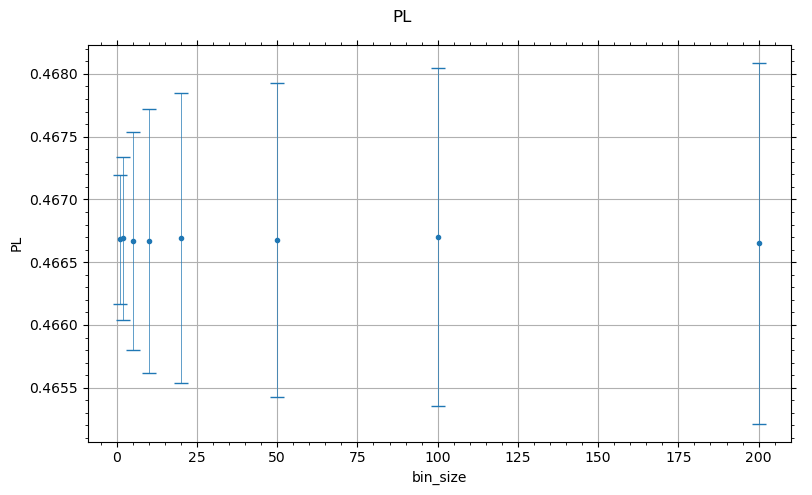

T = 205.54895833333333, mu = 0.15


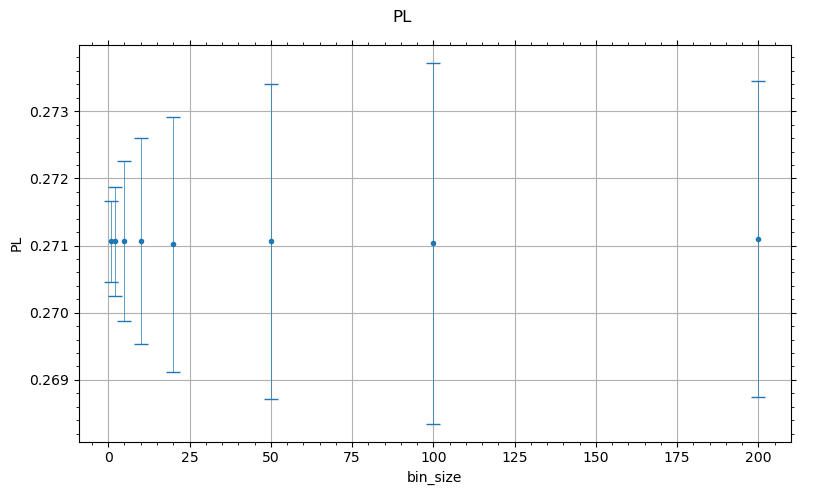

T = 205.54895833333333, mu = 0.2


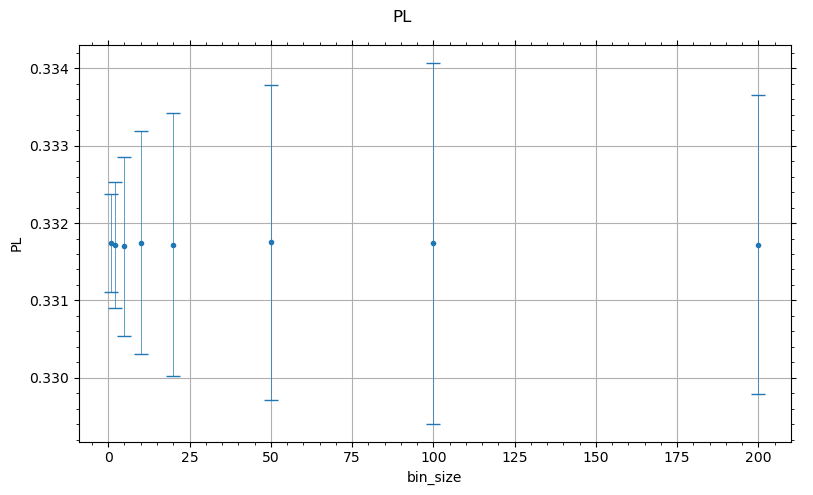

T = 205.54895833333333, mu = 0.25


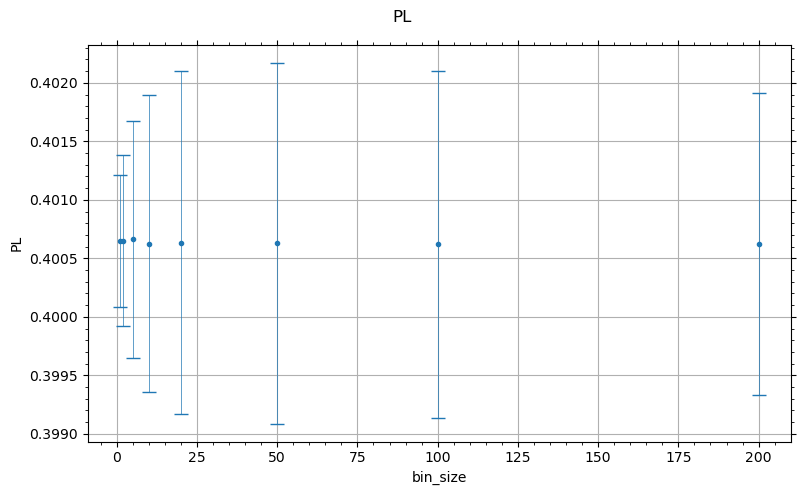

T = 205.54895833333333, mu = 0.0


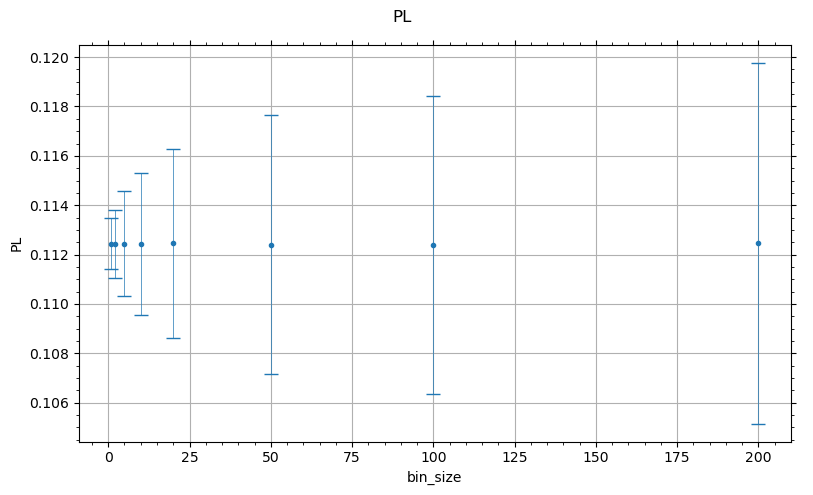

T = 205.54895833333333, mu = 0.05


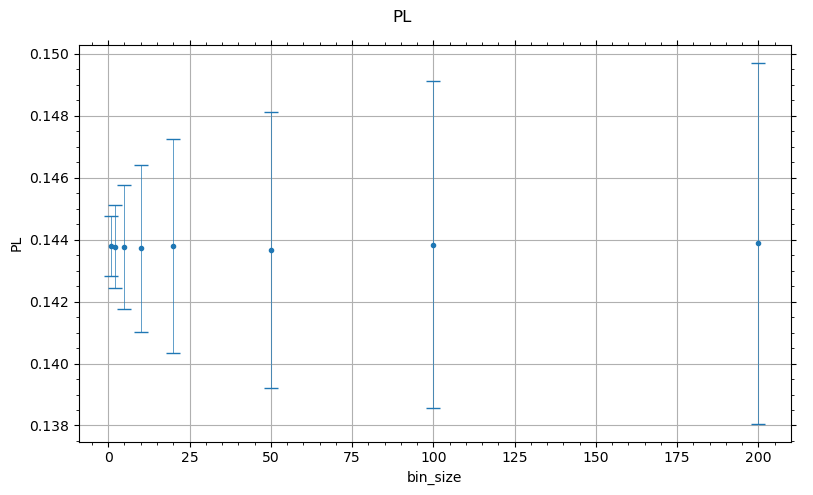

T = 205.54895833333333, mu = 0.03


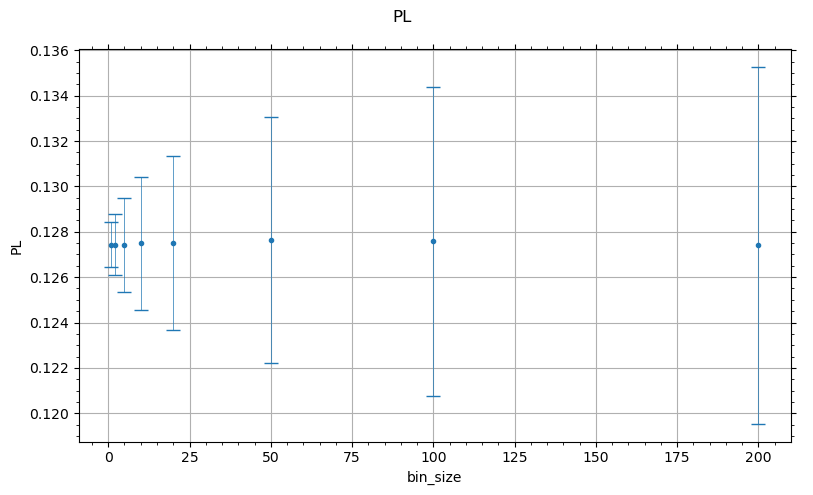

T = 205.54895833333333, mu = 0.07


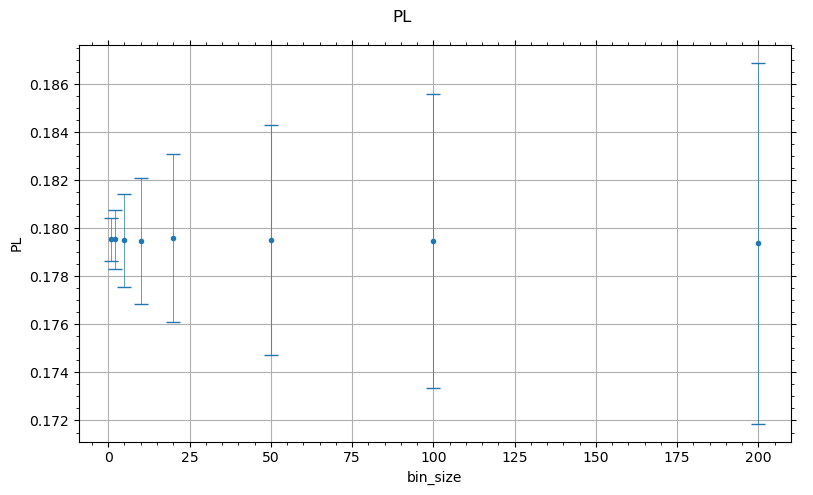

T = 205.54895833333333, mu = 0.12


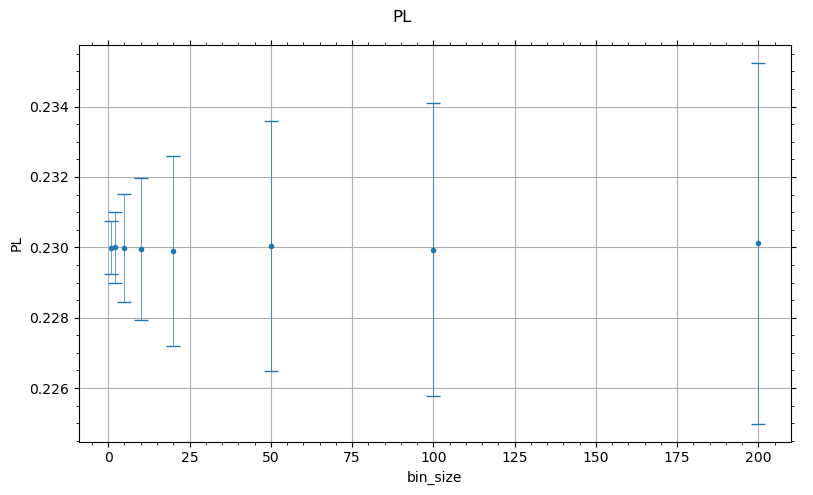

T = 228.38773148148147, mu = 0.1


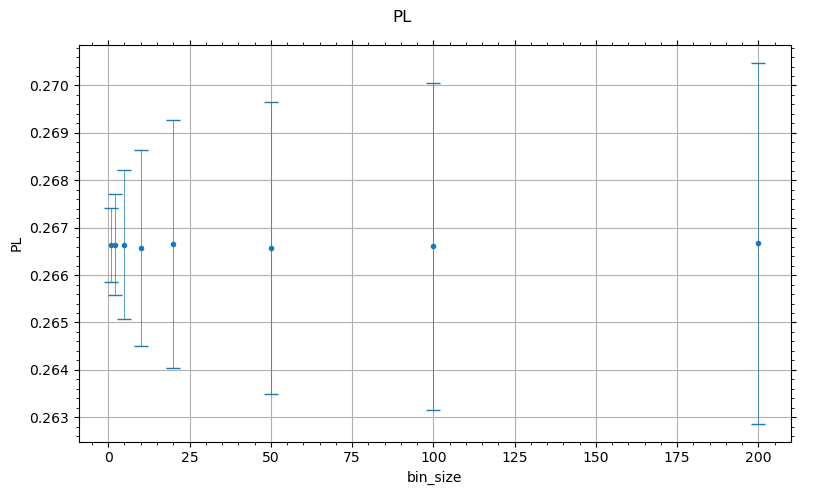

T = 228.38773148148147, mu = 0.3


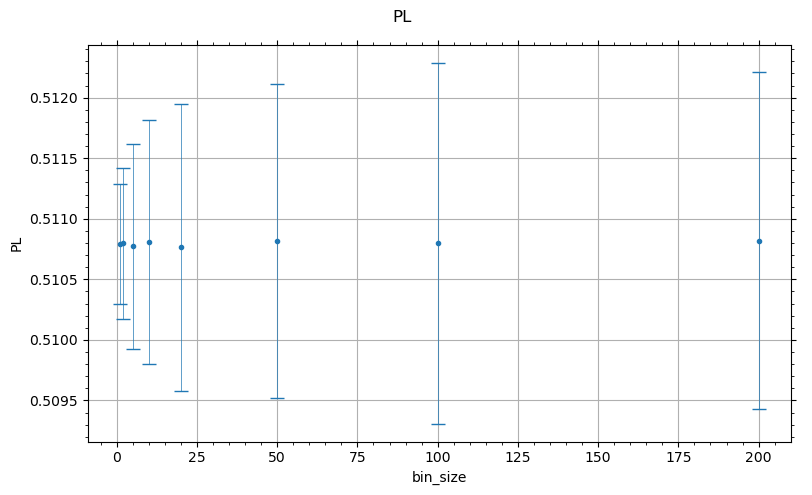

T = 228.38773148148147, mu = 0.15


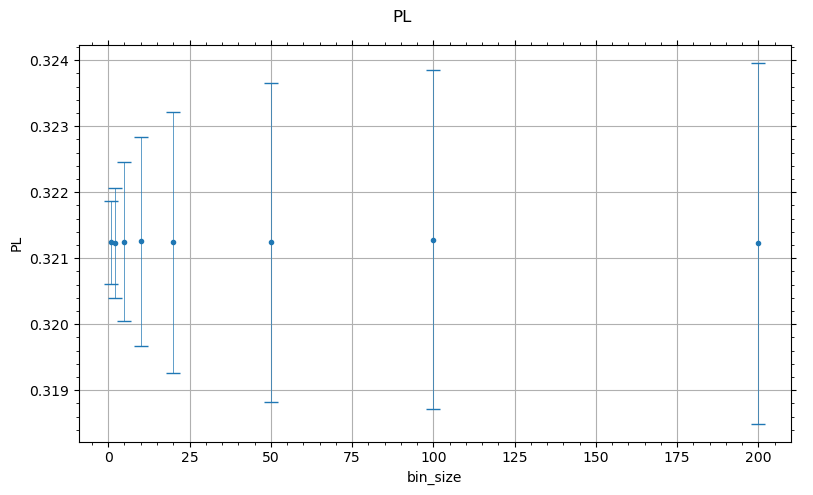

T = 228.38773148148147, mu = 0.2


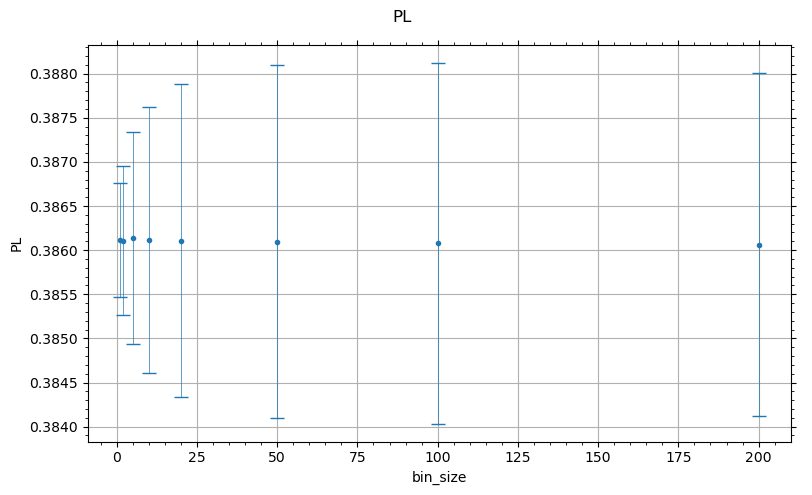

T = 228.38773148148147, mu = 0.25


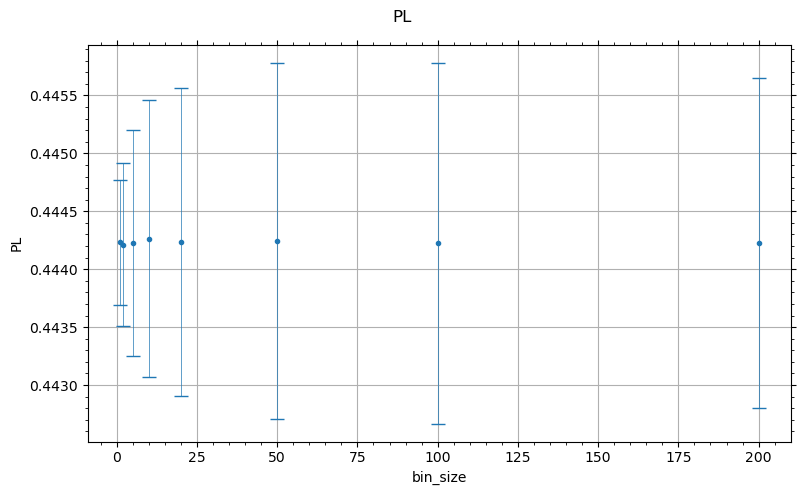

T = 228.38773148148147, mu = 0.0


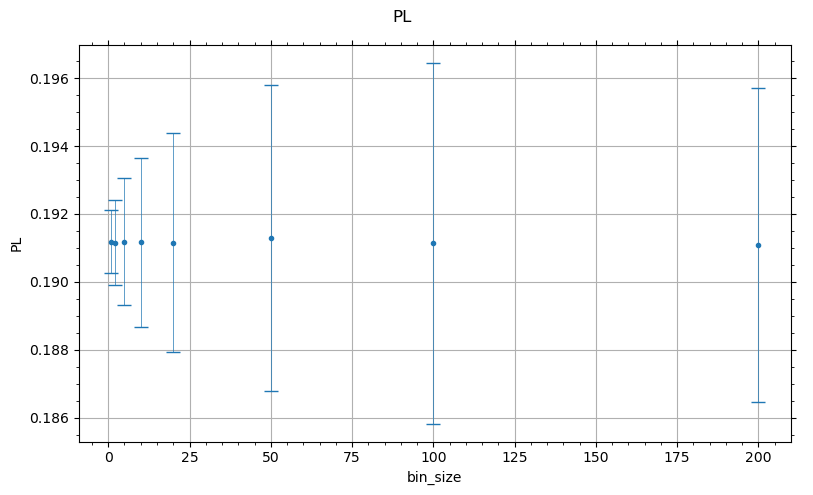

T = 228.38773148148147, mu = 0.05


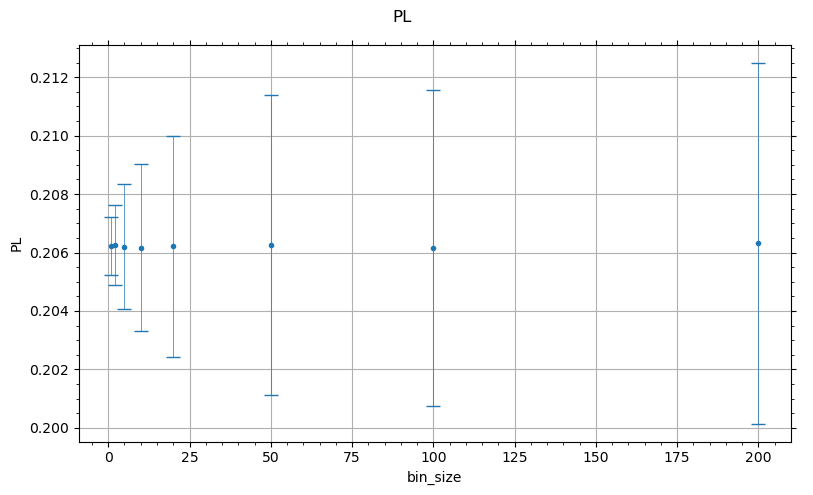

T = 228.38773148148147, mu = 0.03


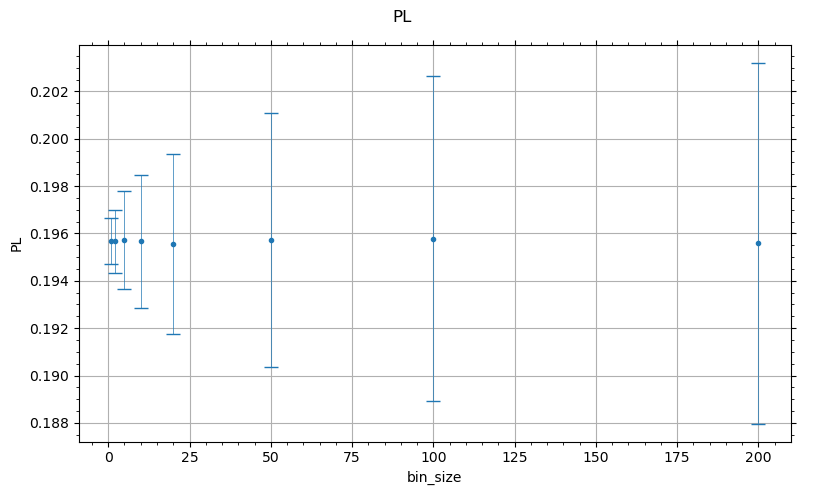

T = 228.38773148148147, mu = 0.07


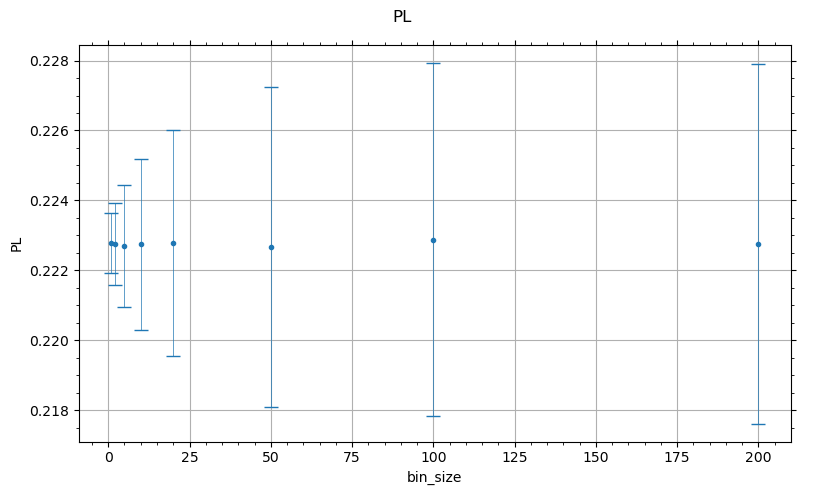

T = 228.38773148148147, mu = 0.12


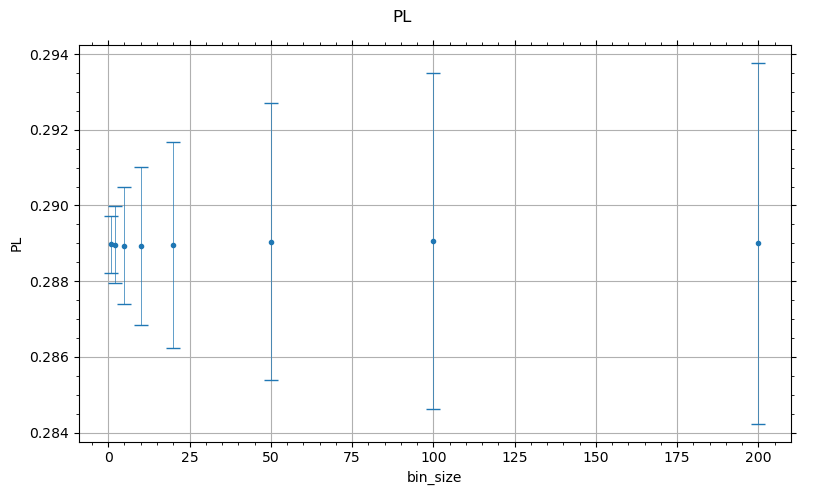

T = 256.9361979166667, mu = 0.1


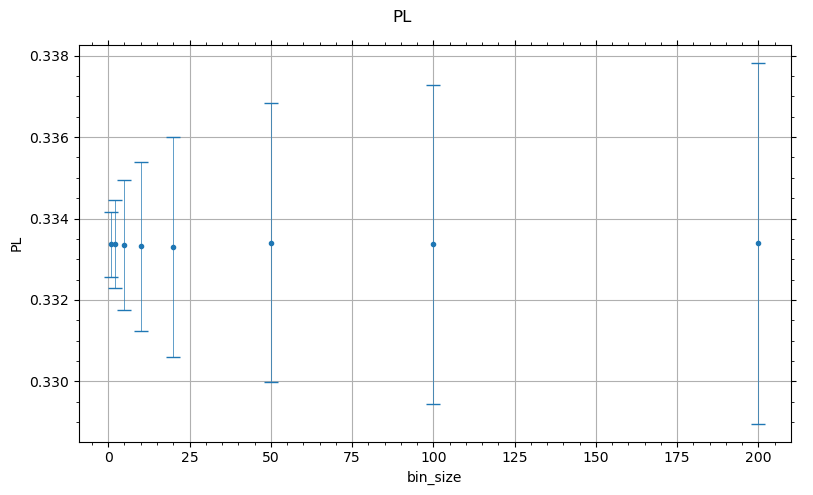

T = 256.9361979166667, mu = 0.3


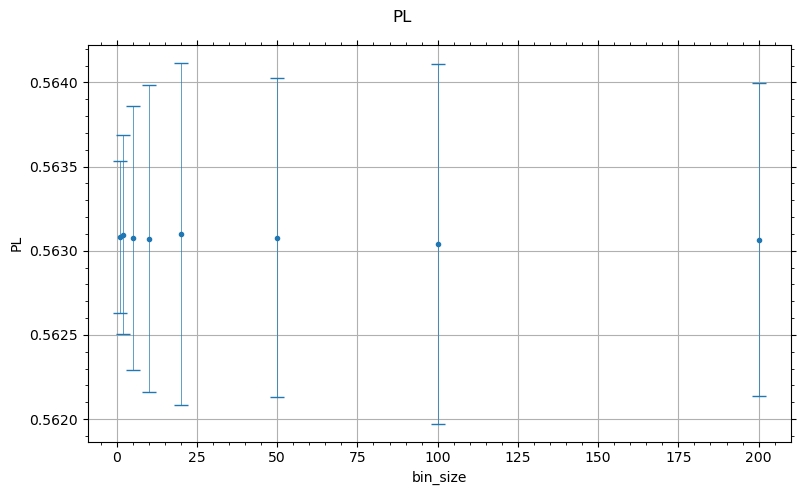

T = 256.9361979166667, mu = 0.15


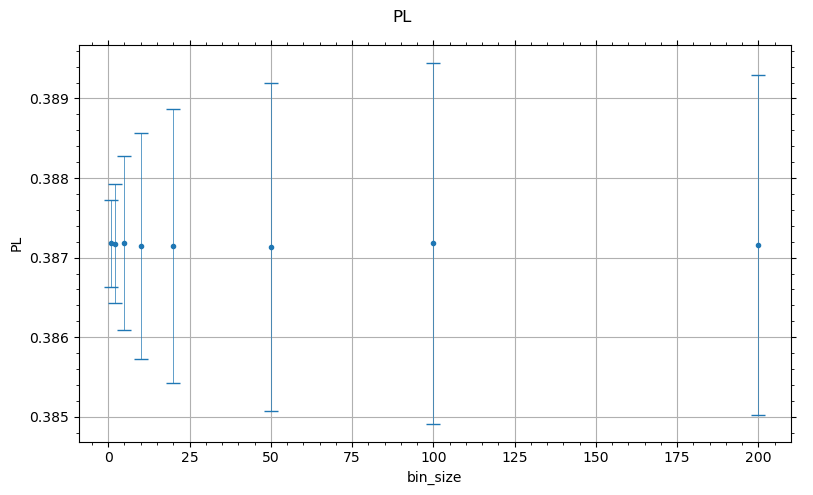

T = 256.9361979166667, mu = 0.2


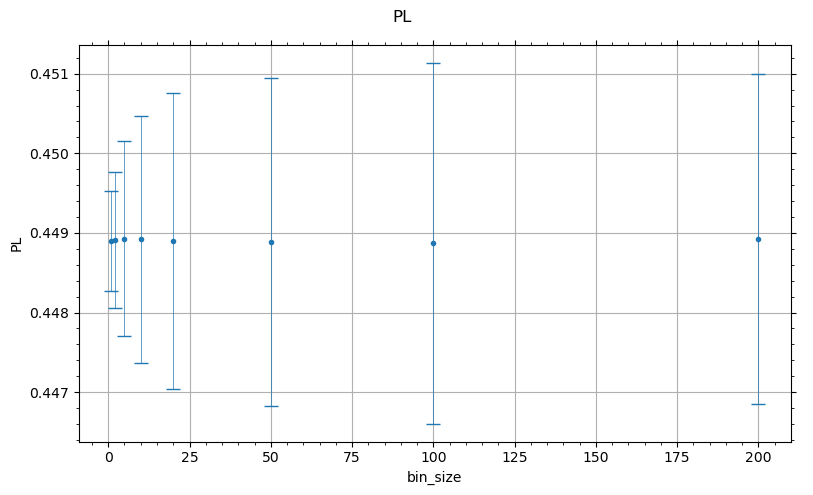

T = 256.9361979166667, mu = 0.25


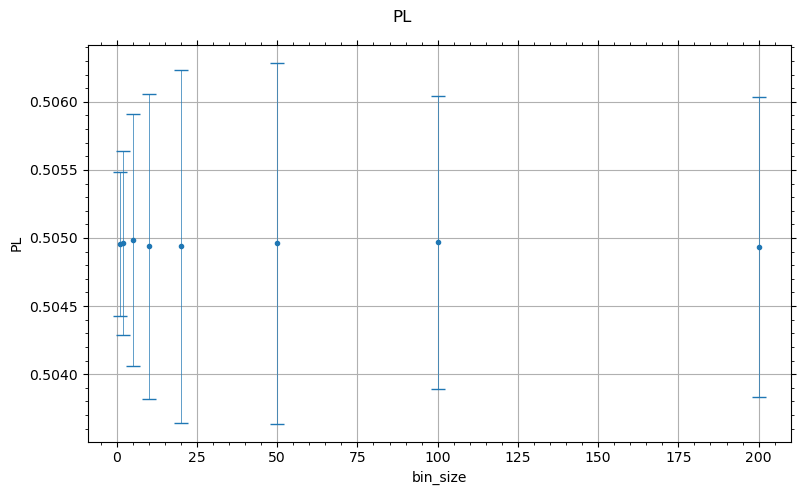

T = 256.9361979166667, mu = 0.0


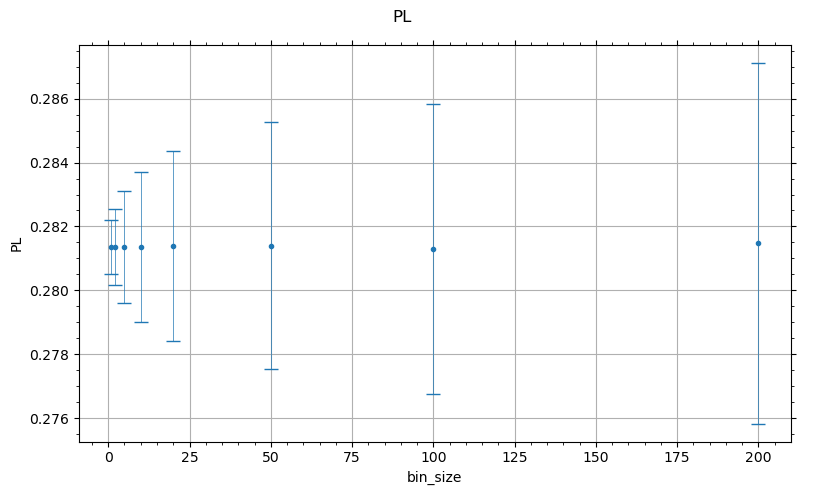

T = 256.9361979166667, mu = 0.05


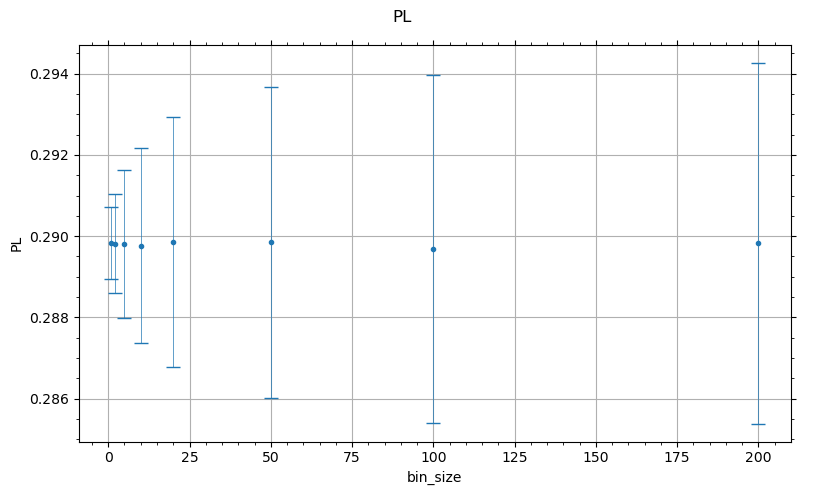

T = 256.9361979166667, mu = 0.03


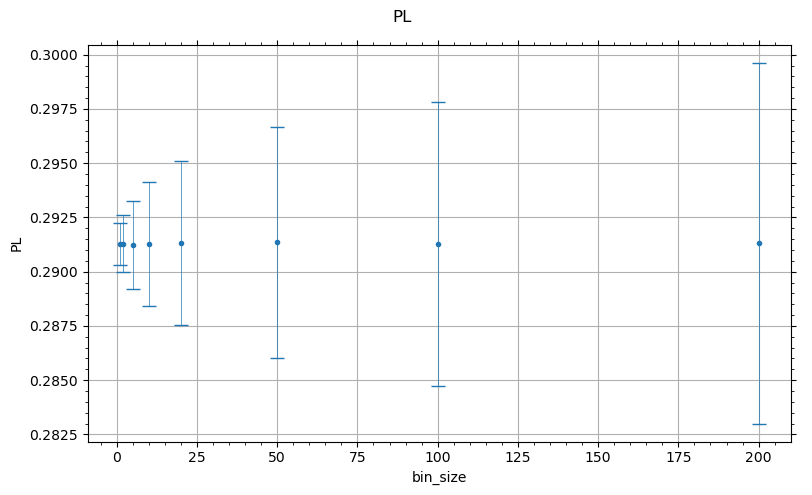

T = 256.9361979166667, mu = 0.07


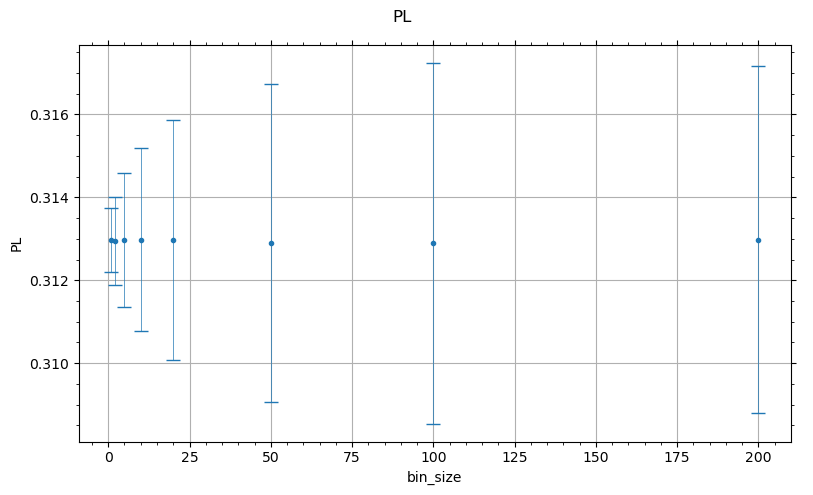

T = 256.9361979166667, mu = 0.12


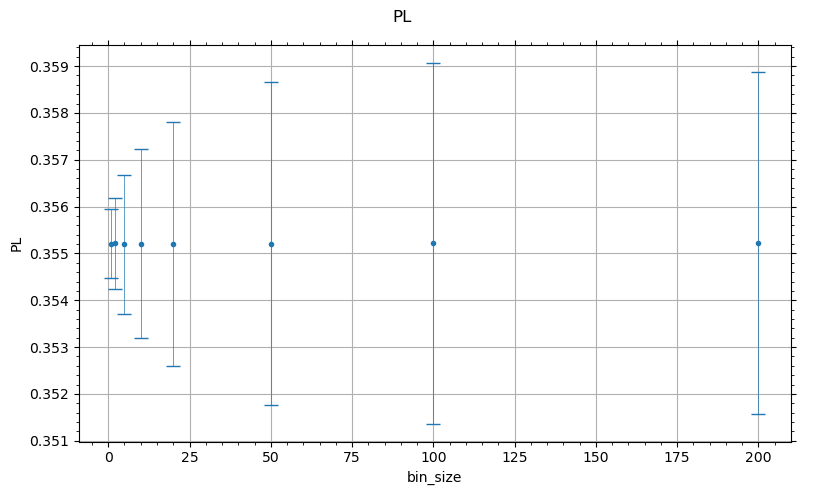

T = 293.64136904761904, mu = 0.1


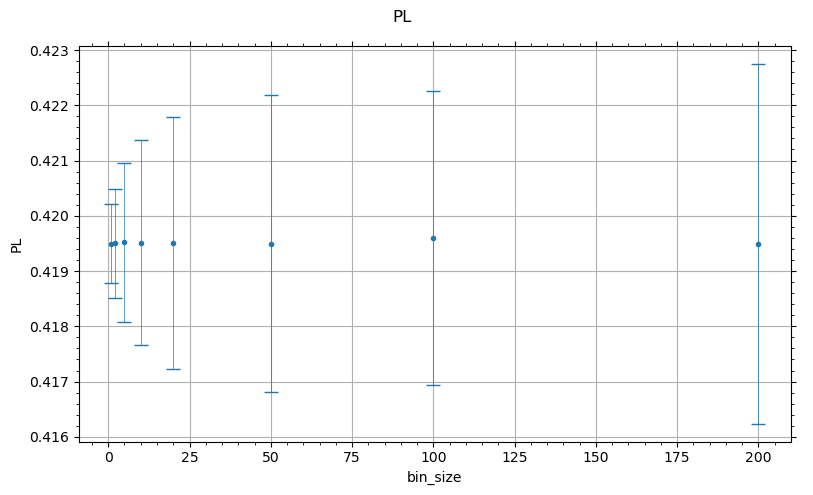

T = 293.64136904761904, mu = 0.3


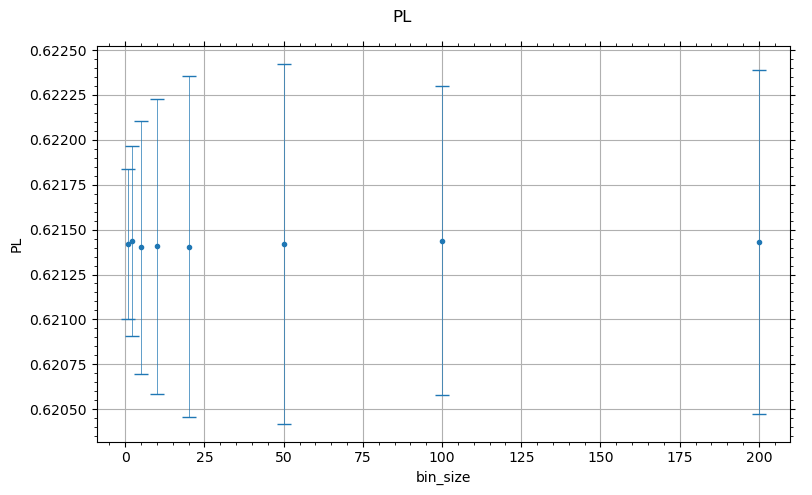

T = 293.64136904761904, mu = 0.15


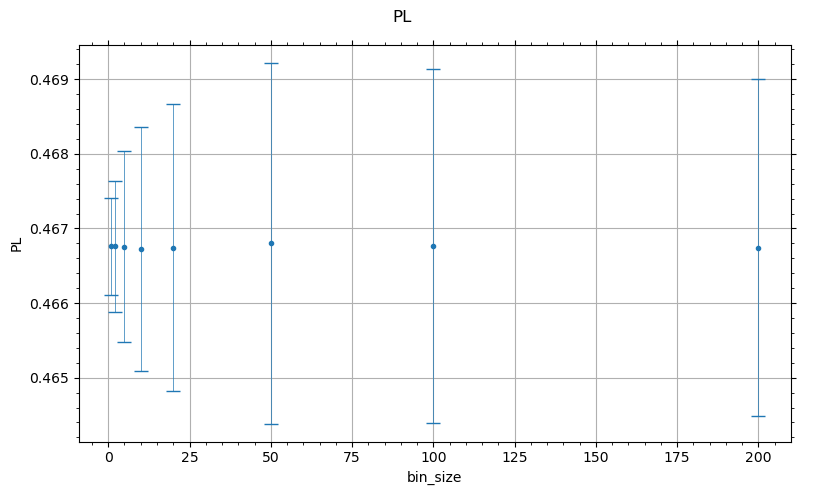

T = 293.64136904761904, mu = 0.2


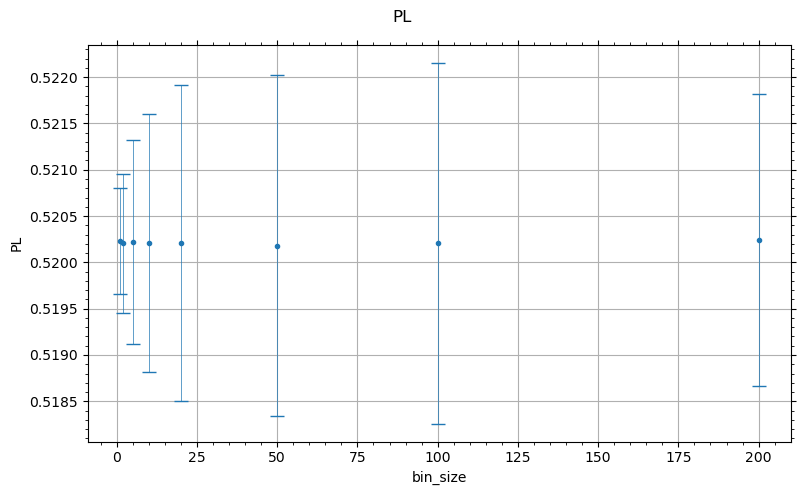

T = 293.64136904761904, mu = 0.25


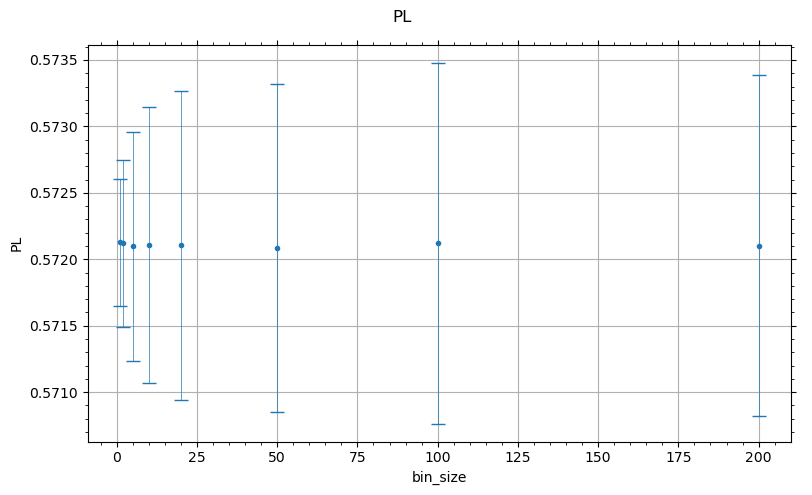

T = 293.64136904761904, mu = 0.0


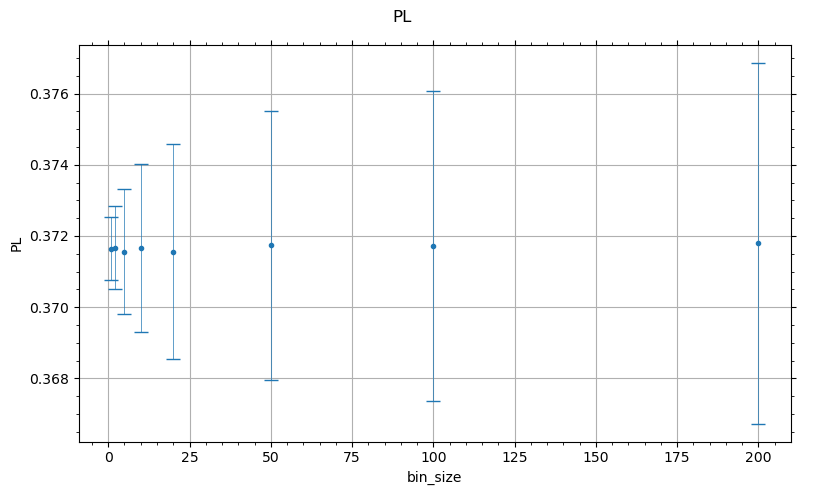

T = 293.64136904761904, mu = 0.05


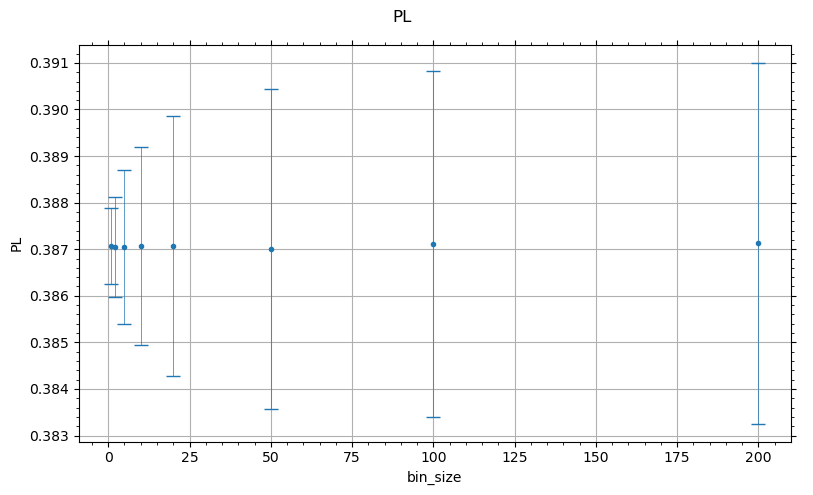

T = 293.64136904761904, mu = 0.03


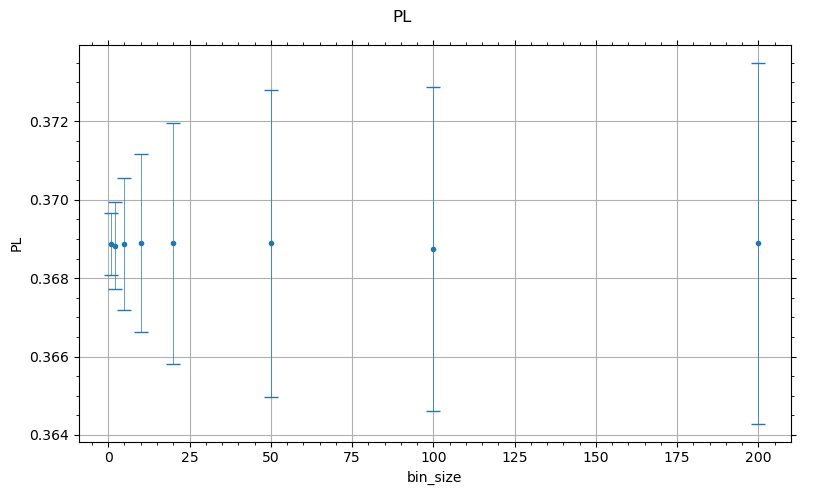

T = 293.64136904761904, mu = 0.07


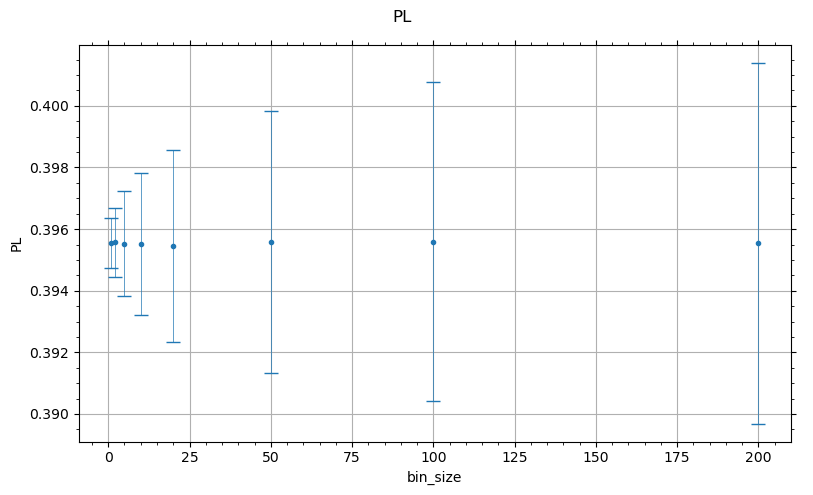

T = 293.64136904761904, mu = 0.12


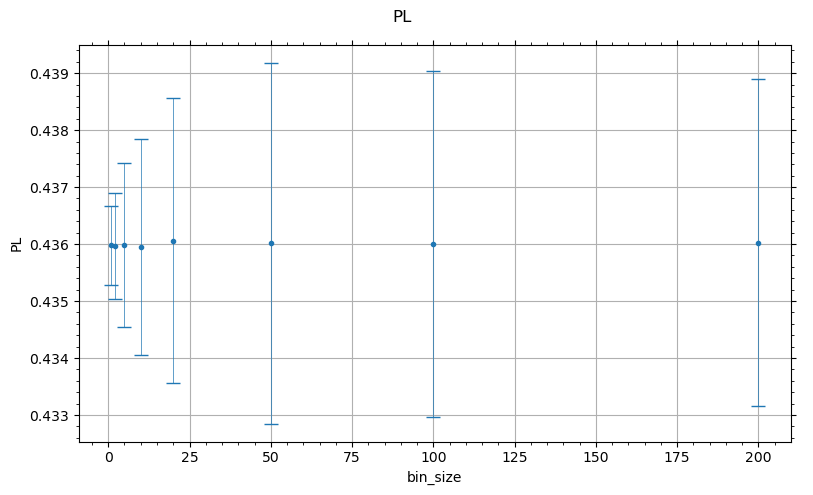

T = 342.58159722222223, mu = 0.1


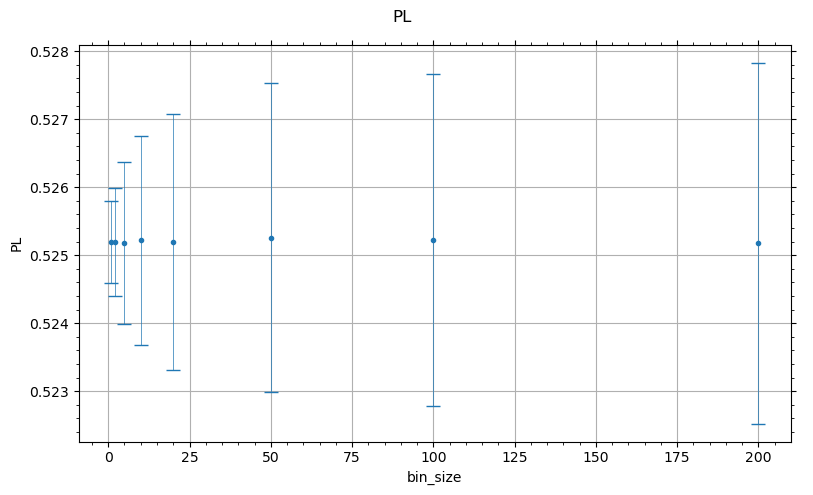

T = 342.58159722222223, mu = 0.3


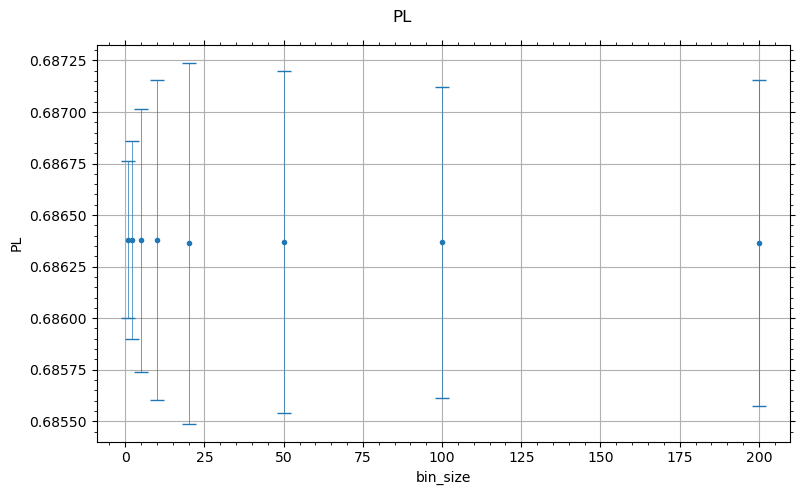

T = 342.58159722222223, mu = 0.15


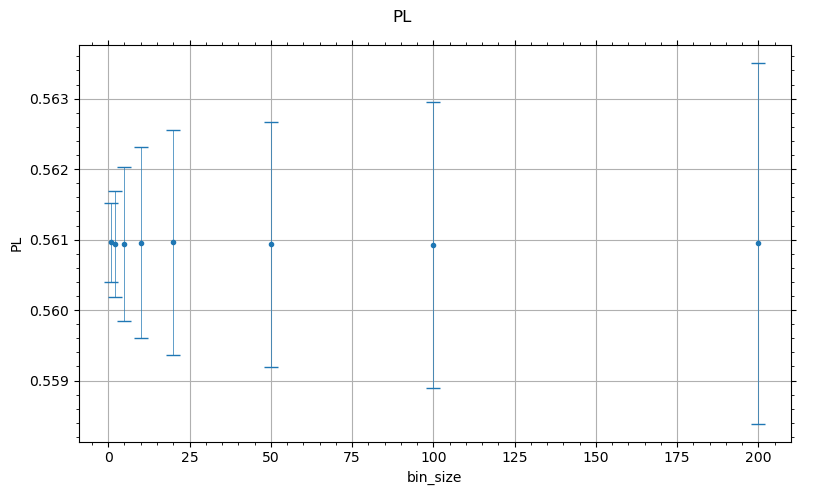

T = 342.58159722222223, mu = 0.2


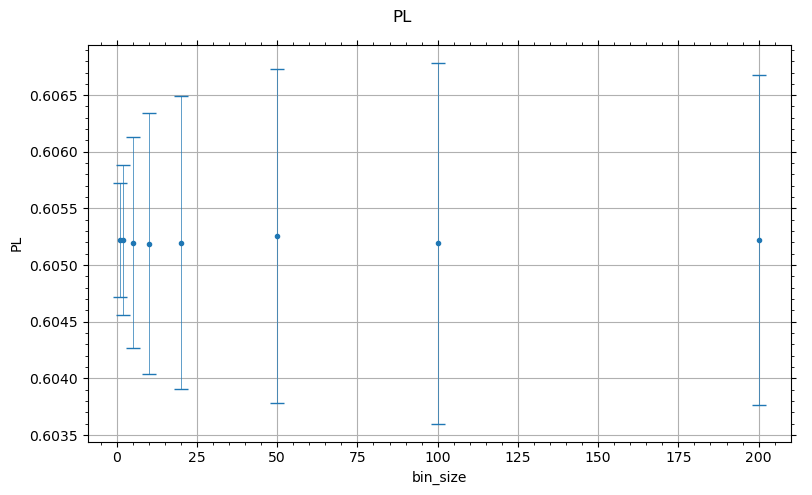

T = 342.58159722222223, mu = 0.25


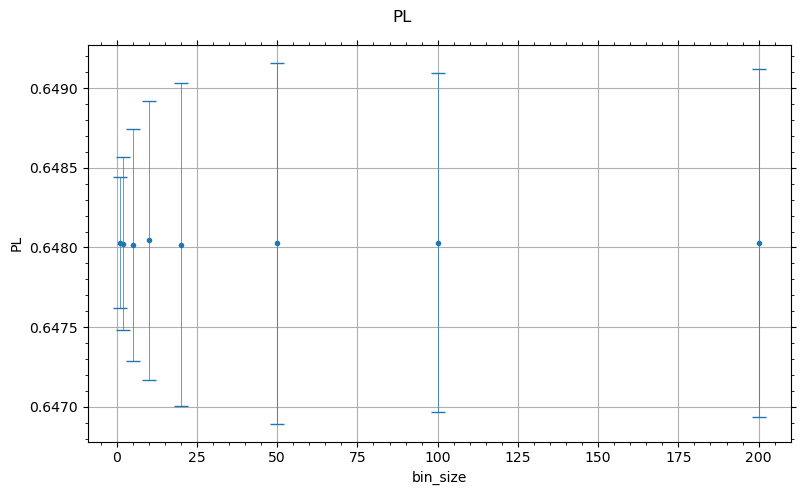

T = 342.58159722222223, mu = 0.0


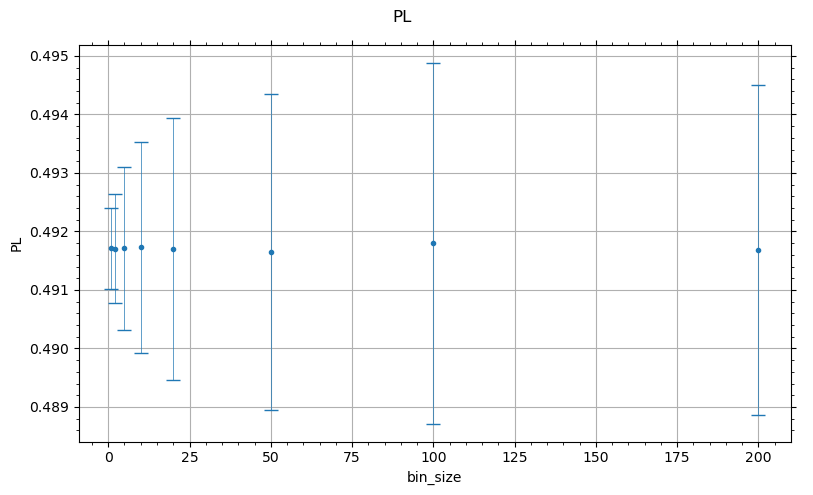

T = 342.58159722222223, mu = 0.05


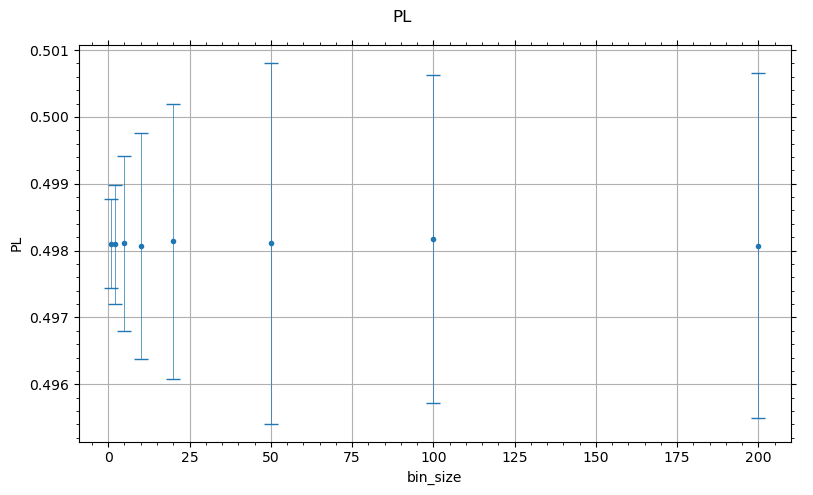

T = 342.58159722222223, mu = 0.03


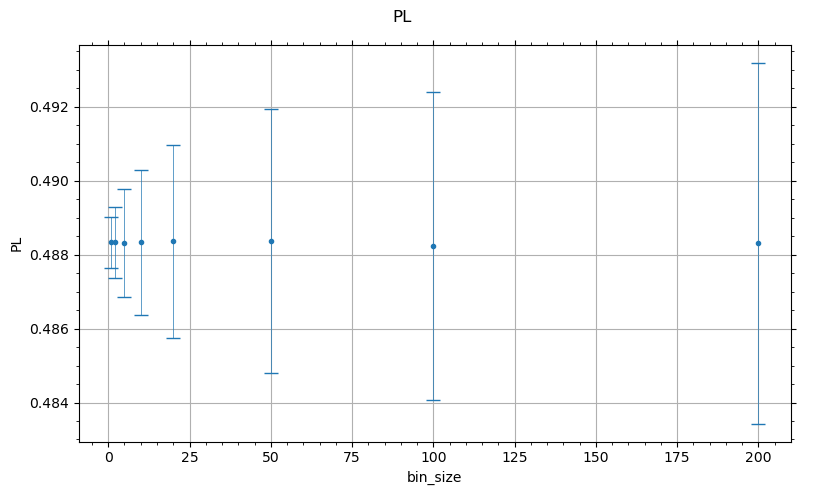

T = 342.58159722222223, mu = 0.07


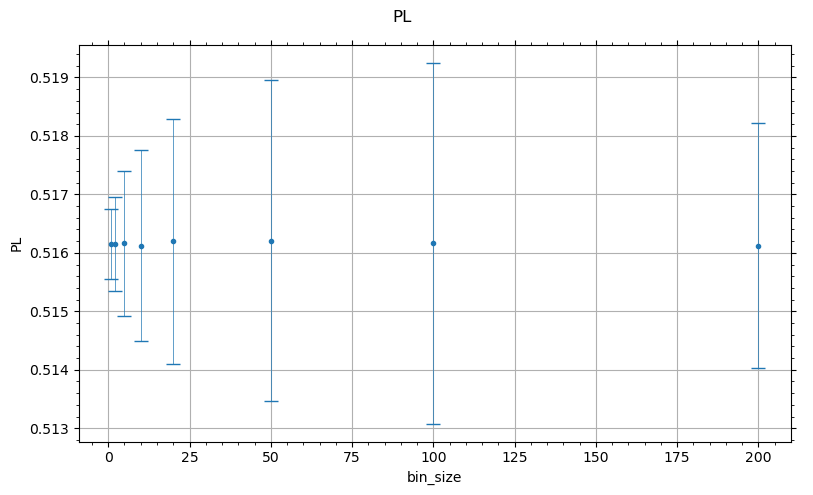

T = 411.09791666666666, mu = 0.1


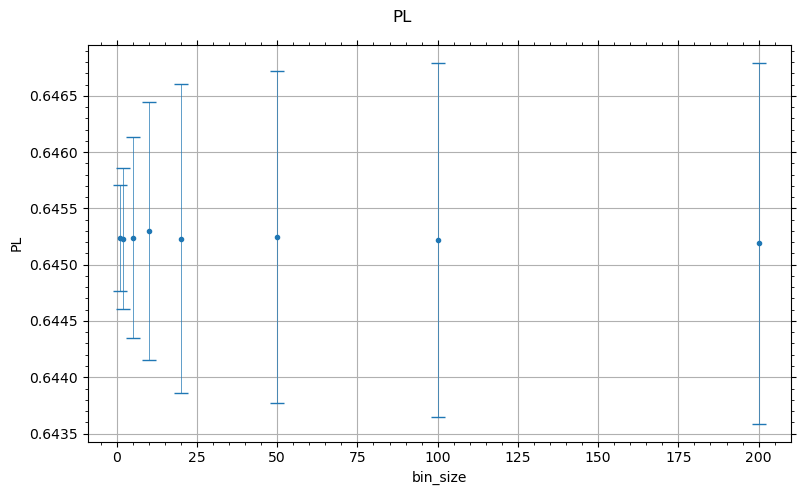

T = 411.09791666666666, mu = 0.3


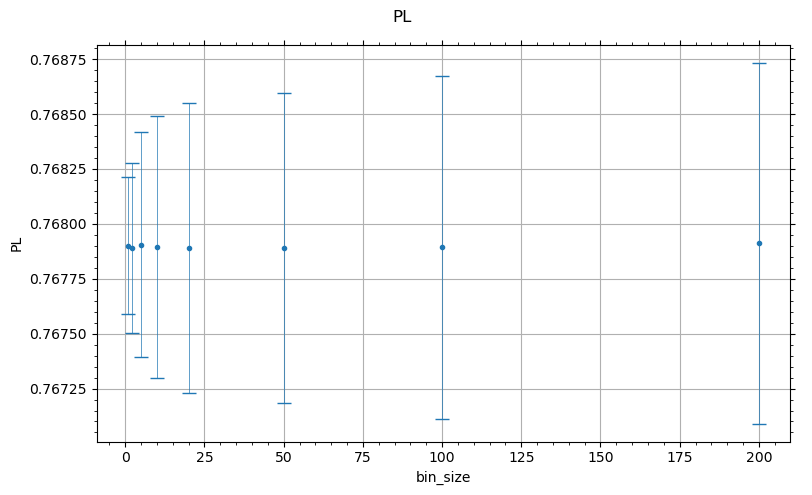

T = 411.09791666666666, mu = 0.15


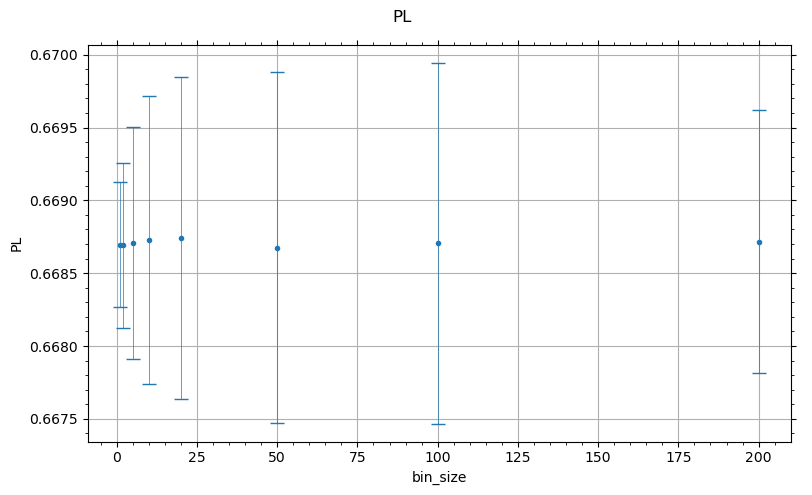

T = 411.09791666666666, mu = 0.2


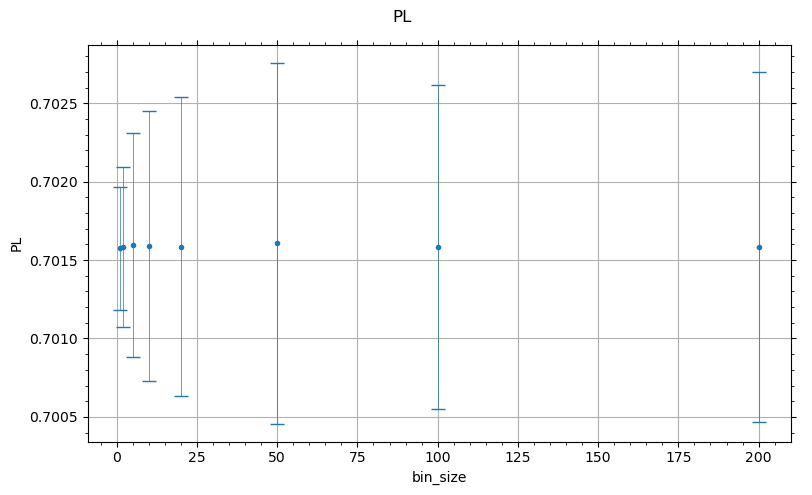

T = 411.09791666666666, mu = 0.25


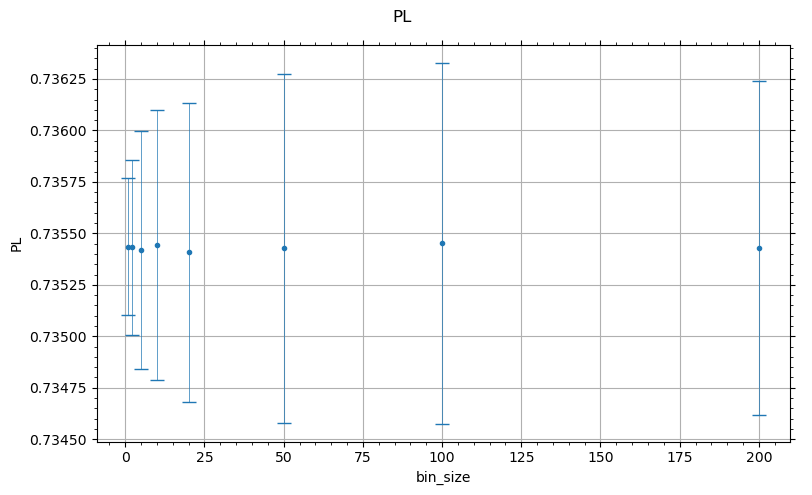

T = 411.09791666666666, mu = 0.0


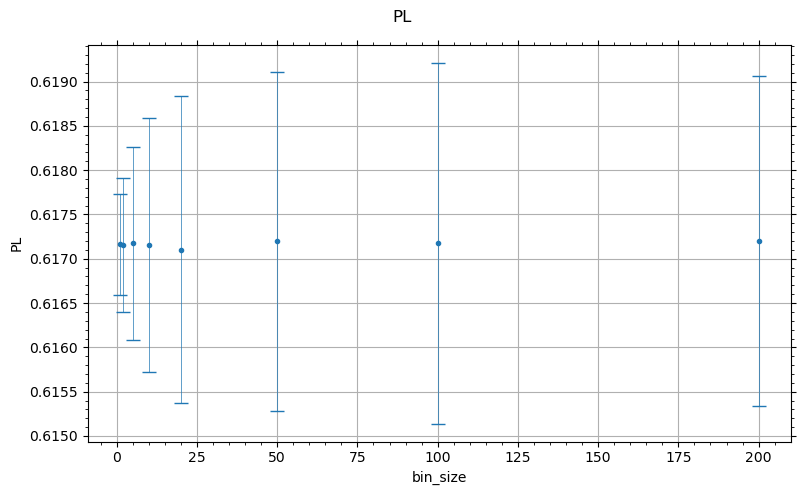

T = 411.09791666666666, mu = 0.05


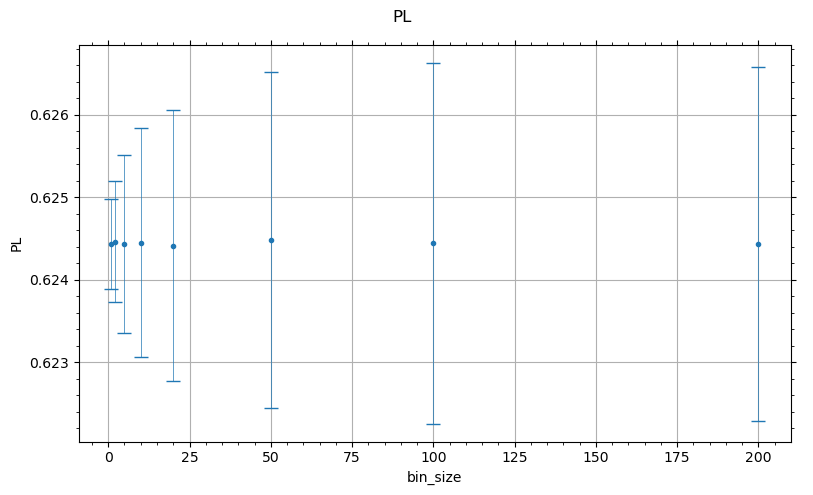

T = 411.09791666666666, mu = 0.03


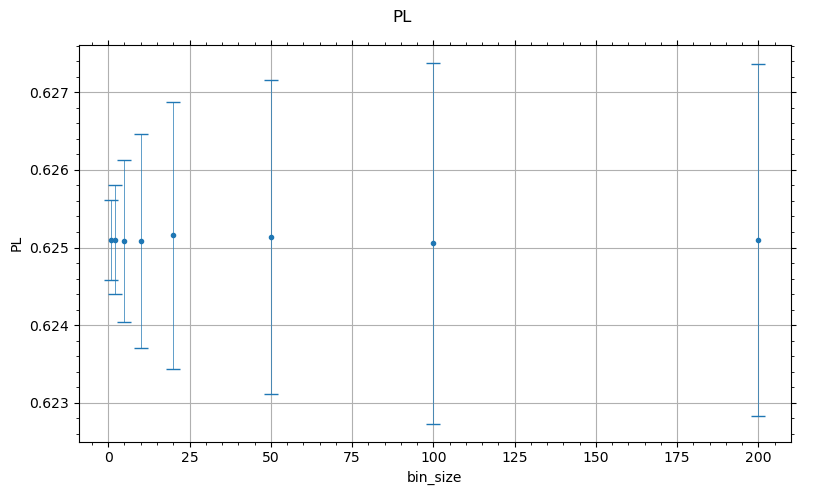

T = 411.09791666666666, mu = 0.07


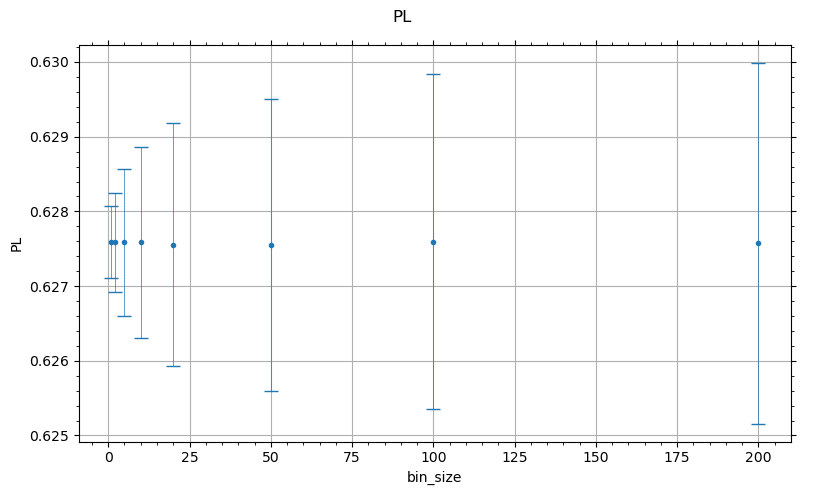

T = 513.8723958333334, mu = 0.15


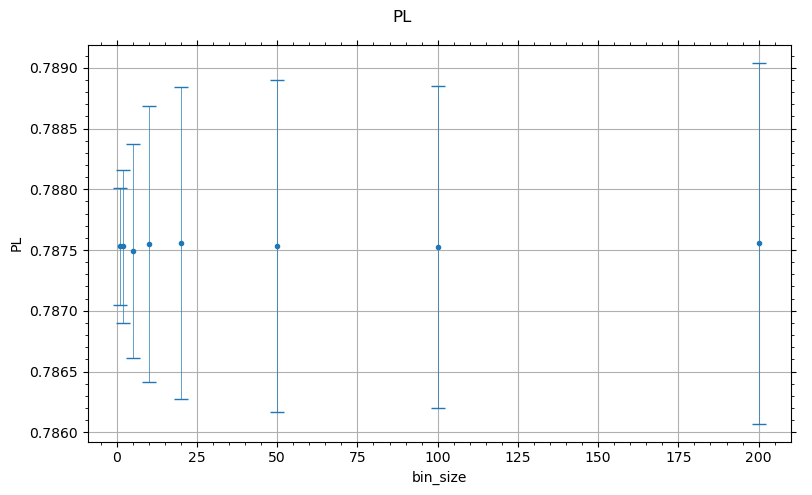

T = 513.8723958333334, mu = 0.0


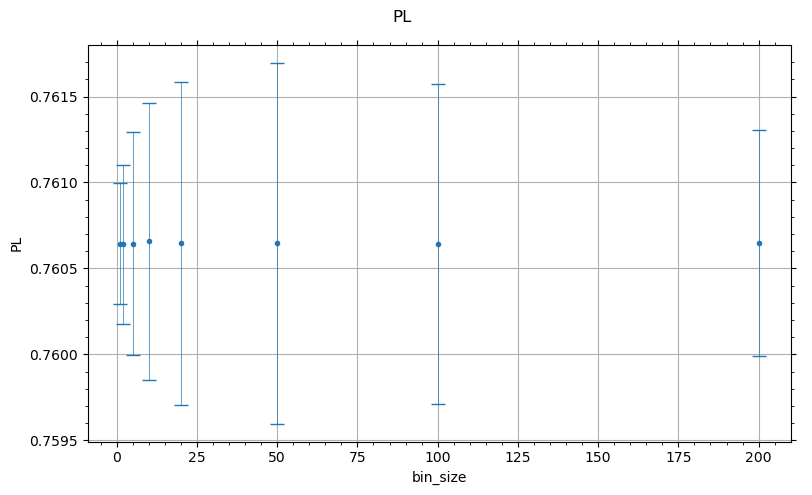

T = 685.1631944444445, mu = 0.0


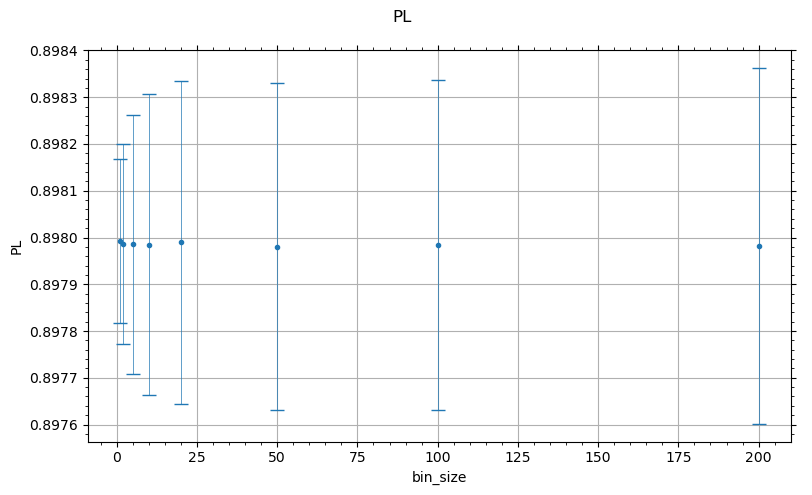

T = 1027.7447916666667, mu = 0.0


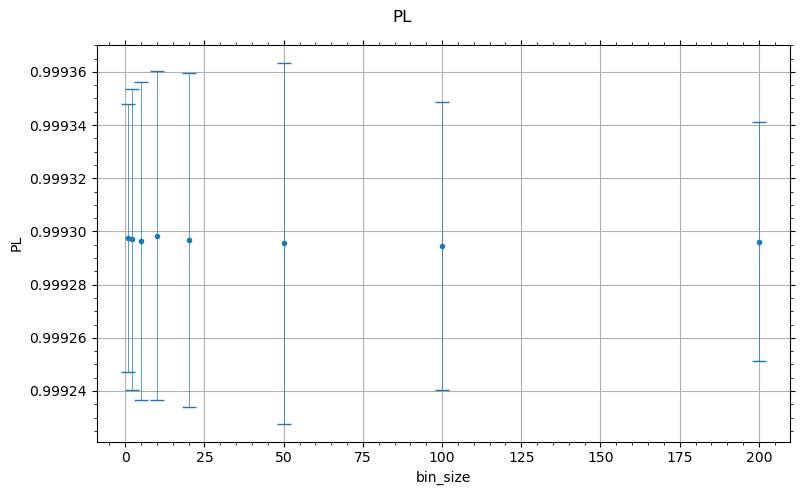

In [28]:
for T in df_binning['T'].unique():
    for mu in df_binning['mu'].unique():
        if df_binning[(df_binning['T'] == T) & (df_binning['mu'] == mu)].empty:
            continue
        print(f'T = {T}, mu = {mu}')
        # fg = seaborn.FacetGrid(data=df1[(df1['Nt'] == Nt) & (df1['mu'] == mu)], height=5, aspect=1.2)
        # fg.map(plt.plot, 'enumeration', 'PL').add_legend()
        plots.plot_potential_single(df_binning[(df_binning['T'] == T) & (df_binning['mu'] == mu)], 'bin_size', 'PL', None, 'bin_size', 'PL', 'PL', f'../../images/potential/su2/qc2dstag/', f'bin size dependence mu={mu} T={T}', True, err='PL_err')
        plt.show()

In [ ]:
df_entropy = df.groupby(['mu', 'Ns']).apply(entropy_sample, 5000, include_groups=False).reset_index(level=['mu', 'Ns'])
# df_entropy = df.groupby(['mu', 'Ns']).apply(entropy_sample_binning, 5000, 1, include_groups=False).reset_index(level=['mu'])

/tmp/ipykernel_15295/3323993112.py:16: RuntimeWarning: invalid value encountered in log
  entropy.append((T_arr[j + 1] * np.log(means[j + 1]) - T_arr[j] * np.log(means[j])) / (T_arr[j + 1] - T_arr[j]))


In [47]:
df1 = df_entropy.groupby(['T', 'mu'])['entropy']\
                      .agg([('entropy', 'mean'), ('err', lambda x: np.std(x, ddof=0))]).reset_index(level=['T', 'mu'])

In [ ]:
df_entropy1 = df.groupby(['mu']).apply(entropy_sample_binning, 5000, 50, include_groups=False).reset_index(level=['mu'])

In [55]:
df2 = df_entropy1.groupby(['T', 'mu'])['entropy']\
                      .agg([('entropy', 'mean'), ('err', lambda x: np.std(x, ddof=0))]).reset_index(level=['T', 'mu'])

In [56]:
df1['method'] = 'entropy_sample'
df2['method'] = 'entropy_sample_binning'
df_entropy_comparison = pd.concat([df1, df2])

T = 96.35107421875


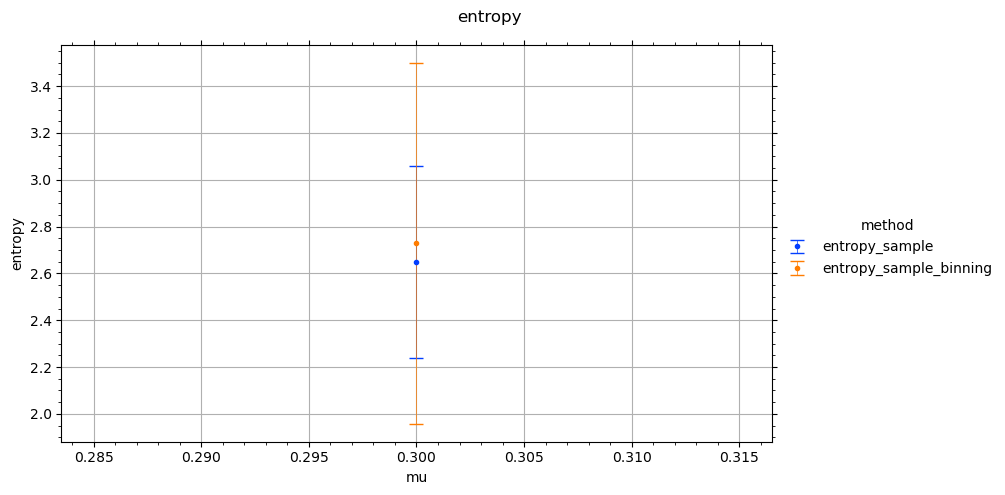

T = 108.4841724537037


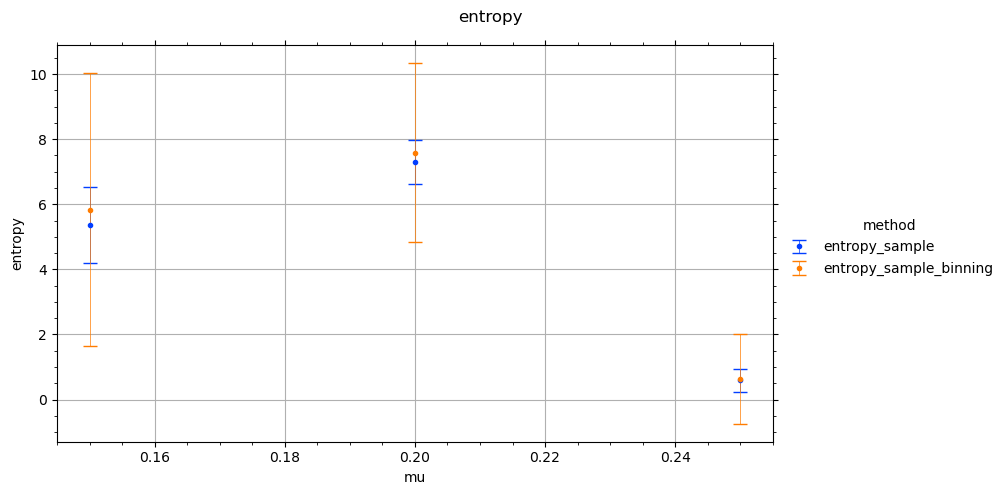

T = 117.76242404513889


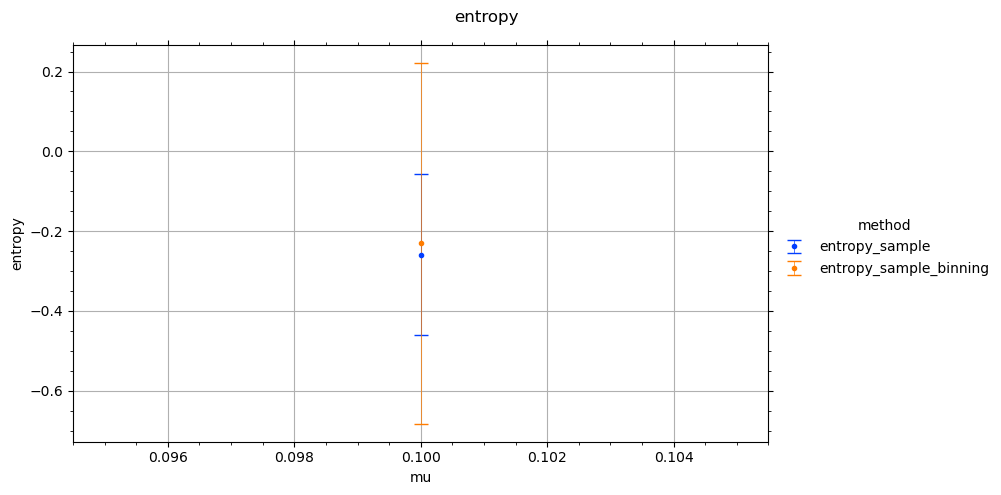

T = 121.33098234953704


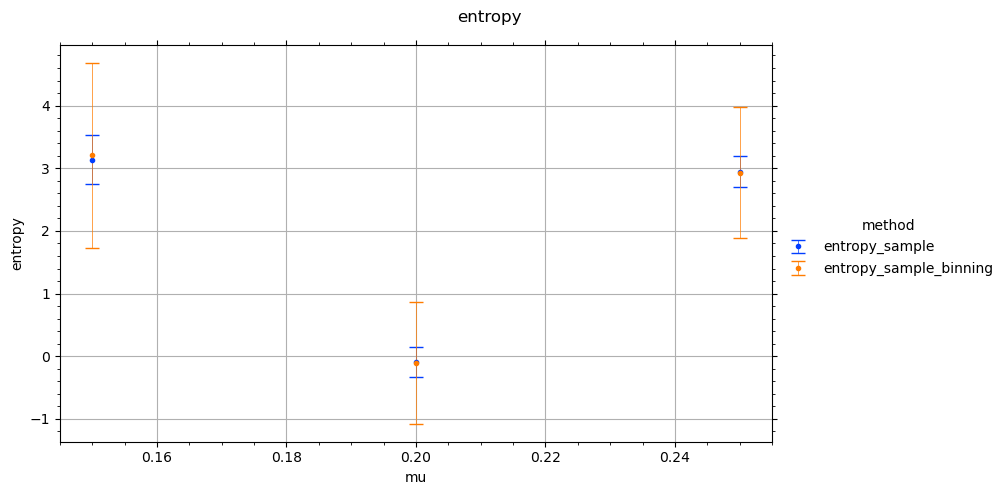

T = 137.64439174107144


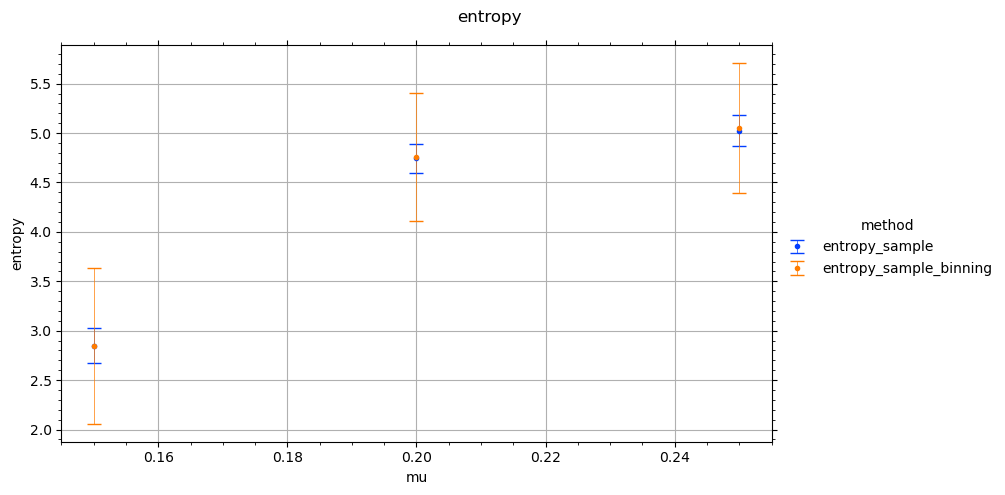

T = 143.29134114583334


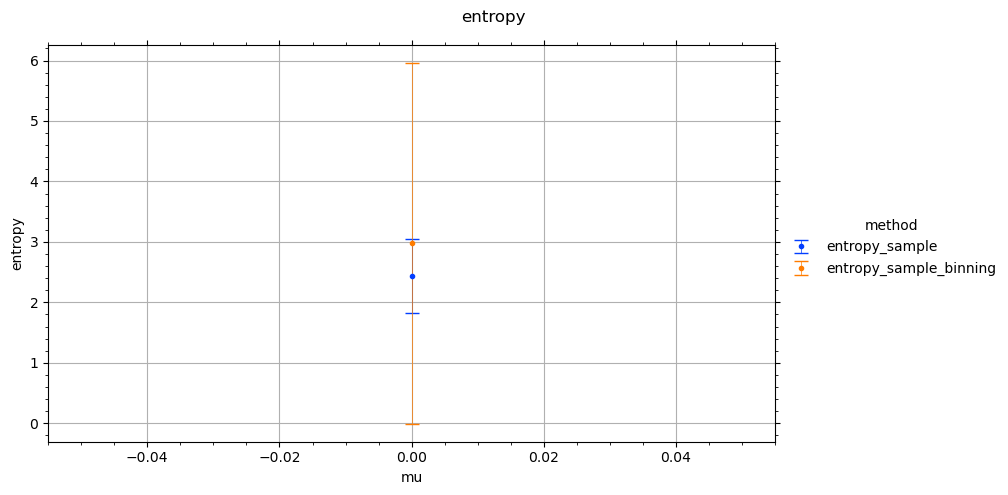

T = 149.87944878472223


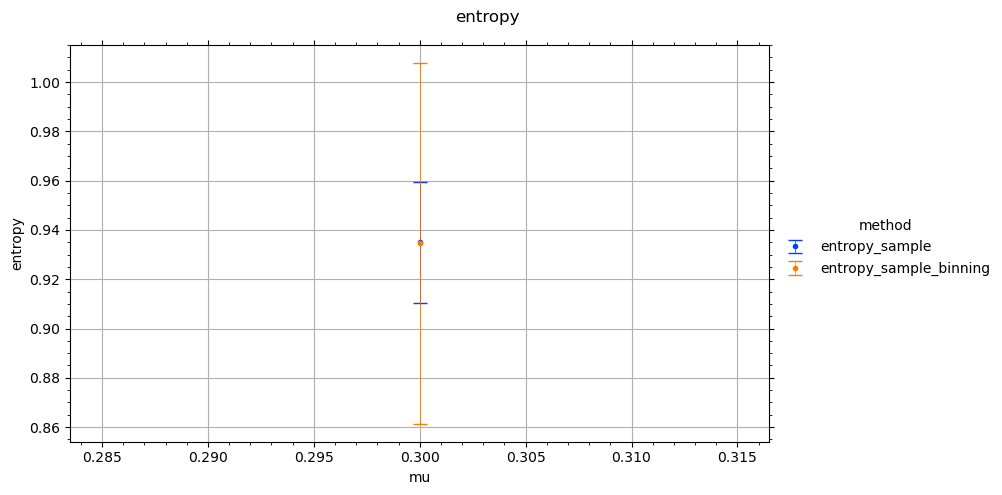

T = 159.0557415674603


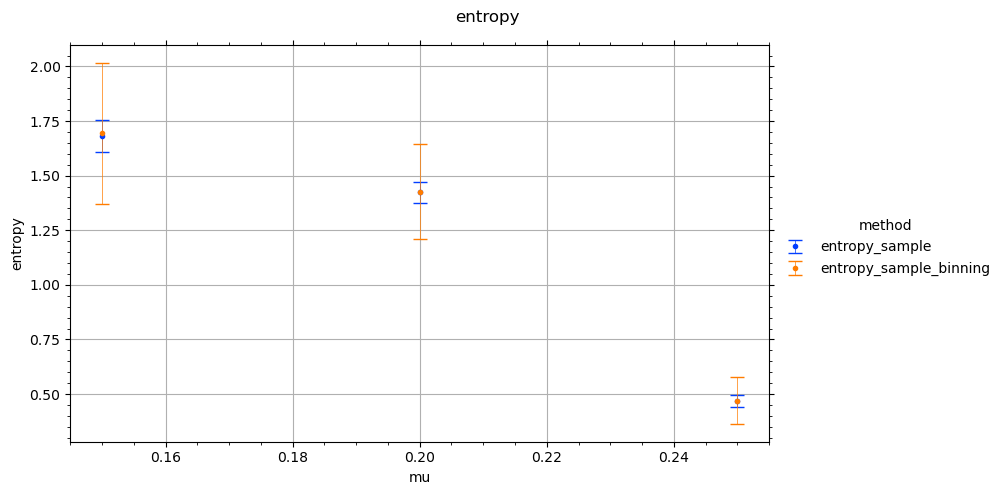

T = 164.70269097222223


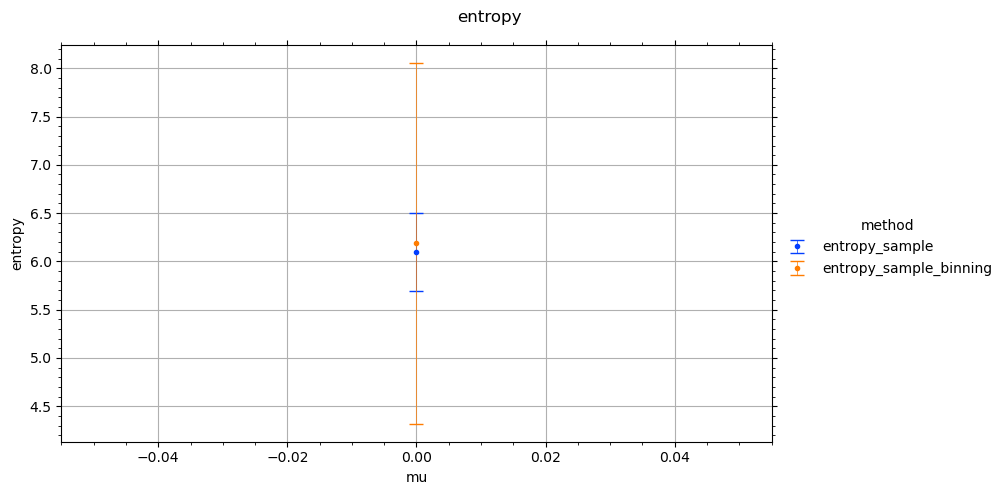

T = 179.07674400252526


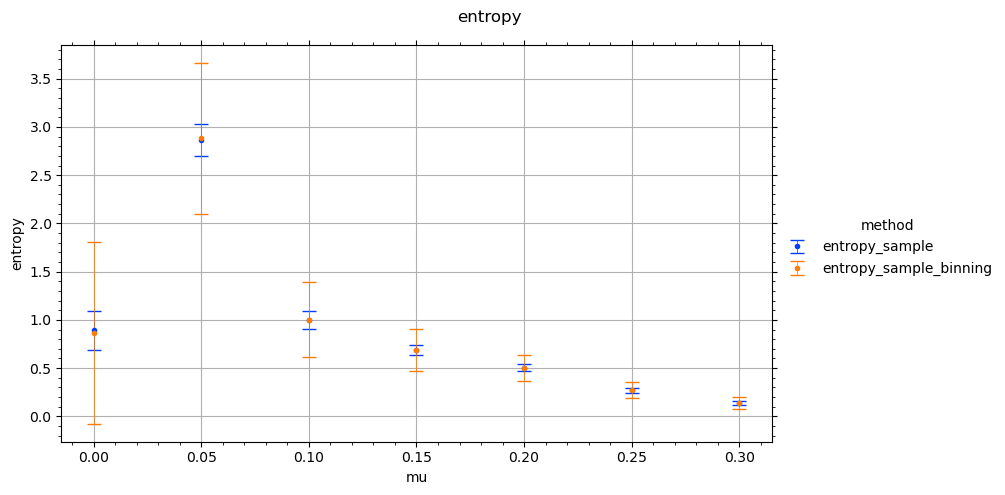

T = 196.20582386363637


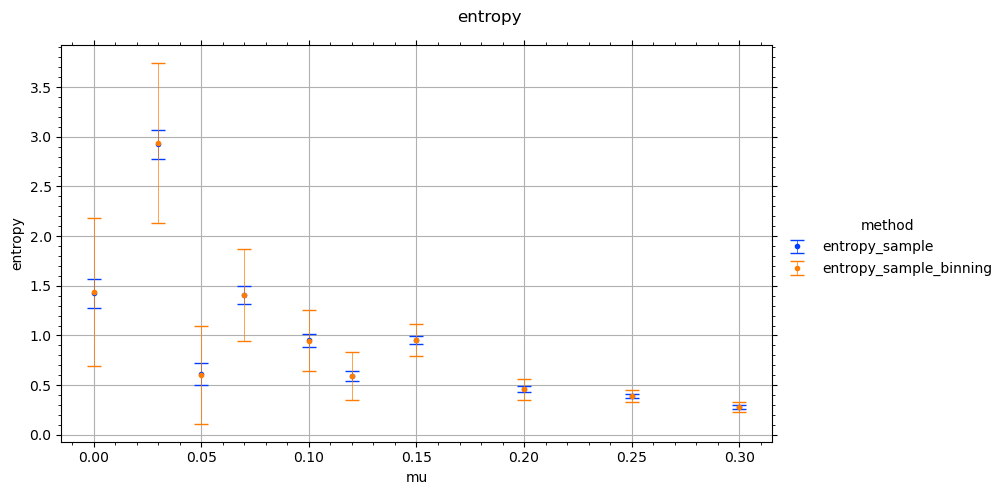

T = 216.9683449074074


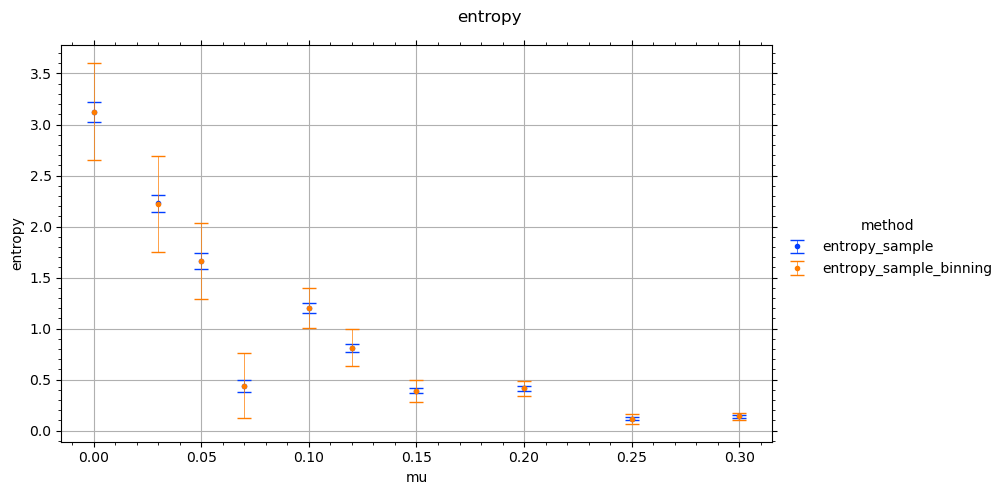

T = 242.66196469907408


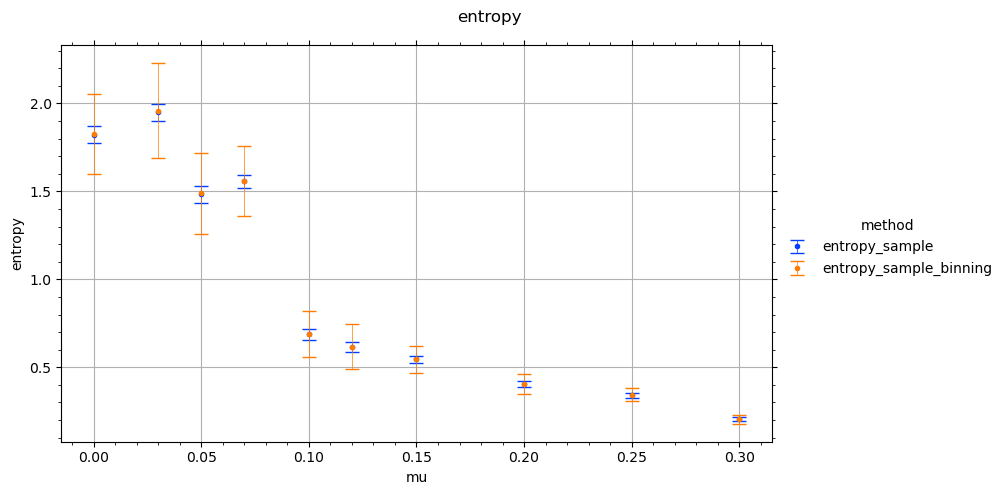

T = 275.2887834821429


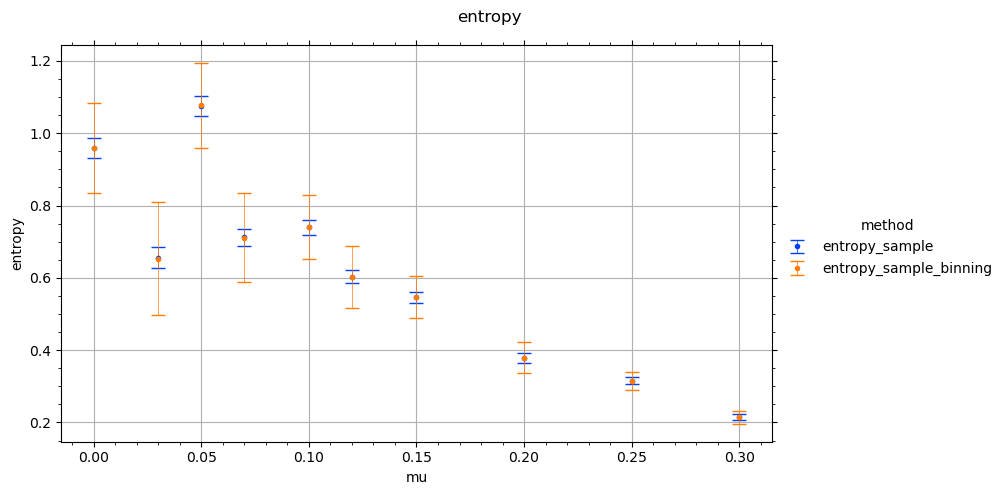

T = 318.1114831349206


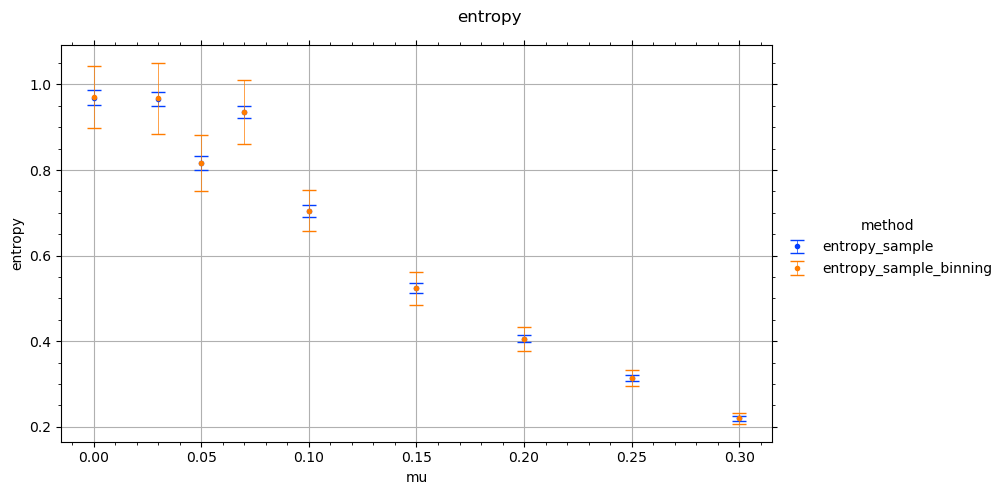

T = 376.83975694444445


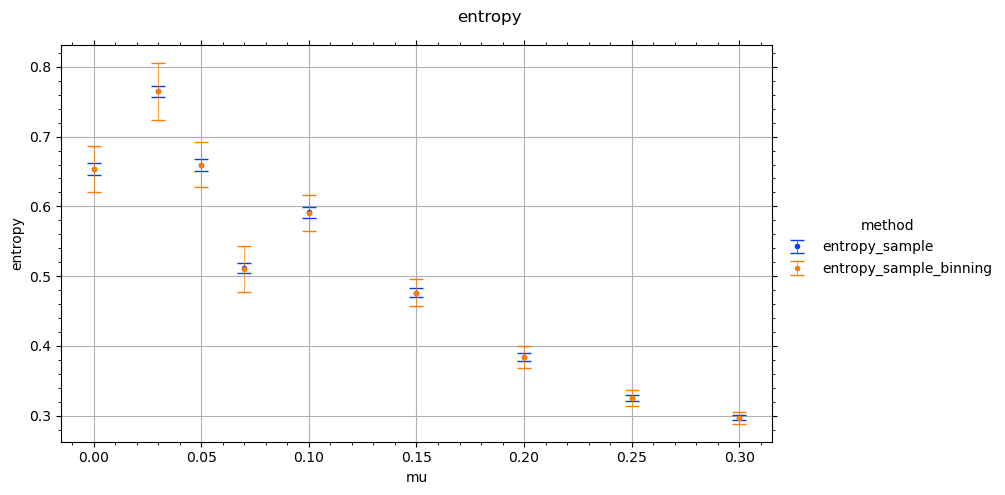

T = 462.48515625000005


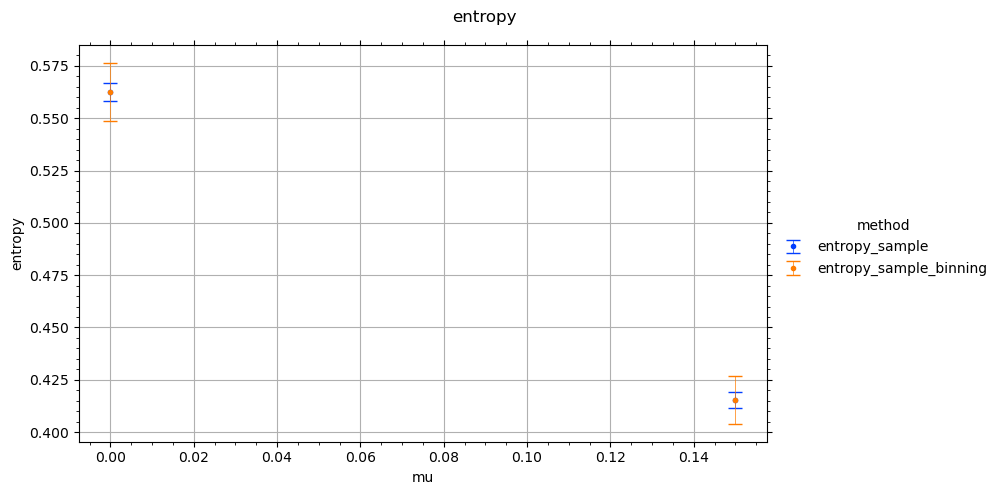

T = 599.5177951388889


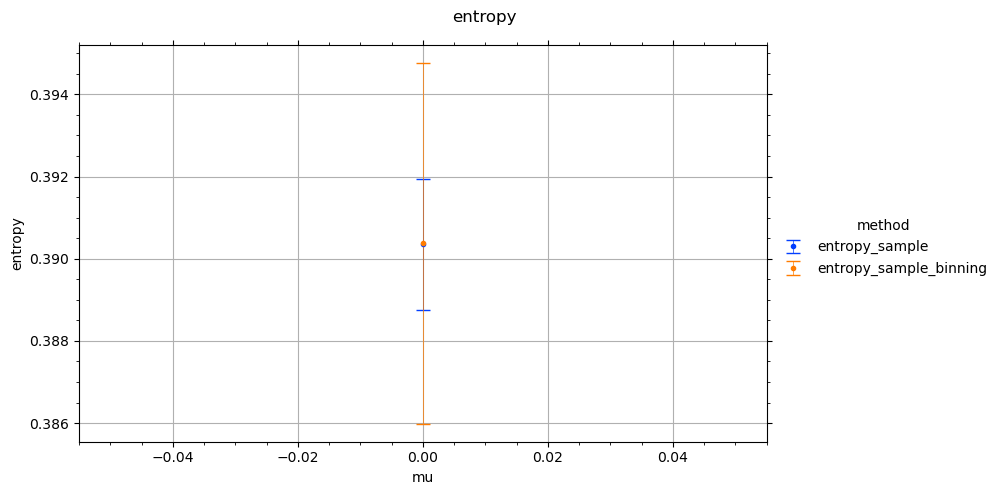

T = 856.4539930555557


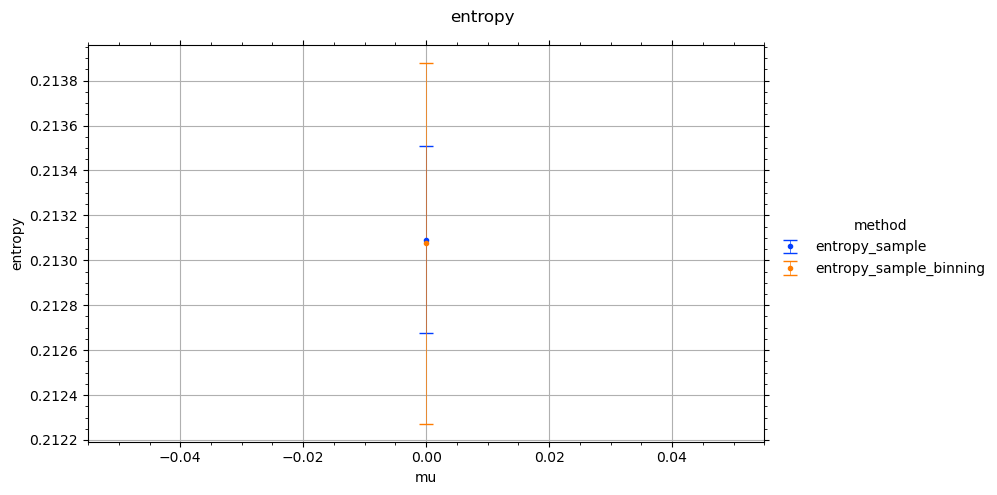

In [57]:
for T in df_entropy_comparison['T'].unique():
    print(f'T = {T}')
    plots.plot_potential_single(df_entropy_comparison[df_entropy_comparison['T'] == T], 'mu', 'entropy', 'method', 'mu', 'entropy', 'entropy', f'../../images/potential/su2/qc2dstag/', 'polyakov loop', True, err='err')